# 실험 계획

## 1. Objective
**COCO-pretrained SSD300-VGG16을 feature extraction 방식(backbone freeze, head만 학습)으로 head bounding box detection에 올바르게 전이학습한다.**
비교 실험은 하지 않는다. 학습은 **Phase 1 (FE) 1회**만 한다. 여건이 되면 같은 환경에서 Phase 2 (FT)를 추가해 FE vs FT를 비교한다. 모델 성능을 끝까지 끌어올리는 데에 집중하기보다는 SSD를 파인튜닝하는 경험을 토대로 모델 전이학습 코드 구현 방식과 주의점을 블로그에 정리하는 것을 목적으로 한다. 

| Item | Definition |
|---|---|
| Task | Head bounding box detection (README: `xmls/` — *Head bounding box annotations in PASCAL VOC Format*) |
| Model | `torchvision.models.detection.ssd300_vgg16` |
| Pretrained weights | `SSD300_VGG16_Weights.COCO_V1` (= `DEFAULT`, the weights used in `baseline.ipynb`). COCO box mAP 25.1 |
| Transfer strategy | **Feature extraction (FE)**: freeze the backbone, train the detection head only |
| Detection labels | **SPECIES** from XML `<name>`: background, `cat`, `dog` → **3 classes** |
| Goal | A correctly configured FE run, evaluated with standard COCO-style mAP and IoU |

## 2. Phases
| Phase | Run ID | Trainable scope | Status |
|---|---|---|---|
| **1** | **FE** | Detection head only (`model.head`) | **Required** — train once |
| 2 | FT | All parameters (backbone + head) | Optional — only if time / GPU quota allows. Same environment as FE (§4) |

## 3. Fixes from `baseline.ipynb`
| # | Baseline | Problem | This plan |
|---|---|---|---|
| 1 | `model.head.classification_head.num_classes = num_classes` | Only adds an unused attribute. The conv layers and reshape still use `num_columns = 91` → head stays **COCO 91-class**; `dog` / `cat` labels 1, 2 are trained on COCO's `person` / `bicycle` slots | **Replace** the classification head with a new `SSDClassificationHead(..., num_classes=3)` (§5) |
| 2 | `StepLR` created, `lr_scheduler.step()` never called | LR stays constant at 1e-3 | Linear warmup → cosine decay, stepped **per iteration** (§6) |
| 3 | No augmentation (`ToImage` + `ToDtype` only) | Overfitting risk | EDA §9 augmentation (§6) |
| 4 | `evaluate_model`: `sklearn.average_precision_score(TP flags, scores)` | Ranks predictions only; missed GT (recall) is ignored and images without predictions are skipped → **inflated mAP (0.99)**; IoU 0.5 only | `torchmetrics.detection.MeanAveragePrecision` (COCO-style) (§7) |
| 5 | Random 70 / 30 split of `trainval.txt` (comment says 80 / 20) | No stratification, no test split with GT | CLASS-ID stratified 70 / 15 / 15 (§4) |
| 6 | `DataLoader(num_workers=0)`, JPEG decode + XML parse every epoch | ~1 min 45 s per epoch; train ≈ val speed → CPU-bound | RAM image cache (longest side 448) + `num_workers=2` (§4) |
| 7 | No `requires_grad` setting | All layers trained (implicit full FT) | Freeze explicitly (§5) |

## 4. Environment (fixed for Phase 1 and Phase 2)
| Category | Setting | Source |
|---|---|---|
| Dataset | `trainval.txt` images with an XML (3,671) + images not in `list.txt` but with an XML and no hash duplicate (`Egyptian_Mau_129`, `Siamese_203`) = **3,673 images** | EDA §2 |
| Split | Stratified by **CLASS-ID** (37), train / val / test = **70 / 15 / 15** (≈ 2,571 / 551 / 551), `SEED = 42`, saved once and reused | EDA §2 |
| Official `test.txt` | No XML (0 / 3,669) → **qualitative visualization only**, not used for metrics | EDA §2 |
| Image loading | `PIL.Image.open(...).convert("RGB")`, **once** when the image cache is built | EDA §7-1 |
| Image cache | Built once per session before training: decode → downscale so the **longest side = 448** (aspect ratio kept, no upscaling of smaller images) → store as `uint8` CHW tensors in RAM (≈ 1.6 GB for 3,673 images). Boxes are scaled by the same factor and cached with the image. Saved as one `.pt` file on local disk / Drive → reloaded after a reconnect instead of re-decoding | Baseline log: train ≈ val ≈ 25 img/s → CPU decoding is the bottleneck |
| Why 448, not 300 | Crop + zoom augmentation enlarges a crop back to 300 × 300. Caching at 300 would upsample the crop and blur it; 448 leaves headroom (crop `min_ratio=0.5` → 224 px side → close to 300) | EDA §9 |
| Augmentation input | `transforms.v2` applied to the cached `uint8` tensor + `tv_tensors.BoundingBoxes` (train only), then `ToDtype(float32, scale=True)` | EDA §9 |
| Dataset output | Image: `float32` tensor `(3, H, W)`, values in `[0, 1]`, at the cached size (longest side ≤ 448). Target: `{"boxes": tv_tensors.BoundingBoxes(format="XYXY", canvas_size=(H, W)), "labels": int64}` in the same pixel coordinates | — |
| DataLoader | `num_workers=2`, `pin_memory=True`, `persistent_workers=True` (Colab: 2 vCPUs). Workers share the RAM cache (fork) | — |
| Resize | Inside the model: fixed **300 × 300**, direct resize (aspect ratio not preserved). Runs on GPU. Predicted boxes are mapped back to the cached size, so GT and predictions share one coordinate system for metrics | EDA §7-2 |
| Normalization | Inside the model (torchvision default for COCO weights): `image_mean=[0.48235, 0.45882, 0.40784]`, `image_std=[1/255]*3` | — |
| Hardware | Colab T4 (16 GB), AMP (fp16) | — |
| Checkpoint | **Every 3 epochs** + the final epoch: resume checkpoint (model, optimizer, scheduler, scaler, epoch, best val mAP, RNG states) → resumable. Written to the VM's local disk first, then copied to Google Drive. Frequent writes can pile up in Drive's asynchronous sync, and anything not yet synced is lost if the Colab VM stops | — |
| Best model | When val mAP@[0.5:0.95] improves, the model weights are saved to **local disk only** (overwrite). Copied to Drive together with the next 3-epoch checkpoint | §6 Checkpoint selection |

## 5. Model Configuration (Phase 1: FE)
| Component | Init | Trainable | # Params | Note |
|---|---|---|---|---|
| `backbone` (VGG16 conv1–conv5 + L2Norm + extra layers) | COCO | **Frozen** (`requires_grad=False`) | 22,943,936 | VGG16 has no BatchNorm → no BN statistics issue when frozen |
| `head.regression_head` | COCO | ✓ | 534,648 | Box regression is class-agnostic → COCO weights reused as is |
| `head.classification_head` | **New** (Xavier) | ✓ | 400,986 | `SSDClassificationHead(in_channels=[512, 1024, 512, 256, 256, 256], num_anchors=[4, 6, 6, 6, 4, 4], num_classes=3)` |
| `anchor_generator` | torchvision default | — | — | Scales 0.07–1.05, aspect ratios {1, 2, 1/2} (+ {3, 1/3} on maps 2–4); head scale median 0.40 is covered (EDA §8) |
| **Total** | | **935,634 trainable / 23,879,570** | | ≈ 3.9 % trainable |

- Optimizer receives only `[p for p in model.parameters() if p.requires_grad]`.
- A sanity check before training: `assert` the classification output has 3 columns (`(N, 8732, 3)`), and print trainable / total parameter counts.

## 6. Training Configuration
| Category | Setting | Rationale |
|---|---|---|
| Train augmentation | Horizontal flip (p=0.5) → Random crop containing all boxes + zoom (`min_ratio=0.5`) → Brightness / contrast jitter (±0.3). **No rotation** | EDA §9 (rotation inflates the box: 10° → +35 % area) |
| Val / test augmentation | None | — |
| Optimizer | SGD, momentum 0.9, weight decay 5e-4 | Same family as baseline |
| Batch size | 16 | Fits T4 with AMP |
| Initial LR | 2e-3 | torchvision reference recipe for SSD300 (LR 0.002); the frozen backbone cannot be damaged by a large step |
| LR schedule | Linear warmup (1 epoch, from 0.1 × LR) → cosine decay to 0, stepped per iteration | Fixes baseline #2 |
| Epochs | Max **30**; early stopping on val mAP@[0.5:0.95] (patience 7) | Only ~0.9 M parameters are trained → converges faster than full FT |
| Checkpoint selection | Best val mAP@[0.5:0.95] | — |
| Inference settings | torchvision default: score threshold 0.01, NMS IoU 0.45, top-k 400, max 200 detections / image | — |

## 7. Metrics
| Metric | Role | Note |
|---|---|---|
| **mAP@[0.5:0.95]** | **Primary** | COCO-style; sensitive to localization quality |
| mAP@0.5 | Secondary | PASCAL VOC criterion |
| AP (`cat`), AP (`dog`) | Secondary | `class_metrics=True`; SPECIES imbalance Cat : Dog = 1 : 2.1 (EDA §4) |
| Mean IoU | Secondary | Per image: top-1 prediction vs. GT box |
| Learning curves | Diagnostic | Train loss (cls / reg), val mAP per epoch |

- All metrics use `torchmetrics.detection.MeanAveragePrecision` (+ `torchvision.ops.box_iou` for mean IoU).
- Final numbers are reported **once** on the test split with the best checkpoint.

## 8. Analysis Plan (Phase 1)
| Analysis | Breakdown | Purpose |
|---|---|---|
| Overall | All metrics in §7 on the test split | Final performance of the FE model |
| By SPECIES | `cat` vs `dog` | Effect of SPECIES imbalance |
| By head scale | `scale = sqrt(box area / image area)`: small < 0.25, medium 0.25–0.5, large > 0.5 | Where FE fails (EDA §8) |
| Learning curves | Train loss, val mAP@[0.5:0.95] | Convergence / overfitting check |
| Failure cases | Top-k lowest-IoU test images | Error types: missed head, loose box, wrong SPECIES |
| Qualitative | Official `test.txt` images with predicted boxes | README requirement: test with the provided test file |

## 9. Phase 2 (Optional): FE vs FT
| Item | Setting |
|---|---|
| Change from Phase 1 | **Only the trainable scope**: unfreeze the backbone (all 23,879,570 parameters trainable) |
| Kept identical | Everything in §4, §6 (augmentation, optimizer, LR, schedule, epochs, batch, seed) and §7 |
| Comparison table | mAP@[0.5:0.95], mAP@0.5, AP `cat` / `dog`, mean IoU, # trainable params, time / epoch, peak GPU memory |
| Question | How much does adapting the COCO backbone to head detection add over training the head only? |

## 10. Known Limitations
| Limitation | Impact |
|---|---|
| Single run, single seed | No variance estimate; small differences in Phase 2 (< ~1 pt) cannot be called significant |
| Fixed LR (no sweep) | 2e-3 may not be optimal for FE; in Phase 2 the same LR is kept on purpose (environment fixed), so it may favor one strategy |
| COCO `cat` / `dog` are whole-body boxes, not heads | The frozen backbone features are not tuned for heads → FE may localize less tightly (mAP@[0.5:0.95]) |
| Official `test.txt` has no GT | Quantitative test numbers come from our own 15 % split, not the official test set |
| Direct resize to 300 × 300 | Aspect ratio distortion (box aspect ratio median 1.01 → 0.85 after resize, EDA §8) |

# 실험 코드

위 계획(§1~§10)을 그대로 코드로 옮긴다. 노트북은 아래 순서로 진행한다.

| Step | 내용 | 계획 근거 |
|---|---|---|
| A | 환경 설정: Colab / 로컬 자동 감지, 패키지, 경로, device | §4 Hardware |
| B | 실험 설정(config): 모든 하이퍼파라미터를 한곳에서 관리 | §4, §6 |
| C | 데이터: 준비(로컬: Kaggle / Colab: Drive의 `data.tar` → VM) → 레코드 구성 → stratified split → 이미지 캐시 → Dataset / DataLoader | §3 #3·#5·#6, §4 |
| D | 모델: COCO SSD300 로드 → 분류 head 교체 → backbone freeze → sanity check | §3 #1·#7, §5 |
| E | 학습: optimizer, warmup + cosine, AMP, 체크포인트, early stopping | §3 #2, §4, §6 |
| F | 평가·분석: test split 지표, SPECIES별, head scale별, 학습 곡선, 실패 사례, 공식 `test.txt` | §7, §8 |
| G | (선택) Phase 2: Full fine-tuning과 비교 | §9 |

**코드 작성 원칙**
- 함수는 전역 변수를 읽지 않는다. 필요한 값은 모두 인자로 받는다. 전역 변수는 셀 맨 아래의 "실행" 부분에서만 만든다.
- 하이퍼파라미터는 Step B의 config 객체에만 둔다. Phase 2는 config 한 줄만 바꿔서 같은 함수로 실행한다.
- 같은 코드가 Colab과 로컬(macOS / Linux)에서 모두 돌아가도록 실행 환경을 자동으로 감지한다.

## A. 환경 설정

### A-1. 실행 환경 감지와 패키지 확인
Colab과 로컬은 네 가지가 다르다. 이 차이를 `RuntimeInfo` 하나에 모아 두고, 이후 코드는 이 객체만 본다.

| 항목 | Colab | 로컬 |
|---|---|---|
| 작업 디렉터리 (데이터, 캐시, 로컬 체크포인트) | `/content/mission7_FaceObjectDetection` (VM 로컬 디스크, 빠름. VM이 꺼지면 사라짐) | 노트북이 있는 폴더 |
| 영구 저장소 | Google Drive `MyDrive/CodeIT/Colab/mission7_FaceObjectDetection` | 없음 (로컬 디스크 자체가 영구 저장소) |
| 데이터 원본 | 영구 저장소의 `data.tar` 하나. 로컬에서 만들어 올려 두고, 세션 시작 시 VM으로 복사해 푼다 (C-1) | Kaggle에서 `kagglehub`로 받는다 |
| DataLoader worker | 2개 (Linux `fork` → worker가 RAM 캐시를 복사 없이 공유) | macOS / Windows는 0개 (`spawn` 방식은 노트북에 정의한 클래스를 worker에서 import하지 못한다) |

`torchmetrics`(mAP 계산)와 `pycocotools`(torchmetrics의 COCO 평가 백엔드)가 없으면 설치한다.

In [1]:
import importlib.util
import os
import platform
import subprocess
import sys
from dataclasses import dataclass
from pathlib import Path
from typing import Optional

PROJECT_NAME = "mission7_FaceObjectDetection"


@dataclass(frozen=True)
class RuntimeInfo:
    """노트북이 실행 중인 환경. 경로·worker 수 등 환경에 따라 달라지는 값의 출처."""
    is_colab: bool
    os_name: str                   # "Linux" / "Darwin" / "Windows"
    work_dir: Path                 # 데이터·캐시·로컬 체크포인트를 두는 빠른 로컬 디스크
    persistent_dir: Optional[Path]  # VM이 꺼져도 남는 저장소 (Colab: Google Drive). 로컬이면 None

    @property
    def supports_fork_workers(self) -> bool:
        """DataLoader worker를 fork로 띄울 수 있는지 (Linux만 기본 start method가 fork)."""
        return self.os_name == "Linux"


def detect_runtime(project_name: str, drive_mount_point: Path = Path("/content/drive")) -> RuntimeInfo:
    """Colab 여부를 감지하고, 환경에 맞는 작업 디렉터리와 영구 저장소 경로를 정한다."""
    is_colab = "google.colab" in sys.modules
    if is_colab:
        work_dir = Path("/content") / project_name
        persistent_dir = drive_mount_point / "MyDrive" / "CodeIT" / "Colab" / project_name
    else:
        work_dir = Path.cwd()
        persistent_dir = None
    return RuntimeInfo(is_colab=is_colab, os_name=platform.system(),
                       work_dir=work_dir, persistent_dir=persistent_dir)


def mount_google_drive(drive_mount_point: Path = Path("/content/drive")) -> None:
    """Colab에서만 Google Drive를 마운트한다."""
    from google.colab import drive  # Colab에만 있는 모듈이라 함수 안에서 import
    drive.mount(str(drive_mount_point))


def ensure_packages(requirements: dict[str, str]) -> None:
    """{import 이름: pip 패키지 이름} 중 import되지 않는 패키지를 pip로 설치한다."""
    missing = [pip_name for module_name, pip_name in requirements.items()
               if importlib.util.find_spec(module_name) is None]
    if not missing:
        print("필요한 패키지가 모두 설치되어 있다.")
        return
    print("설치:", missing)
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    except (subprocess.CalledProcessError, FileNotFoundError) as error:
        # uv로 만든 venv처럼 pip가 없는 환경이면 직접 설치하도록 안내한다
        raise RuntimeError(f"자동 설치 실패. 터미널에서 직접 설치: pip install {' '.join(missing)}") from error


# ---- 실행 ----
RUNTIME = detect_runtime(PROJECT_NAME)
if RUNTIME.is_colab:
    mount_google_drive()
    RUNTIME.persistent_dir.mkdir(parents=True, exist_ok=True)

requirements = {"torchmetrics": "torchmetrics", "pycocotools": "pycocotools", "sklearn": "scikit-learn"}
if not RUNTIME.is_colab:
    requirements["kagglehub"] = "kagglehub"  # 로컬에서만 Kaggle에서 데이터를 받는다
ensure_packages(requirements)
print(RUNTIME)

Mounted at /content/drive
설치: ['torchmetrics']
RuntimeInfo(is_colab=True, os_name='Linux', work_dir=PosixPath('/content/mission7_FaceObjectDetection'), persistent_dir=PosixPath('/content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection'))


### A-2. 라이브러리 import와 device 선택
- device는 CUDA → Apple MPS → CPU 순으로 고른다.
- AMP(fp16 autocast + `GradScaler`)는 CUDA에서만 켠다. 계획(§4)의 T4 환경 기준이다.
- 입력 크기가 300 × 300으로 고정이라 `cudnn.benchmark`를 켜 두면 첫 iteration 이후 가장 빠른 conv 알고리즘을 재사용한다.

In [2]:
import json
import math
import random
import shutil
import time
import xml.etree.ElementTree as ET
from dataclasses import asdict, field, replace

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from IPython.display import display
from PIL import Image
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchmetrics.detection import MeanAveragePrecision
from torchvision import tv_tensors
from torchvision.models.detection import SSD300_VGG16_Weights, ssd300_vgg16
from torchvision.models.detection import _utils as detection_utils
from torchvision.models.detection.ssd import SSD, SSDClassificationHead
from torchvision.ops import box_iou
from torchvision.transforms import v2
from torchvision.transforms.v2 import functional as TF
from tqdm.auto import tqdm


def select_device() -> torch.device:
    """사용 가능한 가장 빠른 device를 고른다."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def seed_everything(seed: int) -> None:
    """python / numpy / torch(CPU·CUDA) 난수 시드를 한 번에 고정한다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ---- 실행 ----
DEVICE = select_device()
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    print("GPU:", torch.cuda.get_device_name(0))
print(f"device={DEVICE}, torch={torch.__version__}, torchvision={torchvision.__version__}")

GPU: Tesla T4
device=cuda, torch=2.11.0+cu130, torchvision=0.26.0+cu130


## B. 실험 설정 (config)

계획 §4(환경)와 §6(학습)의 값을 dataclass로 묶는다. 영역별로 나눈 이유는 다음과 같다.
- **읽기 쉽다**: 어떤 값이 데이터·증강·모델·학습 중 어디에 속하는지 이름만으로 보인다.
- **Phase 2 비교가 안전하다**: `replace(config, run_id="FT", model=replace(config.model, trainable_scope="all"))`처럼 바꿀 값만 명시하고 나머지는 그대로 물려받는다. "FE와 FT는 학습 범위만 다르다"(§9)를 코드로 보장한다.
- `frozen=True`로 만들어 실행 중에 값이 몰래 바뀌지 않게 한다.

`SMOKE_TEST = True`로 두면 split마다 32장, 2 epoch만 돌려 파이프라인 전체가 오류 없이 끝나는지 빠르게 확인한다. GPU 할당량을 쓰기 전에 한 번 돌려 보는 용도다.

In [3]:
@dataclass(frozen=True)
class PathConfig:
    """데이터와 산출물 경로."""
    data_dir: Path                         # 학습 코드가 읽는 데이터 위치 (항상 로컬 디스크)
    local_output_dir: Path                 # 캐시·체크포인트를 먼저 쓰는 로컬 디스크
    persistent_output_dir: Optional[Path]  # 로컬 산출물을 복사해 둘 영구 저장소 (Colab: Drive)
    persistent_data_archive: Optional[Path] = None  # Colab: Drive에 올려 둔 데이터 묶음 (data.tar)

    @property
    def image_dir(self) -> Path:
        return self.data_dir / "images" / "images"

    @property
    def annotation_dir(self) -> Path:
        return self.data_dir / "annotations" / "annotations"

    @property
    def xml_dir(self) -> Path:
        return self.annotation_dir / "xmls"


@dataclass(frozen=True)
class DataConfig:
    """데이터 구성·분할·캐시·로딩 설정 (계획 §4)."""
    kaggle_handle: str = "zippyz/cats-and-dogs-breeds-classification-oxford-dataset"
    class_names: tuple[str, ...] = ("background", "cat", "dog")  # index = 모델 label. 0은 background 고정
    # list.txt에 없지만 XML과 이미지가 있고 해시 복사본도 아닌 2장 (EDA §2)
    extra_images: tuple[str, ...] = ("Egyptian_Mau_129", "Siamese_203")
    split_ratios: tuple[float, float, float] = (0.70, 0.15, 0.15)  # train / val / test
    cache_max_side: int = 448             # 이미지 캐시의 긴 변 길이 (계획 §4 "Why 448, not 300")
    cache_to_persistent: bool = True      # 캐시 .pt 파일을 영구 저장소에도 복사할지
    batch_size: int = 16
    eval_batch_size: int = 32
    num_workers: int = 2
    smoke_test_images_per_split: Optional[int] = None  # None이면 전체 사용


@dataclass(frozen=True)
class AugmentationConfig:
    """train 전용 증강 (계획 §6, EDA §9). 회전은 쓰지 않는다."""
    hflip_prob: float = 0.5
    crop_min_ratio: float = 0.5   # 크롭 영역의 가로·세로가 원본의 최소 몇 배인지
    brightness: float = 0.3
    contrast: float = 0.3


@dataclass(frozen=True)
class ModelConfig:
    """모델 구성 (계획 §5)."""
    trainable_scope: str = "head"   # "head" = Feature extraction (Phase 1), "all" = Full fine-tuning (Phase 2)
    image_size: int = 300           # SSD300 입력 크기 (모델 내부 transform이 리사이즈)
    expected_num_anchors: int = 8732


@dataclass(frozen=True)
class TrainConfig:
    """optimizer·스케줄·종료 조건·체크포인트 (계획 §4, §6)."""
    learning_rate: float = 2e-3
    momentum: float = 0.9
    weight_decay: float = 5e-4
    warmup_epochs: int = 1
    warmup_start_factor: float = 0.1  # warmup 시작 LR = learning_rate × 이 값
    max_epochs: int = 30
    early_stopping_patience: int = 7
    checkpoint_every_n_epochs: int = 3
    use_amp: bool = True              # CUDA일 때만 실제로 켜진다


@dataclass(frozen=True)
class ExperimentConfig:
    """한 번의 학습 run을 정의하는 전체 설정."""
    run_id: str
    seed: int
    paths: PathConfig
    data: DataConfig = field(default_factory=DataConfig)
    augmentation: AugmentationConfig = field(default_factory=AugmentationConfig)
    model: ModelConfig = field(default_factory=ModelConfig)
    train: TrainConfig = field(default_factory=TrainConfig)


def build_base_config(runtime: RuntimeInfo, smoke_test: bool) -> ExperimentConfig:
    """실행 환경에 맞춘 Phase 1 (FE) 설정을 만든다."""
    paths = PathConfig(
        data_dir=runtime.work_dir / "data",
        local_output_dir=runtime.work_dir / "outputs",
        persistent_output_dir=None if runtime.persistent_dir is None else runtime.persistent_dir / "outputs",
        persistent_data_archive=None if runtime.persistent_dir is None else runtime.persistent_dir / "data.tar",
    )
    data = DataConfig(num_workers=2 if runtime.supports_fork_workers else 0)
    train = TrainConfig()
    run_id = "FE"
    if smoke_test:
        data = replace(data, smoke_test_images_per_split=32, cache_to_persistent=False)
        train = replace(train, max_epochs=2, checkpoint_every_n_epochs=1)
        run_id = "FE_smoke"
    return ExperimentConfig(run_id=run_id, seed=42, paths=paths, data=data, train=train)


def config_to_frame(config: ExperimentConfig) -> pd.DataFrame:
    """config를 (section, name, value) 표로 펼친다."""
    rows = [{"section": "run", "name": key, "value": getattr(config, key)} for key in ("run_id", "seed")]
    for section in ("paths", "data", "augmentation", "model", "train"):
        for name, value in asdict(getattr(config, section)).items():
            rows.append({"section": section, "name": name, "value": str(value)})
    return pd.DataFrame(rows)


# ---- 실행 ----
SMOKE_TEST = False  # True: split마다 32장, 2 epoch로 파이프라인만 빠르게 점검

CONFIG = build_base_config(RUNTIME, smoke_test=SMOKE_TEST)
for directory in (CONFIG.paths.local_output_dir, CONFIG.paths.persistent_output_dir):
    if directory is not None:
        directory.mkdir(parents=True, exist_ok=True)
display(config_to_frame(CONFIG))

,section,name,value
0,run,run_id,FE
1,run,seed,42
2,paths,data_dir,/content/mission7_FaceObjectDetection/data
3,paths,local_output_dir,/content/mission7_FaceObjectDetection/outputs
4,paths,persistent_output_dir,/content/drive/MyDrive/CodeIT/Colab/mission7_F...
5,paths,persistent_data_archive,/content/drive/MyDrive/CodeIT/Colab/mission7_F...
6,data,kaggle_handle,zippyz/cats-and-dogs-breeds-classification-oxf...
7,data,class_names,"('background', 'cat', 'dog')"
8,data,extra_images,"('Egyptian_Mau_129', 'Siamese_203')"
9,data,split_ratios,"(0.7, 0.15, 0.15)"


### B-1. 파일 저장 헬퍼
체크포인트·캐시·분할 파일은 모두 **로컬 디스크에 먼저 쓰고, 필요할 때만 영구 저장소(Drive)로 복사**한다 (계획 §4 Checkpoint).
- 쓰는 도중에 VM이 멈추면 파일이 반쯤 쓰인 채로 남는다. 그래서 임시 파일에 다 쓴 뒤 `os.replace`로 이름을 바꾼다. 이름 바꾸기는 한 번에 끝나므로 "완전한 옛 파일" 또는 "완전한 새 파일"만 남는다.
- 로컬 환경에서는 영구 저장소가 `None`이므로 복사를 건너뛴다.

In [ ]:
def atomic_torch_save(obj, path: Path) -> None:
    """임시 파일에 저장한 뒤 이름을 바꿔, 저장 도중 중단돼도 깨진 파일이 남지 않게 한다."""
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp_path = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp_path)
    os.replace(tmp_path, path)


def atomic_copy(src: Path, dst: Path) -> None:
    """src를 dst로 복사한다. 복사가 끝난 뒤에만 dst 이름이 생긴다."""
    dst.parent.mkdir(parents=True, exist_ok=True)
    tmp_path = dst.with_name(dst.name + ".tmp")
    shutil.copyfile(src, tmp_path)
    os.replace(tmp_path, dst)


def copy_to_persistent(local_path: Path, persistent_dir: Optional[Path]) -> None:
    """로컬 파일을 영구 저장소의 같은 이름으로 복사한다. 영구 저장소가 없으면 아무것도 하지 않는다."""
    if persistent_dir is not None and local_path.exists():
        atomic_copy(local_path, persistent_dir / local_path.name)


def find_existing(filename: str, directories: list[Optional[Path]]) -> Optional[Path]:
    """directories를 순서대로 보며 filename이 처음 존재하는 경로를 돌려준다."""
    for directory in directories:
        if directory is not None and (directory / filename).exists():
            return directory / filename
    return None


def save_json(obj, filename: str, local_dir: Path, persistent_dir: Optional[Path]) -> Path:
    """JSON을 로컬에 저장하고 영구 저장소에도 복사한다."""
    local_dir.mkdir(parents=True, exist_ok=True)
    path = local_dir / filename
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2))
    copy_to_persistent(path, persistent_dir)
    return path

## C. 데이터

### C-1. 데이터 준비
학습 코드는 **항상 로컬 디스크의 `data_dir`** 에서 데이터를 읽는다. 실행 환경마다 다른 것은 데이터를 그 자리로 가져오는 방법뿐이다.

| 환경 | 방법 |
|---|---|
| 로컬 | `data_dir`에 데이터가 없으면 `kagglehub`로 받는다 |
| Colab | Drive의 `data.tar`를 세션 시작 시 VM 로컬 디스크(`/content/...`)로 복사해 푼다. Kaggle에서는 받지 않는다 |

**Colab에서 tar 파일 하나로 옮기는 이유**: Drive는 네트워크 파일 시스템이라 파일을 하나 열 때마다 왕복 지연이 생긴다. 작은 파일 1만여 개(JPEG 7,390장, XML 3,686개)를 Drive에서 바로 읽거나 하나씩 복사하면 매우 느리다. 큰 파일 하나를 VM으로 복사해 풀면 그 뒤로는 로컬 디스크 속도로 읽는다.

**`data.tar` 만들기 (로컬에서 한 번)**: 이 실험이 읽는 항목만 묶는다. `trimaps`(segmentation 마스크)는 쓰지 않으므로 뺀다. 만든 파일을 Drive의 `MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/`에 올린다.
`COPYFILE_DISABLE=1`은 macOS 전용 옵션이다. 이게 없으면 macOS `tar`가 파일마다 `._파일명` 메타데이터 파일을 끼워 넣어 파일 수가 두 배가 된다.
```bash
cd data && COPYFILE_DISABLE=1 tar -cf data.tar images/images annotations/annotations/xmls \
  annotations/annotations/list.txt annotations/annotations/trainval.txt annotations/annotations/test.txt
```

커널만 재시작한 경우에는 VM에 이미 풀어 둔 데이터(완료 표시 파일 `.staged`)를 그대로 쓴다.

In [5]:
import tarfile

DATASET_ITEMS = (  # data_dir 기준 상대 경로. 이 실험이 읽는 항목만 둔다 (data.tar에 넣는 항목과 같다)
    "images/images",
    "annotations/annotations/xmls",
    "annotations/annotations/list.txt",
    "annotations/annotations/trainval.txt",
    "annotations/annotations/test.txt",
)
STAGED_MARKER = ".staged"  # VM으로 가져오기가 끝까지 성공했다는 표시


def is_dataset_complete(data_dir: Path, items: tuple[str, ...]) -> bool:
    """data_dir에 필요한 항목이 모두 있는지 확인한다."""
    return all((data_dir / item).exists() for item in items)


def stage_dataset_from_drive(paths: PathConfig, items: tuple[str, ...]) -> None:
    """Colab: Drive의 data.tar를 VM 로컬 디스크로 복사해 paths.data_dir에 푼다."""
    marker = paths.data_dir / STAGED_MARKER
    if marker.exists() and is_dataset_complete(paths.data_dir, items):
        print(f"VM에 데이터가 이미 있다: {paths.data_dir}")
        return
    if not paths.persistent_data_archive.exists():
        raise FileNotFoundError(f"Drive에 {paths.persistent_data_archive}가 없다. "
                                "로컬에서 data.tar를 만들어 올린다 (위 마크다운의 tar 명령 참고)")

    start = time.time()
    paths.data_dir.mkdir(parents=True, exist_ok=True)
    local_archive = paths.data_dir.parent / paths.persistent_data_archive.name
    print(f"Drive의 {paths.persistent_data_archive}를 VM으로 복사해 푼다")
    shutil.copyfile(paths.persistent_data_archive, local_archive)
    with tarfile.open(local_archive) as archive:
        archive.extractall(paths.data_dir, filter="data")  # filter="data": 경로 탈출 같은 위험한 항목을 거부
    local_archive.unlink()

    missing = [item for item in items if not (paths.data_dir / item).exists()]
    assert not missing, f"data.tar에 빠진 항목이 있다: {missing}"
    marker.touch()
    print(f"완료: {time.time() - start:.0f}s")


def download_dataset_from_kaggle(kaggle_handle: str, paths: PathConfig, items: tuple[str, ...]) -> None:
    """로컬: 데이터가 없으면 kagglehub로 data_dir에 내려받는다."""
    if is_dataset_complete(paths.data_dir, items):
        print(f"데이터가 이미 있다: {paths.data_dir}")
        return
    import kagglehub  # 로컬에서 다운로드할 때만 필요
    paths.data_dir.mkdir(parents=True, exist_ok=True)
    downloaded = kagglehub.dataset_download(kaggle_handle, output_dir=str(paths.data_dir))
    print("다운로드 완료:", downloaded)


def prepare_dataset(runtime: RuntimeInfo, paths: PathConfig, kaggle_handle: str, items: tuple[str, ...]) -> None:
    """실행 환경에 맞는 방법으로 paths.data_dir에 데이터를 준비한다."""
    if runtime.is_colab:
        stage_dataset_from_drive(paths, items)
    else:
        download_dataset_from_kaggle(kaggle_handle, paths, items)


# ---- 실행 ----
prepare_dataset(RUNTIME, CONFIG.paths, CONFIG.data.kaggle_handle, DATASET_ITEMS)

Drive의 /content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/data.tar를 VM으로 복사해 푼다
완료: 20s


### C-2. Detection 레코드 구성
EDA §2·§3의 결정을 그대로 따른다.
- `trainval.txt` 이미지 중 XML이 있는 3,671장 + 목록 밖이지만 XML이 있고 복사본이 아닌 2장 = **3,673장**.
- 목록 밖 2장은 split 파일에 CLASS-ID가 없다. 파일명의 품종명으로 CLASS-ID를 찾는다 (EDA §3: 품종명 ↔ CLASS-ID는 1:1).
- **Detection label은 XML `<name>`(SPECIES)** 이다: `cat` → 1, `dog` → 2. CLASS-ID(37개)는 분할의 stratify 기준으로만 쓴다.
- 이미지 1장에 박스가 여러 개일 수 있다 (`Bengal_105`는 2개). 그래서 박스는 `(N, 4)`, label은 `(N,)` 배열로 둔다.

In [6]:
def read_split_file(path: Path) -> pd.DataFrame:
    """'Image CLASS-ID SPECIES BREED-ID' 형식의 split 파일을 읽는다 ('#' 주석 줄 제외)."""
    return pd.read_csv(path, sep=r"\s+", header=None, comment="#",
                       names=["image", "class_id", "species_id", "breed_id"])


def breed_of(image_name: str) -> str:
    """파일명에서 품종명을 뽑는다. 예: 'american_bulldog_12' -> 'american_bulldog'"""
    return image_name.rsplit("_", 1)[0]


def parse_voc_xml(xml_path: Path, class_names: tuple[str, ...]) -> tuple[np.ndarray, np.ndarray]:
    """PASCAL VOC XML에서 박스 (N, 4) XYXY와 label (N,)을 읽는다. label은 class_names의 index."""
    root = ET.parse(xml_path).getroot()
    boxes, labels = [], []
    for obj in root.findall("object"):
        bndbox = obj.find("bndbox")
        boxes.append([float(bndbox.findtext(key)) for key in ("xmin", "ymin", "xmax", "ymax")])
        labels.append(class_names.index(obj.findtext("name")))
    return np.asarray(boxes, dtype=np.float32), np.asarray(labels, dtype=np.int64)


def build_detection_records(paths: PathConfig, extra_images: tuple[str, ...],
                            class_names: tuple[str, ...]) -> pd.DataFrame:
    """학습·평가에 쓸 이미지별 레코드(image, breed, class_id, species, boxes, labels)를 만든다."""
    trainval = read_split_file(paths.annotation_dir / "trainval.txt")
    trainval = trainval[trainval["image"].map(lambda name: (paths.xml_dir / f"{name}.xml").exists())]

    # 목록 밖 이미지는 품종명 → CLASS-ID 대응표로 CLASS-ID를 채운다
    breed_to_class_id = (read_split_file(paths.annotation_dir / "list.txt")
                         .assign(breed=lambda df: df["image"].map(breed_of))
                         .groupby("breed")["class_id"].first())
    extra = pd.DataFrame({"image": list(extra_images)})
    extra["class_id"] = extra["image"].map(breed_of).map(breed_to_class_id)
    for name in extra_images:
        assert (paths.xml_dir / f"{name}.xml").exists() and (paths.image_dir / f"{name}.jpg").exists(), name

    records = pd.concat([trainval[["image", "class_id"]], extra], ignore_index=True)
    records["breed"] = records["image"].map(breed_of)
    parsed = [parse_voc_xml(paths.xml_dir / f"{name}.xml", class_names) for name in records["image"]]
    records["boxes"] = [boxes for boxes, _ in parsed]
    records["labels"] = [labels for _, labels in parsed]
    # 이미지의 SPECIES = 첫 박스의 label 이름 (한 이미지 안의 박스는 모두 같은 SPECIES)
    records["species"] = [class_names[labels[0]] for labels in records["labels"]]
    return records


# ---- 실행 ----
RECORDS = build_detection_records(CONFIG.paths, CONFIG.data.extra_images, CONFIG.data.class_names)
print(f"Detection 레코드: {len(RECORDS):,}장, 박스 {sum(len(b) for b in RECORDS['boxes']):,}개")
display(RECORDS["species"].value_counts().to_frame("images"))
RECORDS.head(3)

Detection 레코드: 3,673장, 박스 3,674개


,images
species,
dog,2490
cat,1183


,image,class_id,breed,boxes,labels,species
0,Abyssinian_100,1,Abyssinian,"[[151.0, 71.0, 335.0, 267.0]]",[1],cat
1,Abyssinian_101,1,Abyssinian,"[[54.0, 36.0, 319.0, 235.0]]",[1],cat
2,Abyssinian_102,1,Abyssinian,"[[23.0, 27.0, 325.0, 320.0]]",[1],cat


### C-3. CLASS-ID stratified split (70 / 15 / 15)
- `train_test_split`을 두 번 쓴다: 전체 → train 70% / 나머지 30%, 나머지 → val 15% / test 15%. 두 번 모두 CLASS-ID로 stratify한다. CLASS-ID는 SPECIES 하나에만 속하므로 Cat : Dog 비율도 자동으로 유지된다.
- 분할 결과는 CSV로 저장해 두고 다음 실행부터는 그대로 다시 읽는다 (계획 §4 "saved once and reused"). Phase 1과 Phase 2가 반드시 같은 test split으로 평가되게 하기 위해서다.

In [7]:
def make_stratified_split(records: pd.DataFrame, ratios: tuple[float, float, float], seed: int) -> pd.DataFrame:
    """CLASS-ID로 stratify해 image → split('train' / 'val' / 'test') 표를 만든다."""
    train_ratio, val_ratio, test_ratio = ratios
    assert math.isclose(train_ratio + val_ratio + test_ratio, 1.0)
    train_names, rest_names = train_test_split(
        records["image"], test_size=val_ratio + test_ratio, stratify=records["class_id"], random_state=seed)
    rest = records.set_index("image").loc[rest_names]
    val_names, test_names = train_test_split(
        rest.index, test_size=test_ratio / (val_ratio + test_ratio), stratify=rest["class_id"], random_state=seed)
    return pd.DataFrame({"image": [*train_names, *val_names, *test_names],
                         "split": ["train"] * len(train_names) + ["val"] * len(val_names) + ["test"] * len(test_names)})


def load_or_create_split(records: pd.DataFrame, ratios: tuple[float, float, float], seed: int,
                         local_dir: Path, persistent_dir: Optional[Path],
                         filename: str = "split.csv") -> pd.DataFrame:
    """저장된 분할이 있으면 읽고, 없으면 새로 만들어 저장한다. 레코드와 이미지 목록이 다르면 에러."""
    existing = find_existing(filename, [persistent_dir, local_dir])
    if existing is not None:
        split = pd.read_csv(existing)
        assert set(split["image"]) == set(records["image"]), f"{existing}의 이미지 목록이 레코드와 다르다"
        print(f"저장된 분할을 읽었다: {existing}")
        return split
    split = make_stratified_split(records, ratios, seed)
    local_path = local_dir / filename
    split.to_csv(local_path, index=False)
    copy_to_persistent(local_path, persistent_dir)
    print(f"새 분할을 저장했다: {local_path}")
    return split


def names_by_split(split: pd.DataFrame, images_per_split: Optional[int]) -> dict[str, list[str]]:
    """split별 이미지 이름 목록. images_per_split이 있으면 앞에서부터 그 수만 남긴다 (smoke test용)."""
    result = {}
    for split_name in ("train", "val", "test"):
        names = split.loc[split["split"] == split_name, "image"].tolist()
        result[split_name] = names if images_per_split is None else names[:images_per_split]
    return result


def summarize_split(records: pd.DataFrame, split_names: dict[str, list[str]]) -> pd.DataFrame:
    """split별 이미지 수, SPECIES 비율, CLASS-ID 수를 요약한다."""
    indexed = records.set_index("image")
    rows = []
    for split_name, names in split_names.items():
        subset = indexed.loc[names]
        rows.append({"split": split_name, "images": len(subset),
                     "cat": int((subset["species"] == "cat").sum()), "dog": int((subset["species"] == "dog").sum()),
                     "dog / cat": round((subset["species"] == "dog").sum() / max(1, (subset["species"] == "cat").sum()), 2),
                     "CLASS-IDs": subset["class_id"].nunique()})
    return pd.DataFrame(rows).set_index("split")


# ---- 실행 ----
SPLIT = load_or_create_split(RECORDS, CONFIG.data.split_ratios, CONFIG.seed,
                             CONFIG.paths.local_output_dir, CONFIG.paths.persistent_output_dir)
SPLIT_NAMES = names_by_split(SPLIT, CONFIG.data.smoke_test_images_per_split)
display(summarize_split(RECORDS, SPLIT_NAMES))

저장된 분할을 읽었다: /content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/outputs/split.csv


,images,cat,dog,dog / cat,CLASS-IDs
split,,,,,
train,2571,829,1742,2.10,37
val,551,178,373,2.10,37
test,551,176,375,2.13,37


### C-4. RAM 이미지 캐시
baseline은 매 epoch마다 JPEG 디코딩과 XML 파싱을 다시 했다. 그래서 학습과 검증 속도가 똑같이 약 25 img/s에 묶였다 (CPU 병목, 계획 §3 #6). 여기서는 다음 순서로 **한 번만** 디코딩한다.

1. `PIL.Image.open(...).convert("RGB")`. 흑백(L)·팔레트(P)·RGBA 이미지를 모두 3채널로 통일한다 (EDA §7-1).
2. **긴 변이 448이 되도록** 비율을 유지해 축소한다. 원래 448보다 작은 이미지는 키우지 않는다.
3. 박스도 같은 비율로 축소한다.
4. `uint8` CHW 텐서로 RAM에 둔다. float32로 두면 메모리가 4배가 되므로, float 변환은 증강이 끝난 뒤 배치마다 한다.

캐시는 `.pt` 파일 하나로 저장한다. Colab 런타임을 다시 연결했을 때 디코딩을 반복하지 않고 바로 읽기 위해서다.

In [8]:
def load_rgb_image_downscaled(path: Path, max_side: int) -> tuple[torch.Tensor, float, float]:
    """이미지를 RGB로 읽고 긴 변이 max_side 이하가 되도록 축소한다. (uint8 CHW, x 배율, y 배율)을 돌려준다."""
    with Image.open(path) as image:
        image = image.convert("RGB")
        width, height = image.size
        scale = min(1.0, max_side / max(width, height))  # 1.0이면 그대로 (업스케일 안 함)
        if scale < 1.0:
            new_size = (max(1, round(width * scale)), max(1, round(height * scale)))
            image = image.resize(new_size, Image.Resampling.BILINEAR, reducing_gap=3.0)
        tensor = TF.pil_to_tensor(image)  # uint8, (3, H, W)
    # 반올림 때문에 가로·세로 배율이 미세하게 다를 수 있어 각각 계산한다
    return tensor, tensor.shape[2] / width, tensor.shape[1] / height


def build_image_cache(records: pd.DataFrame, image_dir: Path, max_side: int) -> dict[str, dict[str, torch.Tensor]]:
    """{image name: {"image": uint8 (3, H, W), "boxes": float32 (N, 4), "labels": int64 (N,)}}"""
    cache = {}
    for row in tqdm(records.itertuples(index=False), total=len(records), desc="building image cache"):
        image, scale_x, scale_y = load_rgb_image_downscaled(image_dir / f"{row.image}.jpg", max_side)
        boxes = torch.from_numpy(row.boxes) * torch.tensor([scale_x, scale_y, scale_x, scale_y])
        cache[row.image] = {"image": image, "boxes": boxes, "labels": torch.from_numpy(row.labels)}
    return cache


def load_or_build_image_cache(records: pd.DataFrame, image_dir: Path, max_side: int,
                              local_dir: Path, persistent_dir: Optional[Path]) -> dict[str, dict[str, torch.Tensor]]:
    """캐시 파일이 있고 필요한 이미지를 모두 담고 있으면 읽고, 아니면 새로 만들어 저장한다.

    persistent_dir=None이면 로컬에만 저장한다 (로컬 실행, 또는 Drive에 캐시를 두지 않는 설정).
    """
    filename = f"image_cache_{max_side}.pt"
    required = set(records["image"])
    existing = find_existing(filename, [local_dir, persistent_dir])  # 로컬 디스크가 더 빠르므로 먼저 본다
    if existing is not None:
        payload = torch.load(existing, weights_only=True)
        if payload["max_side"] == max_side and required <= payload["entries"].keys():
            print(f"이미지 캐시를 읽었다: {existing}")
            if existing.parent != local_dir:  # Drive에서 읽었다면 다음을 위해 로컬에도 둔다
                atomic_copy(existing, local_dir / filename)
            return payload["entries"]
        print(f"{existing}에 필요한 이미지가 모두 있지 않아 다시 만든다")

    cache = build_image_cache(records, image_dir, max_side)
    local_path = local_dir / filename
    atomic_torch_save({"max_side": max_side, "entries": cache}, local_path)
    copy_to_persistent(local_path, persistent_dir)
    return cache


def cache_memory_gb(cache: dict[str, dict[str, torch.Tensor]]) -> float:
    """캐시된 이미지 텐서가 차지하는 메모리 (GB)."""
    return sum(entry["image"].numel() * entry["image"].element_size() for entry in cache.values()) / 1e9


# ---- 실행 ----
used_names = [name for names in SPLIT_NAMES.values() for name in names]
IMAGE_CACHE = load_or_build_image_cache(
    RECORDS[RECORDS["image"].isin(used_names)], CONFIG.paths.image_dir, CONFIG.data.cache_max_side,
    CONFIG.paths.local_output_dir,
    CONFIG.paths.persistent_output_dir if CONFIG.data.cache_to_persistent else None)
cached_sizes = pd.DataFrame([entry["image"].shape[1:] for entry in IMAGE_CACHE.values()], columns=["height", "width"])
print(f"캐시 {len(IMAGE_CACHE):,}장, {cache_memory_gb(IMAGE_CACHE):.2f} GB")
display(cached_sizes.describe().round(1).T)

이미지 캐시를 읽었다: /content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/outputs/image_cache_448.pt
캐시 3,673장, 1.46 GB


,count,mean,std,min,25%,50%,75%,max
height,3673.0,343.8,74.4,108.0,298.0,336.0,448.0,448.0
width,3673.0,386.5,77.0,114.0,300.0,448.0,448.0,448.0


### C-5. 증강, Dataset, DataLoader
**증강 (train만, 계획 §6 / EDA §9)**

| 순서 | 변환 | 박스 처리 |
|---|---|---|
| 1 | 좌우 반전 (p=0.5) | `transforms.v2`가 `BoundingBoxes`를 같이 뒤집는다 |
| 2 | **모든 박스를 포함하는** 랜덤 크롭 (가로·세로 각각 원본의 0.5배 이상) | 크롭 좌표만큼 이동. 머리가 잘리지 않는다 |
| 3 | 밝기·대비 ±0.3 | 영향 없음 |
| 4 | `ClampBoundingBoxes` → `SanitizeBoundingBoxes` | 경계 밖 좌표를 자르고, 너비·높이가 1px 미만인 박스는 label과 함께 제거하는 안전장치 |
| 5 | `ToDtype(float32, scale=True)` | uint8 `[0, 255]` → float `[0, 1]` |

- 크롭 뒤에 원래 크기로 다시 키우지 않는다. 모델이 어차피 300 × 300으로 리사이즈하므로, 크롭 자체가 곧 확대(zoom)다. 보간을 한 번만 하게 되어 화질 손실도 줄어든다.
- 랜덤 값은 모두 torch 난수로 뽑는다. DataLoader가 worker마다 torch 시드를 따로 정해 주므로, worker들이 같은 증강을 반복하지 않는다.

**Dataset 출력 (계획 §4)**: 이미지는 `float32 (3, H, W)`, 값 범위 `[0, 1]`, 캐시 크기(긴 변 ≤ 448)다. target은 `{"boxes": BoundingBoxes(XYXY), "labels": int64, "image_id": int64}`이고, 박스는 같은 픽셀 좌표계다. `image_id`는 Dataset의 index로, 평가 결과를 이미지 이름으로 되찾는 데 쓴다.

**collate**: detection 이미지는 크기가 제각각이라 하나의 텐서로 쌓을 수 없다. 리스트로 묶는다. `tv_tensors` 래퍼도 이 단계에서 벗겨 일반 텐서로 모델에 넘긴다.

image: torch.float32 (3, 255, 244) [0.11, 0.95]
target: {'boxes': ('BoundingBoxes', (1, 4)), 'labels': ('Tensor', (1,)), 'image_id': ('Tensor', ())}


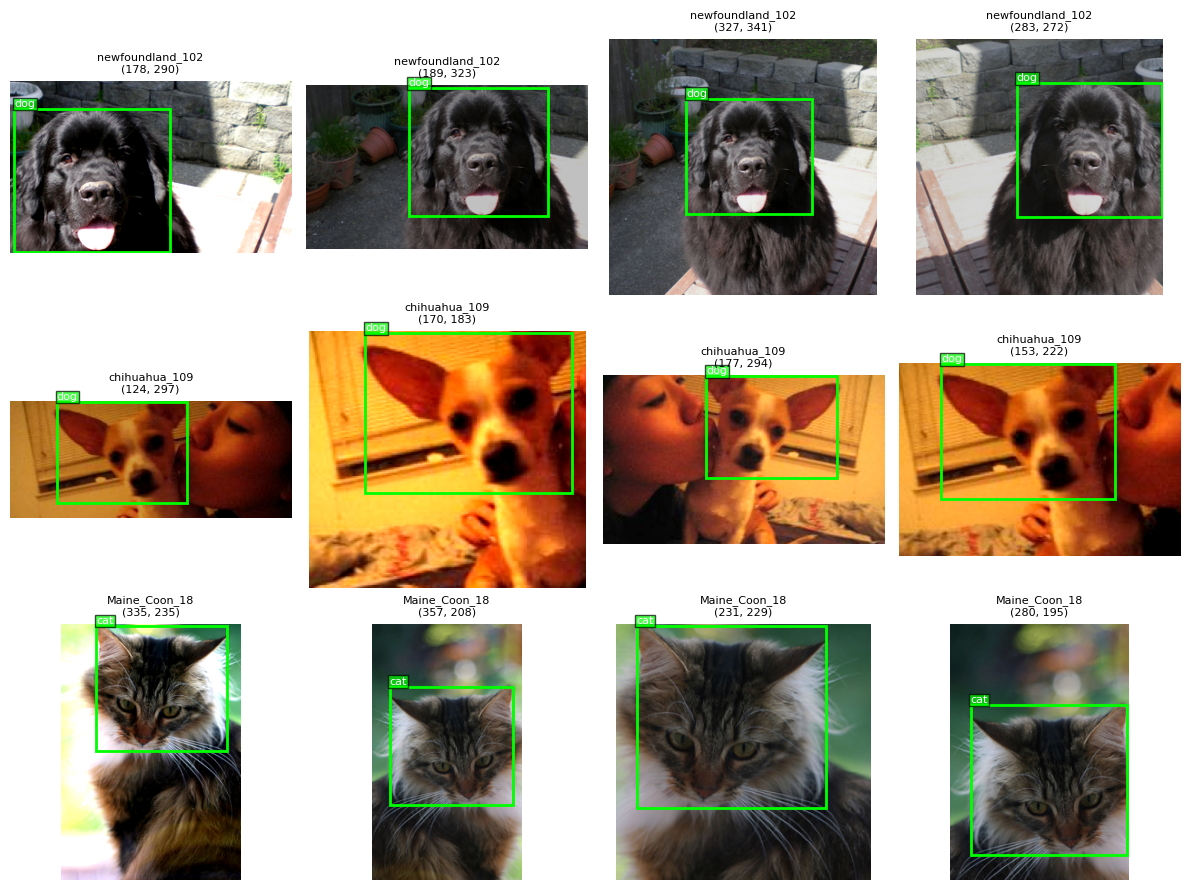

In [9]:
def uniform(low: float, high: float) -> float:
    """[low, high] 구간의 균등 난수 (torch 난수 사용)."""
    return low + (high - low) * torch.rand(()).item()


class RandomCropContainingBoxes(nn.Module):
    """모든 박스를 포함하는 영역을 무작위로 잘라낸다. 결과적으로 머리의 크기와 위치가 바뀐다.

    크롭의 가로·세로는 [max(박스 합집합 크기, min_ratio × 원본), 원본] 구간에서 뽑는다.
    """

    def __init__(self, min_ratio: float):
        super().__init__()
        self.min_ratio = min_ratio

    def forward(self, image: tv_tensors.Image, target: dict) -> tuple[tv_tensors.Image, dict]:
        boxes = target["boxes"]
        height, width = image.shape[-2:]
        union_x0, union_y0 = boxes[:, 0].min().item(), boxes[:, 1].min().item()
        union_x1, union_y1 = boxes[:, 2].max().item(), boxes[:, 3].max().item()

        crop_w = uniform(max(union_x1 - union_x0, self.min_ratio * width), width)
        crop_h = uniform(max(union_y1 - union_y0, self.min_ratio * height), height)
        left = uniform(max(0.0, union_x1 - crop_w), min(union_x0, width - crop_w))
        top = uniform(max(0.0, union_y1 - crop_h), min(union_y0, height - crop_h))

        # 정수 픽셀로 맞출 때 바깥쪽으로 반올림해 박스가 잘리지 않게 한다
        left_px, top_px = math.floor(left), math.floor(top)
        right_px, bottom_px = min(width, math.ceil(left + crop_w)), min(height, math.ceil(top + crop_h))
        crop_args = dict(top=top_px, left=left_px, height=bottom_px - top_px, width=right_px - left_px)
        return TF.crop(image, **crop_args), {**target, "boxes": TF.crop(boxes, **crop_args)}


def build_train_transform(augmentation: AugmentationConfig) -> v2.Compose:
    """train 전용 증강 파이프라인. 입력은 uint8 Image + target dict."""
    return v2.Compose([
        v2.RandomHorizontalFlip(p=augmentation.hflip_prob),
        RandomCropContainingBoxes(min_ratio=augmentation.crop_min_ratio),
        v2.ColorJitter(brightness=augmentation.brightness, contrast=augmentation.contrast),
        v2.ClampBoundingBoxes(),
        v2.SanitizeBoundingBoxes(),
        v2.ToDtype(torch.float32, scale=True),
    ])


def build_eval_transform() -> v2.Compose:
    """val / test 변환: 증강 없이 float `[0, 1]` 변환만 한다."""
    return v2.Compose([v2.ToDtype(torch.float32, scale=True)])


class PetHeadDetectionDataset(Dataset):
    """RAM 캐시에서 이미지와 머리 박스를 꺼내 transform을 적용한다."""

    def __init__(self, image_names: list[str], image_cache: dict[str, dict[str, torch.Tensor]],
                 transform: v2.Compose):
        self.image_names = list(image_names)
        self.image_cache = image_cache
        self.transform = transform

    def __len__(self) -> int:
        return len(self.image_names)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, dict]:
        entry = self.image_cache[self.image_names[index]]
        image = tv_tensors.Image(entry["image"])  # 복사 없이 캐시 텐서를 감싼다. v2 변환은 새 텐서를 만들어 캐시는 바뀌지 않는다
        target = {
            "boxes": tv_tensors.BoundingBoxes(entry["boxes"], format="XYXY", canvas_size=tuple(image.shape[-2:])),
            "labels": entry["labels"],
            "image_id": torch.tensor(index),
        }
        return self.transform(image, target)


def detection_collate(batch: list[tuple[torch.Tensor, dict]]) -> tuple[list[torch.Tensor], list[dict]]:
    """크기가 다른 이미지를 리스트로 묶고, tv_tensors 래퍼를 일반 텐서로 바꾼다."""
    images = [image.as_subclass(torch.Tensor) for image, _ in batch]
    targets = [{key: value.as_subclass(torch.Tensor) for key, value in target.items()} for _, target in batch]
    return images, targets


def build_dataloader(dataset: Dataset, batch_size: int, shuffle: bool, num_workers: int,
                     pin_memory: bool, seed: int) -> DataLoader:
    """Detection용 DataLoader. shuffle 순서는 seed로 고정한다."""
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, collate_fn=detection_collate,
                      num_workers=num_workers, pin_memory=pin_memory,
                      persistent_workers=num_workers > 0,  # epoch마다 worker를 다시 띄우지 않는다
                      generator=torch.Generator().manual_seed(seed))


def draw_boxes(ax, boxes: torch.Tensor, labels: torch.Tensor, class_names: tuple[str, ...], color: str,
               scores: Optional[torch.Tensor] = None, linestyle: str = "-") -> None:
    """ax 위에 박스와 'label (score)' 글자를 그린다."""
    for index, (x0, y0, x1, y1) in enumerate(boxes.tolist()):
        ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False,
                                       edgecolor=color, linewidth=2, linestyle=linestyle))
        text = class_names[int(labels[index])]
        if scores is not None:
            text += f" {float(scores[index]):.2f}"
        ax.text(x0, y0, text, color="white", fontsize=8, va="bottom", bbox=dict(facecolor=color, alpha=0.7, pad=1))


def show_augmented_samples(dataset: PetHeadDetectionDataset, class_names: tuple[str, ...],
                           num_images: int, num_repeats: int, seed: int) -> None:
    """같은 이미지에 증강을 여러 번 적용해, 박스가 머리를 따라가는지 확인한다."""
    generator = torch.Generator().manual_seed(seed)
    indices = torch.randperm(len(dataset), generator=generator)[:num_images].tolist()
    fig, axes = plt.subplots(num_images, num_repeats, figsize=(3 * num_repeats, 3 * num_images), squeeze=False)
    for row, index in enumerate(indices):
        for col in range(num_repeats):
            image, target = dataset[index]
            ax = axes[row, col]
            ax.imshow(image.permute(1, 2, 0).numpy())
            draw_boxes(ax, target["boxes"], target["labels"], class_names, color="lime")
            ax.set_title(f"{dataset.image_names[index]}\n{tuple(image.shape[-2:])}", fontsize=8)
            ax.axis("off")
    plt.tight_layout()
    plt.show()


# ---- 실행 ----
DATASETS = {
    "train": PetHeadDetectionDataset(SPLIT_NAMES["train"], IMAGE_CACHE, build_train_transform(CONFIG.augmentation)),
    "val": PetHeadDetectionDataset(SPLIT_NAMES["val"], IMAGE_CACHE, build_eval_transform()),
    "test": PetHeadDetectionDataset(SPLIT_NAMES["test"], IMAGE_CACHE, build_eval_transform()),
}
image, target = DATASETS["train"][0]
print("image:", image.dtype, tuple(image.shape), f"[{image.min():.2f}, {image.max():.2f}]")
print("target:", {key: (type(value).__name__, tuple(value.shape)) for key, value in target.items()})
show_augmented_samples(DATASETS["train"], CONFIG.data.class_names, num_images=3, num_repeats=4, seed=CONFIG.seed)

## D. 모델

### D-1. COCO SSD300 로드와 분류 head 교체
baseline의 `model.head.classification_head.num_classes = 3`은 아무 효과가 없다 (계획 §3 #1). `SSDScoringHead`는 생성할 때 정한 `num_columns`(= 91)로 출력을 reshape한다. 속성 하나를 바꿔도 conv 층의 출력 채널과 reshape는 그대로다. 그래서 **분류 head 객체를 통째로 새로 만들어 끼운다.**

| 구성 요소 | 처리 |
|---|---|
| `backbone` (VGG16 + L2Norm + extra layers) | COCO 가중치 그대로 |
| `head.regression_head` | COCO 가중치 그대로. 박스 회귀는 클래스와 무관하다 |
| `head.classification_head` | `SSDClassificationHead(in_channels, num_anchors, num_classes=3)`로 **새로 생성** (Xavier 초기화) |

- `in_channels`는 backbone이 내는 6개 feature map의 채널 수다. 하드코딩하지 않고, 300 × 300 더미 입력을 넣어 backbone에서 직접 읽는다 (`retrieve_out_channels`).
- `num_anchors`는 feature map 위치마다 놓이는 default box 수다. anchor generator에서 읽는다.

In [10]:
def build_ssd300_for_head_detection(num_classes: int, image_size: int) -> SSD:
    """COCO SSD300-VGG16을 불러와 분류 head를 num_classes용으로 교체한다."""
    model = ssd300_vgg16(weights=SSD300_VGG16_Weights.COCO_V1)
    # torchvision 내부 유틸: 더미 입력을 backbone에 통과시켜 feature map별 채널 수를 얻는다
    in_channels = detection_utils.retrieve_out_channels(model.backbone, (image_size, image_size))
    num_anchors = model.anchor_generator.num_anchors_per_location()
    model.head.classification_head = SSDClassificationHead(in_channels, num_anchors, num_classes)
    return model


# ---- 실행 ----
seed_everything(CONFIG.seed)
inspection_model = build_ssd300_for_head_detection(len(CONFIG.data.class_names), CONFIG.model.image_size)
image_size = (CONFIG.model.image_size, CONFIG.model.image_size)
print("in_channels :", detection_utils.retrieve_out_channels(inspection_model.backbone, image_size))
print("num_anchors :", inspection_model.anchor_generator.num_anchors_per_location())
print(inspection_model.head.classification_head)

Downloading: "https://download.pytorch.org/models/ssd300_vgg16_coco-b556d3b4.pth" to /root/.cache/torch/hub/checkpoints/ssd300_vgg16_coco-b556d3b4.pth


100%|██████████| 136M/136M [00:00<00:00, 159MB/s]  


in_channels : [512, 1024, 512, 256, 256, 256]
num_anchors : [4, 6, 6, 6, 4, 4]
SSDClassificationHead(
  (module_list): ModuleList(
    (0): Conv2d(512, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): Conv2d(1024, 18, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): Conv2d(512, 18, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): Conv2d(256, 18, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4-5): 2 x Conv2d(256, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
)


### D-2. 학습 범위 지정 (freeze)
- **Phase 1 (FE, `trainable_scope="head"`)**: 모든 파라미터를 `requires_grad=False`로 바꾼 뒤 `model.head`만 다시 켠다.
- **Phase 2 (FT, `"all"`)**: 모든 파라미터를 켠다.
- 두 경우 모두 **모든 파라미터의 값을 명시적으로 지정한다.** torchvision은 COCO 가중치를 불러올 때 `trainable_backbone_layers=4`가 기본값이라 **VGG의 첫 conv 블록(38,720개)을 이미 얼려 둔다.** 이걸 모르고 "아무것도 안 얼렸으니 전체 학습"이라고 생각하면 Phase 2가 사실은 full fine-tuning이 아니게 된다.
- VGG16에는 BatchNorm이 없다. 그래서 backbone을 얼려도 BN 통계(running mean / var)가 학습 중에 바뀌는 문제가 없다. 대신 `model.train()`만 호출하면 된다.
- backbone 파라미터가 gradient를 요구하지 않으면 autograd가 backbone 연산을 계산 그래프에 기록하지 않는다. 그래서 FE는 backward 비용과 activation 메모리도 함께 줄어든다.

In [11]:
def set_trainable_scope(model: SSD, scope: str) -> None:
    """scope에 따라 모든 파라미터의 requires_grad를 명시적으로 지정한다."""
    if scope not in ("head", "all"):
        raise ValueError(f"unknown trainable scope: {scope}")
    for parameter in model.parameters():
        parameter.requires_grad_(scope == "all")
    if scope == "head":
        for parameter in model.head.parameters():
            parameter.requires_grad_(True)


def summarize_parameters(model: SSD) -> pd.DataFrame:
    """모듈별 파라미터 수와 학습 대상 파라미터 수를 표로 만든다."""
    components = {
        "backbone": model.backbone,
        "head.regression_head": model.head.regression_head,
        "head.classification_head": model.head.classification_head,
    }
    rows = []
    for name, module in components.items():
        parameters = list(module.parameters())
        rows.append({"component": name,
                     "params": sum(p.numel() for p in parameters),
                     "trainable": sum(p.numel() for p in parameters if p.requires_grad)})
    table = pd.DataFrame(rows)
    total = {"component": "total", "params": table["params"].sum(), "trainable": table["trainable"].sum()}
    table = pd.concat([table, pd.DataFrame([total])], ignore_index=True)
    table["trainable %"] = (100 * table["trainable"] / table["params"]).round(1)
    return table.set_index("component")


# ---- 실행 ----
default_frozen = sum(p.numel() for p in inspection_model.parameters() if not p.requires_grad)
print(f"torchvision 기본 상태에서 이미 얼어 있는 파라미터: {default_frozen:,}")
set_trainable_scope(inspection_model, CONFIG.model.trainable_scope)
display(summarize_parameters(inspection_model).style.format("{:,}", subset=["params", "trainable"]))

torchvision 기본 상태에서 이미 얼어 있는 파라미터: 38,720


,params,trainable,trainable %
component,,,
backbone,"22,943,936",0,0.000000
head.regression_head,"534,648","534,648",100.000000
head.classification_head,"400,986","400,986",100.000000
total,"23,879,570","935,634",3.900000


### D-3. Sanity check
학습 전에 head 교체가 실제로 반영됐는지 출력 shape로 확인한다 (계획 §5).
- 분류 출력이 `(N, 8732, 3)`인가? baseline처럼 교체가 안 됐다면 `(N, 8732, 91)`이 나온다.
- 8732 = feature map 6개의 (H × W × 위치당 anchor 수) 합이다: 38²·4 + 19²·6 + 10²·6 + 5²·6 + 3²·4 + 1²·4.

In [12]:
@torch.no_grad()
def check_head_output_shapes(model: SSD, num_classes: int, image_size: int, expected_num_anchors: int) -> dict:
    """더미 입력으로 backbone → head를 통과시켜 출력 shape를 검증한다."""
    was_training = model.training
    model.eval()
    device = next(model.parameters()).device
    features = list(model.backbone(torch.zeros(1, 3, image_size, image_size, device=device)).values())
    head_outputs = model.head(features)
    model.train(was_training)

    anchors_per_location = model.anchor_generator.num_anchors_per_location()
    num_anchors = sum(f.shape[-2] * f.shape[-1] * a for f, a in zip(features, anchors_per_location))
    shapes = {key: tuple(value.shape) for key, value in head_outputs.items()}
    assert num_anchors == expected_num_anchors, num_anchors
    assert shapes["cls_logits"] == (1, expected_num_anchors, num_classes), shapes
    assert shapes["bbox_regression"] == (1, expected_num_anchors, 4), shapes
    return {"feature_maps": [tuple(f.shape[-2:]) for f in features], **shapes}


# ---- 실행 ----
print(check_head_output_shapes(inspection_model, len(CONFIG.data.class_names),
                               CONFIG.model.image_size, CONFIG.model.expected_num_anchors))
del inspection_model  # 학습은 Step E에서 새로 만든 모델로 한다

{'feature_maps': [(38, 38), (19, 19), (10, 10), (5, 5), (3, 3), (1, 1)], 'bbox_regression': (1, 8732, 4), 'cls_logits': (1, 8732, 3)}


## E. 학습

### E-1. Optimizer와 LR 스케줄
- optimizer에는 `requires_grad=True`인 파라미터만 넘긴다. 얼린 파라미터에 weight decay가 걸리거나 optimizer state가 쓸데없이 생기지 않게 한다.
- LR은 **iteration마다** 바뀐다 (계획 §6). baseline은 scheduler를 만들고 `step()`을 한 번도 부르지 않아 LR이 고정이었다 (계획 §3 #2).

| 구간 | LR 배율 (× 2e-3) |
|---|---|
| warmup (첫 1 epoch) | 0.1 → 1.0 선형 증가 |
| 이후 | cosine으로 1.0 → 0 감소 (`max_epochs` 끝에 0) |

early stopping으로 일찍 끝나면 cosine이 0까지 내려가기 전에 멈춘다.

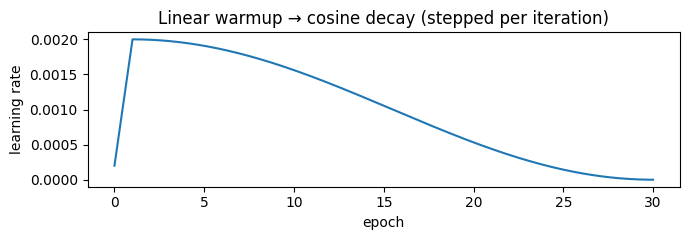

In [13]:
def build_optimizer(model: nn.Module, train: TrainConfig) -> torch.optim.Optimizer:
    """학습 대상 파라미터만 SGD에 넘긴다."""
    trainable = [p for p in model.parameters() if p.requires_grad]
    return torch.optim.SGD(trainable, lr=train.learning_rate, momentum=train.momentum,
                           weight_decay=train.weight_decay)


def warmup_cosine_factor(step: int, warmup_steps: int, total_steps: int, warmup_start_factor: float) -> float:
    """step(0부터)에서의 LR 배율: 선형 warmup 뒤 cosine decay."""
    if step < warmup_steps:
        return warmup_start_factor + (1.0 - warmup_start_factor) * step / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1.0 + math.cos(math.pi * min(1.0, progress)))


def build_warmup_cosine_scheduler(optimizer: torch.optim.Optimizer, steps_per_epoch: int,
                                  train: TrainConfig) -> torch.optim.lr_scheduler.LambdaLR:
    """iteration 단위로 step하는 warmup + cosine 스케줄러."""
    warmup_steps = train.warmup_epochs * steps_per_epoch
    total_steps = train.max_epochs * steps_per_epoch
    return torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: warmup_cosine_factor(step, warmup_steps, total_steps, train.warmup_start_factor))


def plot_lr_schedule(steps_per_epoch: int, train: TrainConfig) -> None:
    """스케줄러가 의도대로 움직이는지 학습 전에 그려 본다."""
    warmup_steps, total_steps = train.warmup_epochs * steps_per_epoch, train.max_epochs * steps_per_epoch
    steps = np.arange(total_steps)
    lrs = [train.learning_rate * warmup_cosine_factor(s, warmup_steps, total_steps, train.warmup_start_factor)
           for s in steps]
    fig, ax = plt.subplots(figsize=(7, 2.5))
    ax.plot(steps / steps_per_epoch, lrs)
    ax.set_xlabel("epoch")
    ax.set_ylabel("learning rate")
    ax.set_title("Linear warmup → cosine decay (stepped per iteration)")
    plt.tight_layout()
    plt.show()


# ---- 실행 ----
plot_lr_schedule(math.ceil(len(DATASETS["train"]) / CONFIG.data.batch_size), CONFIG.train)

### E-2. 1 epoch 학습과 평가 함수
**학습 (`train_one_epoch`)**
- torchvision SSD는 train 모드에서 `model(images, targets)`를 호출하면 loss dict `{"bbox_regression", "classification"}`을 돌려준다. 내부에서 300 × 300 리사이즈, 정규화, anchor 매칭, hard negative mining(배경 : 객체 = 3 : 1)까지 한다.
- AMP: forward는 `autocast(fp16)`로 돌리고, `GradScaler`로 loss를 키운 뒤 backward한다. fp16 gradient가 0으로 사라지는(underflow) 것을 막기 위해서다.

**평가 (`predict` → `compute_detection_metrics`)**
- eval 모드의 `model(images)`는 이미지마다 `{"boxes", "scores", "labels"}`를 돌려준다. 박스는 **입력 이미지 크기(캐시 좌표계)로 되돌린 값**이라 GT와 바로 비교할 수 있다.
- mAP는 `torchmetrics`의 COCO 방식으로 계산한다 (계획 §3 #4, §7). 놓친 GT(recall)와 IoU 0.5~0.95의 10개 기준을 모두 반영한다.
- **Mean IoU**: 이미지마다 score가 가장 높은 예측 1개와 GT 박스의 IoU(GT가 여럿이면 가장 큰 값)를 구해 평균한다. SPECIES는 따지지 않는 위치 정확도 지표다. 예측이 하나도 없으면 0으로 센다.

In [ ]:
def move_batch_to_device(images: list[torch.Tensor], targets: list[dict], device: torch.device):
    """이미지와 target을 device로 옮긴다. pin_memory와 함께 non_blocking 복사를 쓴다."""
    images = [image.to(device, non_blocking=True) for image in images]
    targets = [{key: value.to(device, non_blocking=True) for key, value in target.items()} for target in targets]
    return images, targets


def train_one_epoch(model: SSD, loader: DataLoader, optimizer: torch.optim.Optimizer,
                    scheduler: torch.optim.lr_scheduler.LRScheduler, scaler: torch.amp.GradScaler,
                    device: torch.device, use_amp: bool) -> dict[str, float]:
    """1 epoch 학습하고 평균 loss를 돌려준다. scheduler는 iteration마다 step한다."""
    model.train()
    totals = {"loss": 0.0, "loss_classification": 0.0, "loss_bbox_regression": 0.0}
    for images, targets in tqdm(loader, desc="train", leave=False):
        images, targets = move_batch_to_device(images, targets, device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            loss_dict = model(images, targets)
            loss = loss_dict["classification"] + loss_dict["bbox_regression"]
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        totals["loss"] += loss.item()
        totals["loss_classification"] += loss_dict["classification"].item()
        totals["loss_bbox_regression"] += loss_dict["bbox_regression"].item()
    return {key: value / len(loader) for key, value in totals.items()}


@torch.no_grad()
def predict(model: SSD, loader: DataLoader, device: torch.device, use_amp: bool) -> tuple[list[dict], list[dict]]:
    """loader 전체를 예측한다. (예측 리스트, GT 리스트)를 CPU 텐서로 돌려준다. 두 리스트의 순서는 같다."""
    model.eval()
    predictions, ground_truths = [], []
    for images, targets in tqdm(loader, desc="predict", leave=False):
        images = [image.to(device, non_blocking=True) for image in images]
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            outputs = model(images)
        predictions += [{"boxes": o["boxes"].float().cpu(), "scores": o["scores"].float().cpu(),
                         "labels": o["labels"].cpu()} for o in outputs]
        ground_truths += [{"boxes": t["boxes"], "labels": t["labels"], "image_id": int(t["image_id"])} for t in targets]
    return predictions, ground_truths


def top1_iou_per_image(predictions: list[dict], ground_truths: list[dict]) -> list[float]:
    """이미지마다 최고 score 예측 1개와 GT 박스 사이의 IoU (GT가 여럿이면 최댓값). 예측이 없으면 0."""
    ious = []
    for prediction, ground_truth in zip(predictions, ground_truths):
        if len(prediction["boxes"]) == 0:
            ious.append(0.0)
            continue
        top_box = prediction["boxes"][prediction["scores"].argmax()].unsqueeze(0)
        ious.append(box_iou(top_box, ground_truth["boxes"]).max().item())
    return ious


def compute_detection_metrics(predictions: list[dict], ground_truths: list[dict],
                              class_names: tuple[str, ...]) -> dict[str, float]:
    """COCO 방식 mAP@[0.5:0.95], mAP@0.5, SPECIES별 AP, mean IoU를 계산한다."""
    metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox", class_metrics=True)
    # COCO 평가는 이미지당 상위 100개 예측만 본다. torchvision SSD는 최대 200개를 내므로 경고가 뜨지만,
    # 잘리는 것은 score가 가장 낮은 예측이라 GT가 1~2개인 이 데이터에서는 결과에 영향이 없다
    metric.warn_on_many_detections = False
    metric.update(predictions, [{"boxes": gt["boxes"], "labels": gt["labels"]} for gt in ground_truths])
    result = metric.compute()
    metrics = {"map": result["map"].item(), "map_50": result["map_50"].item(), "map_75": result["map_75"].item()}
    # 클래스가 하나뿐이면 0-dim 텐서가 나오므로 1-dim으로 맞춘다
    for class_id, ap in zip(torch.atleast_1d(result["classes"]).tolist(),
                            torch.atleast_1d(result["map_per_class"]).tolist()):
        metrics[f"ap_{class_names[class_id]}"] = ap
    metrics["mean_iou"] = float(np.mean(top1_iou_per_image(predictions, ground_truths)))
    return metrics

### E-3. 체크포인트 관리 (계획 §4)
| 파일 | 언제 쓰나 | 어디에 쓰나 | 내용 |
|---|---|---|---|
| `{run_id}_resume.pt` | **3 epoch마다** + 마지막 epoch | 로컬 → Drive 복사 | model, optimizer, scheduler, scaler, epoch, best val mAP, early stopping 카운터, 학습 기록, RNG 상태 |
| `{run_id}_best.pt` | val mAP@[0.5:0.95]가 오를 때마다 | **로컬에만** 덮어쓴다. Drive에는 다음 3 epoch 체크포인트 때 같이 복사 | model 가중치, epoch, val 지표 |

- Drive는 비동기로 동기화된다. 매 epoch 쓰면 동기화가 밀리고, 그 상태로 VM이 멈추면 밀린 파일은 사라진다. 그래서 Drive에 쓰는 횟수를 3 epoch에 한 번으로 줄였다. 대신 VM이 멈추면 최대 2 epoch 분량을 다시 학습해야 한다.
- 재개할 때는 로컬과 Drive 중 **더 늦은 epoch의 체크포인트**를 고른다. Drive 쪽이 더 늦다면(= VM이 새로 시작됨) best 파일도 함께 로컬로 가져온다.
- RNG 상태를 저장하므로 재개 후의 main process 난수(shuffle 순서 등)는 이어진다. 다만 DataLoader worker는 새로 뜨면서 시드를 새로 받기 때문에, 재개 후의 **증강은 끊기지 않은 실행과 똑같지 않다.**

In [15]:
def capture_rng_state() -> dict:
    """python / numpy / torch / CUDA 난수 상태를 저장용 dict로 모은다."""
    return {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}


def restore_rng_state(state: dict) -> None:
    """capture_rng_state로 저장한 난수 상태를 되돌린다."""
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    if state["cuda"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(state["cuda"])


class CheckpointManager:
    """resume / best 체크포인트를 로컬에 쓰고, 정해진 시점에만 영구 저장소로 복사한다."""

    def __init__(self, run_id: str, local_dir: Path, persistent_dir: Optional[Path]):
        self.local_dir = local_dir
        self.persistent_dir = persistent_dir
        self.resume_name = f"{run_id}_resume.pt"
        self.best_name = f"{run_id}_best.pt"
        local_dir.mkdir(parents=True, exist_ok=True)

    def save_best(self, model: nn.Module, epoch: int, val_metrics: dict) -> None:
        """best 가중치를 로컬에만 덮어쓴다."""
        atomic_torch_save({"model": model.state_dict(), "epoch": epoch, "val_metrics": val_metrics},
                          self.local_dir / self.best_name)

    def save_resume(self, state: dict) -> None:
        """resume 체크포인트를 로컬에 쓰고, best와 함께 영구 저장소로 복사한다."""
        atomic_torch_save(state, self.local_dir / self.resume_name)
        for name in (self.resume_name, self.best_name):
            copy_to_persistent(self.local_dir / name, self.persistent_dir)

    def load_resume(self) -> Optional[dict]:
        """로컬·영구 저장소 중 더 늦은 epoch의 resume 체크포인트를 읽는다. 없으면 None.

        항상 CPU로 읽는다. RNG 상태는 CPU 텐서여야 복원되고, model / optimizer는
        load_state_dict가 각 파라미터의 device로 알아서 옮긴다.
        """
        candidates = []
        for directory in (self.local_dir, self.persistent_dir):
            if directory is not None and (directory / self.resume_name).exists():
                # 직접 만든 파일이고 RNG 상태(numpy 배열 등)가 들어 있어 weights_only=False로 읽는다
                state = torch.load(directory / self.resume_name, map_location="cpu", weights_only=False)
                candidates.append((state["epoch"], directory, state))
        if not candidates:
            return None
        epoch, directory, state = max(candidates, key=lambda item: item[0])
        if directory != self.local_dir:  # VM이 새로 시작된 경우: best도 영구 저장소에서 가져온다
            for name in (self.resume_name, self.best_name):
                if (directory / name).exists():
                    atomic_copy(directory / name, self.local_dir / name)
        print(f"체크포인트에서 재개: epoch {epoch} ({directory})")
        return state

    def load_best(self, map_location: torch.device) -> dict:
        """best 체크포인트를 읽는다 (로컬 우선)."""
        path = find_existing(self.best_name, [self.local_dir, self.persistent_dir])
        if path is None:
            raise FileNotFoundError(self.best_name)
        return torch.load(path, map_location=map_location, weights_only=True)

### E-4. 학습 루프 (`fit`)
epoch마다 다음 순서로 진행한다.

1. train 1 epoch → val 예측 → val 지표 계산
2. val mAP@[0.5:0.95]가 오르면 best 저장 (로컬), 아니면 early stopping 카운터 + 1
3. 3 epoch마다, 또는 마지막 epoch(최대 epoch 도달·early stopping)이면 resume 체크포인트를 저장하고 Drive로 복사
4. 카운터가 patience(7)에 닿으면 종료

epoch마다 걸린 시간과 GPU 최대 메모리도 기록한다. Phase 2(FT)와 비용을 비교하기 위해서다 (계획 §9). 이미 끝난 run의 체크포인트가 있으면 다시 학습하지 않고 기록만 돌려준다.

In [ ]:
def fit(model: SSD, train_loader: DataLoader, val_loader: DataLoader, train: TrainConfig,
        class_names: tuple[str, ...], device: torch.device, checkpoints: CheckpointManager) -> list[dict]:
    """학습 전체를 실행하고 epoch별 기록(history)을 돌려준다. 체크포인트가 있으면 이어서 한다."""
    use_amp = train.use_amp and device.type == "cuda"
    optimizer = build_optimizer(model, train)
    scheduler = build_warmup_cosine_scheduler(optimizer, len(train_loader), train)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    start_epoch, best_val_map, epochs_without_improvement, history = 1, -1.0, 0, []
    state = checkpoints.load_resume()
    if state is not None:
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        scaler.load_state_dict(state["scaler"])
        restore_rng_state(state["rng"])
        start_epoch = state["epoch"] + 1
        best_val_map, epochs_without_improvement = state["best_val_map"], state["epochs_without_improvement"]
        history = state["history"]
        if state["finished"]:
            print("이미 끝난 run이다. 저장된 기록을 돌려준다.")
            return history

    for epoch in range(start_epoch, train.max_epochs + 1):
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats(device)
        epoch_start = time.time()
        current_lr = optimizer.param_groups[0]["lr"]

        train_losses = train_one_epoch(model, train_loader, optimizer, scheduler, scaler, device, use_amp)
        val_metrics = compute_detection_metrics(*predict(model, val_loader, device, use_amp), class_names)

        improved = val_metrics["map"] > best_val_map
        if improved:
            best_val_map, epochs_without_improvement = val_metrics["map"], 0
            checkpoints.save_best(model, epoch, val_metrics)
        else:
            epochs_without_improvement += 1

        history.append({
            "epoch": epoch, "lr_at_start": current_lr, **train_losses,
            **{f"val_{key}": value for key, value in val_metrics.items()},
            "epoch_time_sec": time.time() - epoch_start,
            "peak_gpu_mem_mb": torch.cuda.max_memory_allocated(device) / 2**20 if device.type == "cuda" else float("nan"),
        })

        stop_early = epochs_without_improvement >= train.early_stopping_patience
        finished = stop_early or epoch == train.max_epochs
        if epoch % train.checkpoint_every_n_epochs == 0 or finished:
            checkpoints.save_resume({
                "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                "epoch": epoch, "best_val_map": best_val_map,
                "epochs_without_improvement": epochs_without_improvement,
                "history": history, "rng": capture_rng_state(), "finished": finished,
            })

        print(f"[epoch {epoch:02d}] loss {train_losses['loss']:.3f} "
              f"(cls {train_losses['loss_classification']:.3f}, reg {train_losses['loss_bbox_regression']:.3f}) | "
              f"val mAP {val_metrics['map']:.4f}, mAP@0.5 {val_metrics['map_50']:.4f}, "
              f"IoU {val_metrics['mean_iou']:.3f} | {history[-1]['epoch_time_sec']:.0f}s"
              + (" *best" if improved else ""))
        if stop_early:
            print(f"early stopping: {train.early_stopping_patience} epoch 동안 val mAP 개선 없음")
            break
    return history


def run_training(config: ExperimentConfig, datasets: dict[str, Dataset], device: torch.device) -> tuple[SSD, list[dict], CheckpointManager]:
    """config 하나로 모델 생성 → 학습 범위 지정 → sanity check → 학습까지 실행한다. Phase 1·2 공통."""
    seed_everything(config.seed)
    model = build_ssd300_for_head_detection(len(config.data.class_names), config.model.image_size)
    set_trainable_scope(model, config.model.trainable_scope)
    model.to(device)
    check_head_output_shapes(model, len(config.data.class_names), config.model.image_size,
                             config.model.expected_num_anchors)

    pin_memory = device.type == "cuda"
    train_loader = build_dataloader(datasets["train"], config.data.batch_size, shuffle=True,
                                    num_workers=config.data.num_workers, pin_memory=pin_memory, seed=config.seed)
    val_loader = build_dataloader(datasets["val"], config.data.eval_batch_size, shuffle=False,
                                  num_workers=config.data.num_workers, pin_memory=pin_memory, seed=config.seed)
    checkpoints = CheckpointManager(config.run_id, config.paths.local_output_dir, config.paths.persistent_output_dir)
    history = fit(model, train_loader, val_loader, config.train, config.data.class_names, device, checkpoints)
    save_json(history, f"{config.run_id}_history.json",
              config.paths.local_output_dir, config.paths.persistent_output_dir)
    return model, history, checkpoints

### E-5. Phase 1 (FE) 학습 실행
런타임이 끊겼다면 Step A부터 다시 실행하면 된다. 분할·이미지 캐시·체크포인트를 저장된 파일에서 읽어 마지막 체크포인트부터 이어서 학습한다.

In [17]:
# ---- 실행 ----
FE_MODEL, FE_HISTORY, FE_CHECKPOINTS = run_training(CONFIG, DATASETS, DEVICE)
pd.DataFrame(FE_HISTORY).set_index("epoch").round(4)

체크포인트에서 재개: epoch 30 (/content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/outputs)
이미 끝난 run이다. 저장된 기록을 돌려준다.


,lr_at_start,loss,loss_classification,loss_bbox_regression,val_map,val_map_50,val_map_75,val_ap_cat,val_ap_dog,val_mean_iou,epoch_time_sec,peak_gpu_mem_mb
epoch,,,,,,,,,,,,
1,0.0002,6.1611,4.6234,1.5377,0.1558,0.5185,0.0329,0.1455,0.1660,0.5361,54.2794,1781.2036
2,0.0020,4.5155,2.9380,1.5776,0.1911,0.5550,0.0668,0.2010,0.1813,0.5581,45.5735,1781.2036
3,0.0020,4.0306,2.5094,1.5212,0.1471,0.5329,0.0232,0.1524,0.1418,0.5127,44.6772,1781.2036
4,0.0020,3.9007,2.3909,1.5098,0.1924,0.6030,0.0507,0.2175,0.1673,0.5368,44.8593,1781.2036
5,0.0019,3.8937,2.4515,1.4422,0.2218,0.6735,0.0731,0.2711,0.1724,0.5746,49.1572,1781.2036
6,0.0019,3.8713,2.3918,1.4796,0.2491,0.7060,0.0763,0.2831,0.2150,0.5873,46.5585,1781.2036
7,0.0019,3.6292,2.2681,1.3611,0.2532,0.6995,0.1011,0.2926,0.2139,0.5790,46.3440,1781.2036
8,0.0018,3.7413,2.3221,1.4192,0.2306,0.6594,0.0738,0.2447,0.2166,0.5776,44.9442,1781.2036
9,0.0017,3.5236,2.2501,1.2734,0.2068,0.6541,0.0514,0.2201,0.1935,0.5630,45.4151,1781.2036


## F. 평가와 분석 (Phase 1)

### F-1. 학습 곡선
train loss(분류 / 회귀)와 val 지표를 epoch별로 그린다. 별표는 best epoch다. 확인할 것:
- loss가 계속 내려가는데 val mAP가 멈추거나 떨어지면 과적합이다.
- 분류 loss와 회귀 loss 중 어느 쪽이 학습을 주도하는지 본다.

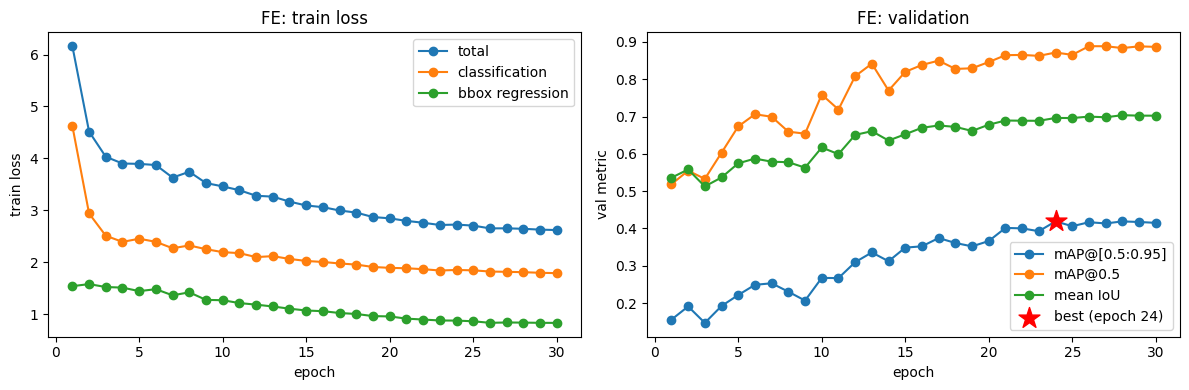

In [18]:
def plot_learning_curves(history: list[dict], title: str) -> None:
    """train loss와 val 지표를 나란히 그린다."""
    frame = pd.DataFrame(history)
    best = frame.loc[frame["val_map"].idxmax()]
    fig, (ax_loss, ax_val) = plt.subplots(1, 2, figsize=(12, 4))
    for column, label in [("loss", "total"), ("loss_classification", "classification"),
                          ("loss_bbox_regression", "bbox regression")]:
        ax_loss.plot(frame["epoch"], frame[column], marker="o", label=label)
    ax_loss.set(xlabel="epoch", ylabel="train loss", title=f"{title}: train loss")
    ax_loss.legend()
    for column, label in [("val_map", "mAP@[0.5:0.95]"), ("val_map_50", "mAP@0.5"), ("val_mean_iou", "mean IoU")]:
        ax_val.plot(frame["epoch"], frame[column], marker="o", label=label)
    ax_val.scatter([best["epoch"]], [best["val_map"]], marker="*", s=250, color="red", zorder=5,
                   label=f"best (epoch {int(best['epoch'])})")
    ax_val.set(xlabel="epoch", ylabel="val metric", title=f"{title}: validation")
    ax_val.legend()
    plt.tight_layout()
    plt.show()


# ---- 실행 ----
plot_learning_curves(FE_HISTORY, CONFIG.run_id)

### F-2. Test split 최종 성능
best 체크포인트를 불러와 test split(15%, 551장)에서 **한 번만** 평가한다 (계획 §7). val은 checkpoint 선택에 이미 썼으므로 최종 성능 보고에는 쓰지 않는다.

In [19]:
def load_best_model(config: ExperimentConfig, checkpoints: CheckpointManager, device: torch.device) -> tuple[SSD, dict]:
    """best 가중치를 새 모델에 불러온다. (모델, best 체크포인트 메타)를 돌려준다."""
    best = checkpoints.load_best(map_location=device)
    model = build_ssd300_for_head_detection(len(config.data.class_names), config.model.image_size)
    model.load_state_dict(best["model"])
    return model.to(device).eval(), {"epoch": best["epoch"], "val_metrics": best["val_metrics"]}


def evaluate_on_test(config: ExperimentConfig, model: SSD, test_dataset: Dataset,
                     device: torch.device) -> tuple[dict, list[dict], list[dict]]:
    """test split 전체를 예측하고 지표를 계산해 JSON으로 저장한다."""
    loader = build_dataloader(test_dataset, config.data.eval_batch_size, shuffle=False,
                              num_workers=config.data.num_workers, pin_memory=device.type == "cuda", seed=config.seed)
    predictions, ground_truths = predict(model, loader, device, config.train.use_amp and device.type == "cuda")
    metrics = compute_detection_metrics(predictions, ground_truths, config.data.class_names)
    save_json(metrics, f"{config.run_id}_test_metrics.json",
              config.paths.local_output_dir, config.paths.persistent_output_dir)
    return metrics, predictions, ground_truths


# ---- 실행 ----
FE_BEST_MODEL, FE_BEST_META = load_best_model(CONFIG, FE_CHECKPOINTS, DEVICE)
FE_TEST_METRICS, FE_TEST_PREDICTIONS, FE_TEST_GROUND_TRUTHS = evaluate_on_test(
    CONFIG, FE_BEST_MODEL, DATASETS["test"], DEVICE)
print(f"best epoch: {FE_BEST_META['epoch']}")
pd.DataFrame({"val (best epoch)": FE_BEST_META["val_metrics"], "test": FE_TEST_METRICS}).round(4)

predict:   0%|          | 0/18 [00:00<?, ?it/s]

best epoch: 24


,val (best epoch),test
map,0.4192,0.4012
map_50,0.8715,0.8698
map_75,0.3315,0.2917
ap_cat,0.4638,0.4214
ap_dog,0.3746,0.3809
mean_iou,0.6962,0.6802


### F-3. SPECIES별, head scale별 분석 (계획 §8)
- **SPECIES별**: `cat`과 `dog`의 AP와 mean IoU를 비교한다. Cat : Dog = 1 : 2.1 불균형의 영향을 본다.
- **head scale별**: 이미지마다 `scale = sqrt(박스 면적 / 이미지 면적)`을 구한다 (박스가 여러 개면 평균). small < 0.25, medium 0.25–0.5, large > 0.5로 나누고, 그룹마다 mAP와 mean IoU를 따로 계산한다. COCO의 small / medium / large는 절대 픽셀 면적 기준이라, 이미지 크기가 제각각인 이 데이터에는 이미지 대비 비율이 더 알맞다.

In [20]:
def head_scale(boxes: torch.Tensor, image_height: int, image_width: int) -> float:
    """sqrt(박스 면적 / 이미지 면적)의 평균."""
    areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return torch.sqrt(areas / (image_height * image_width)).mean().item()


def build_per_image_table(dataset: PetHeadDetectionDataset, predictions: list[dict], ground_truths: list[dict],
                          class_names: tuple[str, ...], scale_bins: tuple[float, ...]) -> pd.DataFrame:
    """이미지별 SPECIES, head scale 그룹, top-1 IoU, top-1 예측 label·score를 표로 만든다."""
    ious = top1_iou_per_image(predictions, ground_truths)
    rows = []
    for prediction, ground_truth, iou in zip(predictions, ground_truths, ious):
        name = dataset.image_names[ground_truth["image_id"]]
        height, width = dataset.image_cache[name]["image"].shape[-2:]
        has_prediction = len(prediction["scores"]) > 0
        top = int(prediction["scores"].argmax()) if has_prediction else None
        rows.append({
            "image": name, "species": class_names[int(ground_truth["labels"][0])],
            "scale": head_scale(ground_truth["boxes"], height, width), "top1_iou": iou,
            "top1_label": class_names[int(prediction["labels"][top])] if has_prediction else None,
            "top1_score": float(prediction["scores"][top]) if has_prediction else 0.0,
        })
    table = pd.DataFrame(rows)
    table["scale_group"] = pd.cut(table["scale"], bins=[0, *scale_bins, np.inf],
                                  labels=["small", "medium", "large"], right=False)
    return table


def metrics_by_group(per_image: pd.DataFrame, group_column: str, predictions: list[dict],
                     ground_truths: list[dict], class_names: tuple[str, ...]) -> pd.DataFrame:
    """group_column의 그룹마다 이미지 부분집합으로 mAP·mean IoU를 다시 계산한다."""
    rows = []
    for group, subset in per_image.groupby(group_column, observed=True):
        indices = subset.index.tolist()
        metrics = compute_detection_metrics([predictions[i] for i in indices],
                                            [ground_truths[i] for i in indices], class_names)
        rows.append({group_column: group, "images": len(indices), "map": metrics["map"],
                     "map_50": metrics["map_50"], "mean_iou": metrics["mean_iou"],
                     "species_correct": (subset["top1_label"] == subset["species"]).mean()})
    return pd.DataFrame(rows).set_index(group_column)


# ---- 실행 ----
FE_PER_IMAGE = build_per_image_table(DATASETS["test"], FE_TEST_PREDICTIONS, FE_TEST_GROUND_TRUTHS,
                                     CONFIG.data.class_names, scale_bins=(0.25, 0.5))
print("SPECIES별 (species_correct = top-1 예측의 SPECIES가 맞은 비율)")
display(metrics_by_group(FE_PER_IMAGE, "species", FE_TEST_PREDICTIONS, FE_TEST_GROUND_TRUTHS,
                         CONFIG.data.class_names).round(4))
print("head scale별")
display(metrics_by_group(FE_PER_IMAGE, "scale_group", FE_TEST_PREDICTIONS, FE_TEST_GROUND_TRUTHS,
                         CONFIG.data.class_names).round(4))

SPECIES별 (species_correct = top-1 예측의 SPECIES가 맞은 비율)


,images,map,map_50,mean_iou,species_correct
species,,,,,
cat,176,0.4242,0.8931,0.6929,0.9602
dog,375,0.3825,0.8565,0.6742,0.9893


head scale별


,images,map,map_50,mean_iou,species_correct
scale_group,,,,,
small,93,0.3002,0.7503,0.5859,0.9677
medium,291,0.3987,0.8471,0.6750,0.9863
large,167,0.4940,0.9729,0.7416,0.9760


### F-4. 실패 사례: top-1 IoU가 가장 낮은 test 이미지
초록 실선은 GT, 빨간 점선은 score가 가장 높은 예측 1개다. 제목의 SPECIES와 예측 label을 비교해 오류 유형을 나눈다.
- **머리를 놓침**: 예측 박스가 엉뚱한 곳(몸 전체, 배경)에 있다. IoU ≈ 0
- **박스가 느슨함**: 머리는 찾았지만 경계가 크거나 작다. IoU가 0.3~0.6 정도
- **SPECIES 오류**: 위치는 맞는데 cat / dog를 바꿔 말한다

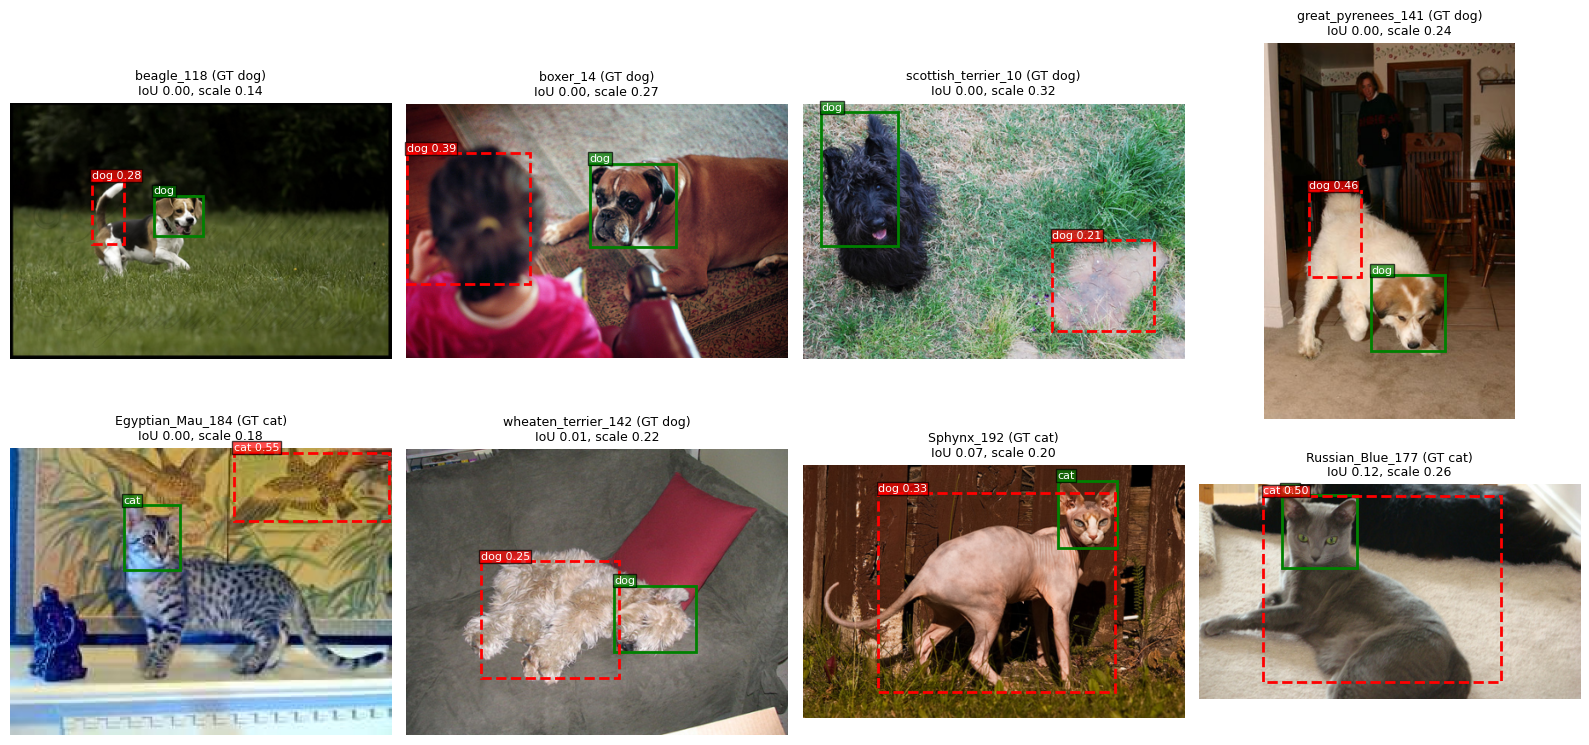

In [21]:
def show_lowest_iou_cases(dataset: PetHeadDetectionDataset, per_image: pd.DataFrame, predictions: list[dict],
                          ground_truths: list[dict], class_names: tuple[str, ...], num_cases: int) -> None:
    """top-1 IoU가 가장 낮은 이미지에 GT와 top-1 예측을 겹쳐 그린다."""
    worst = per_image.nsmallest(num_cases, "top1_iou")
    num_cols = 4
    num_rows = math.ceil(len(worst) / num_cols)
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(4 * num_cols, 4 * num_rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (index, row) in zip(axes.flat, worst.iterrows()):
        image = dataset.image_cache[row["image"]]["image"]
        ax.imshow(image.permute(1, 2, 0).numpy())
        ground_truth, prediction = ground_truths[index], predictions[index]
        draw_boxes(ax, ground_truth["boxes"], ground_truth["labels"], class_names, color="green")
        if len(prediction["scores"]) > 0:
            top = prediction["scores"].argmax()
            draw_boxes(ax, prediction["boxes"][top:top + 1], prediction["labels"][top:top + 1], class_names,
                       color="red", scores=prediction["scores"][top:top + 1], linestyle="--")
        ax.set_title(f"{row['image']} (GT {row['species']})\nIoU {row['top1_iou']:.2f}, scale {row['scale']:.2f}",
                     fontsize=9)
    plt.tight_layout()
    plt.show()


# ---- 실행 ----
show_lowest_iou_cases(DATASETS["test"], FE_PER_IMAGE, FE_TEST_PREDICTIONS, FE_TEST_GROUND_TRUTHS,
                      CONFIG.data.class_names, num_cases=8)

### F-5. 공식 `test.txt` 정성 평가
README는 "제공된 데이터셋의 테스트 파일로 테스트"하라고 요구한다. 그러나 공식 `test.txt`의 3,669장에는 XML(박스 정답)이 없다 (EDA §2). 그래서 무작위로 고른 이미지에 예측 박스를 그려 **눈으로만** 확인한다.
- 전처리는 학습과 똑같다: RGB 변환 → 긴 변 448로 축소 → float `[0, 1]`.
- 박스 정답은 없지만 `test.txt`에는 SPECIES가 있으므로, 제목에 정답 SPECIES를 함께 적는다.
- score가 가장 높은 예측 1개를 그린다. score가 `score_threshold`보다 낮으면 점선으로 그린다.

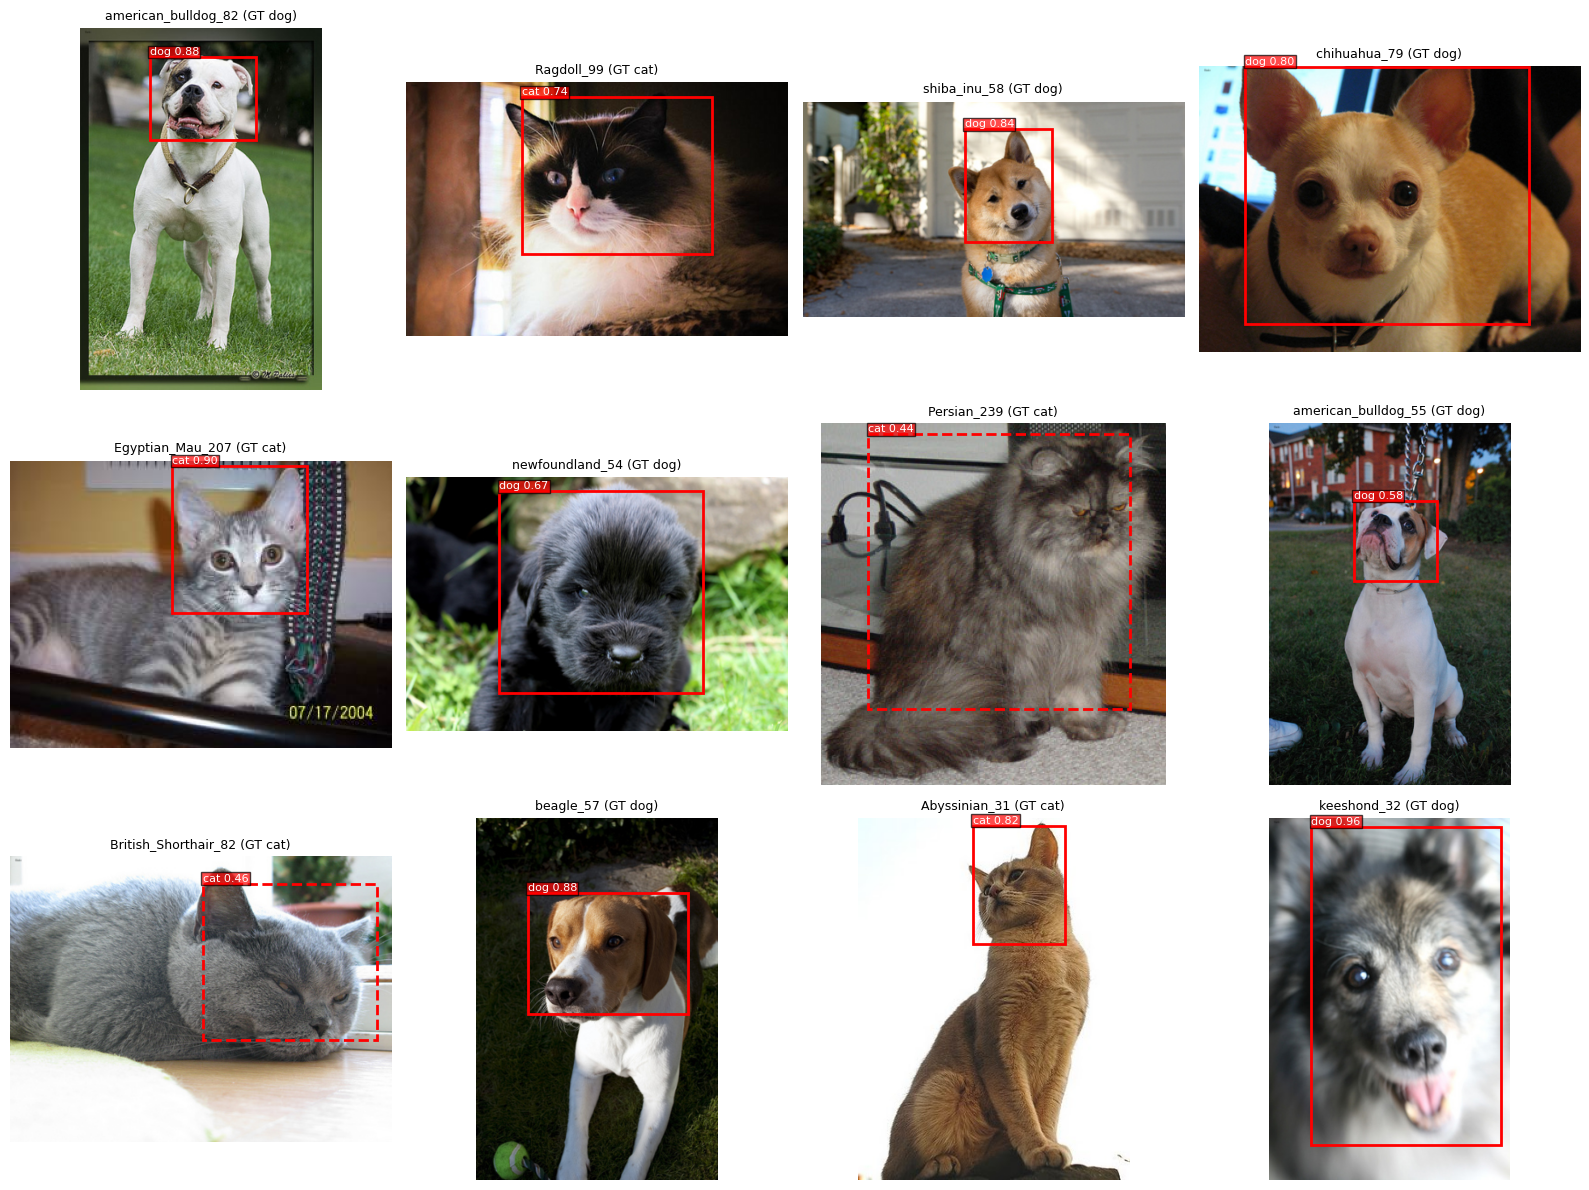

In [22]:
@torch.no_grad()
def predict_image_files(model: SSD, image_paths: list[Path], max_side: int, device: torch.device) -> list[tuple[torch.Tensor, dict]]:
    """이미지 파일을 학습과 같은 방식으로 전처리해 예측한다. [(uint8 이미지, 예측 dict)]"""
    model.eval()
    results = []
    for path in image_paths:
        image, _, _ = load_rgb_image_downscaled(path, max_side)
        output = model([TF.to_dtype(image, torch.float32, scale=True).to(device)])[0]
        results.append((image, {key: value.cpu() for key, value in output.items()}))
    return results


def show_official_test_predictions(model: SSD, paths: PathConfig, class_names: tuple[str, ...], max_side: int,
                                   num_images: int, score_threshold: float, seed: int, device: torch.device) -> None:
    """공식 test.txt에서 무작위로 고른 이미지에 top-1 예측을 그린다."""
    official_test = read_split_file(paths.annotation_dir / "test.txt").sample(n=num_images, random_state=seed)
    image_paths = [paths.image_dir / f"{name}.jpg" for name in official_test["image"]]
    results = predict_image_files(model, image_paths, max_side, device)

    num_cols = 4
    fig, axes = plt.subplots(math.ceil(num_images / num_cols), num_cols, figsize=(4 * num_cols, 4 * math.ceil(num_images / num_cols)), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (row, (image, prediction)) in zip(axes.flat, zip(official_test.itertuples(index=False), results)):
        ax.imshow(image.permute(1, 2, 0).numpy())
        true_species = class_names[row.species_id]  # SPECIES 1 = Cat, 2 = Dog → class_names index와 같다
        if len(prediction["scores"]) > 0:
            top = prediction["scores"].argmax()
            score = float(prediction["scores"][top])
            draw_boxes(ax, prediction["boxes"][top:top + 1], prediction["labels"][top:top + 1], class_names,
                       color="red", scores=prediction["scores"][top:top + 1],
                       linestyle="-" if score >= score_threshold else "--")
        ax.set_title(f"{row.image} (GT {true_species})", fontsize=9)
    plt.tight_layout()
    plt.show()


# ---- 실행 ----
show_official_test_predictions(FE_BEST_MODEL, CONFIG.paths, CONFIG.data.class_names, CONFIG.data.cache_max_side,
                               num_images=12, score_threshold=0.5, seed=CONFIG.seed, device=DEVICE)

### F-6. 결과 해석 (Phase 1: FE)
> 1회 실행(seed 1개) 결과다. 이미지 수가 적은 그룹(small 93장, SPECIES 오류 몇 장)의 차이는 통계적으로 확정할 수 없다.
> 각 항목에서 **관찰**은 위 표와 그림에서 직접 읽은 사실이고, **가설**은 원인에 대한 추측이다. 가설마다 검증 방법을 함께 적었다. 가설은 이 실험으로 검증되지 않았다. 일부는 G(Phase 2)에서 간접적으로 확인했다.

#### 1. Test split 최종 성능
**관찰**

| 지표 | val (best epoch 24) | test | test − val |
|---|---|---|---|
| mAP@[0.5:0.95] | 0.419 | **0.401** | −0.018 |
| mAP@0.5 | 0.872 | 0.870 | −0.002 |
| mAP@0.75 | 0.332 | 0.292 | −0.040 |
| AP cat / AP dog | 0.464 / 0.375 | 0.421 / 0.381 | −0.042 / +0.006 |
| mean IoU (top-1) | 0.696 | 0.680 | −0.016 |

- mAP@0.5는 0.870인데 mAP@0.75는 0.292다. IoU 기준을 0.5에서 0.75로 올리면 AP가 1/3 수준으로 떨어진다.
- test는 val보다 약간 낮다. 차이는 mAP@0.75와 AP cat에서 가장 크다(−0.04).

**baseline(0.99)과의 비교**: 직접 비교할 수 없다. baseline의 0.99는 `sklearn.average_precision_score`로 예측만 순위 매겨 계산한 값이다. 놓친 GT(recall)가 빠져 있고 IoU 0.5 하나만 썼다 (계획 §3 #4). 이 실험의 수치와 정의가 가장 비슷한 것은 mAP@0.5(0.870)다. 그래도 COCO 방식은 놓친 GT를 반영하므로 두 값은 같은 지표가 아니다. 따라서 0.99 → 0.87을 성능 하락으로 읽으면 안 된다.

**가설**: FE는 머리 위치를 대략 찾는 데(IoU ≥ 0.5)는 성공한다. 하지만 경계를 정밀하게 맞추지는 못한다. COCO의 cat / dog 박스는 동물 몸 전체를 감싼다. 그래서 동결된 COCO feature에는 "머리 경계"를 표현하는 정보가 부족하고, head만 학습해서는 이를 보완하기 어렵다.
- 검증: backbone도 학습하는 Phase 2(G)와 비교한다. G에서 mAP@0.75가 0.292에서 0.930으로 올랐는데, 이는 가설과 맞는 결과다. 다만 FT는 2,300만 개 파라미터를 한꺼번에 바꿨으므로 원인을 "COCO feature의 경계 정보"로 한정하지는 못한다.

#### 2. 학습 곡선
**관찰**
- train loss는 6.16에서 2.62로 내려갔다. 그중 classification은 4.62에서 1.79로, bbox regression은 1.54에서 0.83으로 내려갔다.
- 처음 3 epoch 동안 classification loss는 크게 내려갔다(4.62 → 2.51). bbox regression은 거의 그대로였다(1.54 → 1.52). regression은 8 epoch 이후에 꾸준히 내려갔다.
- val mAP는 초반에 크게 출렁였다. 3 epoch에는 0.191에서 0.147로, 8~9 epoch에는 0.253에서 0.207로, 14 epoch에는 0.336에서 0.312로 떨어졌다. 21 epoch 이후에는 0.393~0.419 범위로 출렁임이 줄었다.
- best는 24 epoch(0.419)이고 마지막 30 epoch은 0.415다. val mAP가 계속 떨어지는 구간은 없다.
- 마지막 epoch에도 train loss는 조금씩 내려가고 있었다(25 epoch 2.70 → 30 epoch 2.62).

**가설**
- 초반의 출렁임은 LR(최대 2e-3)이 head만 학습하기에는 클 때 나타나는 현상일 수 있다. 다만 val이 551장뿐이라 생기는 측정 noise와 구분할 수 없다.
  - 검증: LR을 낮춰(예: 1e-3, 5e-4) 같은 설정으로 학습해 출렁임이 줄어드는지 본다.
- 막판에 성능이 멈춘 이유는 두 가지가 섞여 있을 수 있다. cosine schedule로 LR이 0에 가까워진 탓일 수도 있고, head만 학습하는 구조의 용량 한계일 수도 있다(학습 파라미터 94만 개).
  - 검증: `max_epochs`를 늘려 다시 학습한다. 또는 G의 FT 결과와 비교한다. FT는 1 epoch 만에 val mAP 0.512로 FE 최고치를 넘었으며, 이는 용량 한계 쪽 가설과 맞는다.
- classification loss가 regression loss보다 크다. 하지만 두 loss는 정의가 달라 크기를 직접 비교하기 어렵다. classification은 hard negative mining으로 배경 anchor를 포함하고, regression은 Smooth L1이다. 그래서 어느 쪽이 학습을 주도한다고 결론 내리지 않는다.

과적합 여부: val loss는 계산하지 않았다. 판단 근거는 val mAP가 떨어지지 않았다는 점과 test가 val과 비슷하다는 점(−0.018)뿐이다.

#### 3. SPECIES별
**관찰**

| | images | mAP | mAP@0.5 | mean IoU | SPECIES 오류 |
|---|---|---|---|---|---|
| cat | 176 | 0.424 | 0.893 | 0.693 | 7장 (4.0%) |
| dog | 375 | 0.382 | 0.857 | 0.674 | 4장 (1.1%) |

- 학습 데이터는 dog가 cat의 2.1배다. 그런데도 박스 지표(mAP, mAP@0.5, mean IoU)는 모두 cat이 더 높다.
- SPECIES 오류 비율은 반대로 cat이 dog의 약 3.6배다. 클래스가 2개이므로 cat 오류 7장은 모두 cat을 dog로 예측한 것이다.

**가설**
- cat을 dog로 잘못 말하는 쪽으로 치우친 것은 학습 데이터 불균형(Cat : Dog = 1 : 2.1) 때문일 수 있다. 분류기가 다수 클래스인 dog 쪽으로 기운다는 해석이다.
  - 검증: class-weighted loss나 SPECIES 균형 sampling으로 학습해 cat 오류가 줄어드는지 본다.
- 박스 지표에서 cat이 앞서는 이유는 머리 모양의 다양성일 수 있다. dog는 25개 BREED에 걸쳐 주둥이, 귀, 털이 cat(12개 BREED)보다 다양해 경계가 덜 일정하다.
  - 검증: CLASS-ID(BREED)별 mean IoU를 계산한다. FT(G-5 §3)에서도 같은 순서(cat > dog)가 나왔으며, 이는 모델 용량보다 데이터 쪽 원인이라는 해석과 맞는다.

#### 4. head scale별
**관찰**

| scale_group | images | mAP | mAP@0.5 | mean IoU | SPECIES 오류 |
|---|---|---|---|---|---|
| small (< 0.25) | 93 | 0.300 | 0.750 | 0.586 | 3장 |
| medium | 291 | 0.399 | 0.847 | 0.675 | 4장 |
| large (> 0.5) | 167 | 0.494 | 0.973 | 0.742 | 4장 |

- 모든 지표가 small < medium < large 순서다.
- large는 IoU 0.5 기준으로 거의 다 찾는다(mAP@0.5 0.973). small은 0.750이다.
- SPECIES 오류 비율은 그룹 간 차이가 작다(small 3.2%, medium 1.4%, large 2.4%).

**가설**: 입력이 300×300으로 줄어들면 small 머리는 수십 픽셀만 남는다. 가장 촘촘한 feature map(38×38, stride 8)에서도 몇 칸만 차지해 위치를 잡기 어렵다. FE에서는 이 단계의 feature(VGG conv4_3)를 학습하지 못하므로 영향이 더 클 수 있다.
- 검증: scale과 top-1 IoU의 산점도를 그린다. FT와 비교하면 small/large mAP 비율이 FE 0.61, FT 0.85(G-5 §4)로, 격차가 FT에서 줄었다. 다만 해상도 문제인지 feature 문제인지는 이것만으로 분리되지 않는다.

#### 5. 실패 사례 (F-4: top-1 IoU 하위 8장)
**관찰**
- 8장 모두 IoU가 0.13 미만(0.00 ~ 0.12)이다. 박스가 느슨한 수준이 아니라 머리를 놓친 경우다.
- scale은 0.14 ~ 0.32다. 5장이 small, 3장이 medium이고, large는 없다.
- top-1 score는 모두 0.55 이하(0.21 ~ 0.55)다.
- 예측 위치는 세 종류다.

| 예측 위치 | 이미지 | 예측 label |
|---|---|---|
| 배경 | boxer_14 (옆에 있는 사람의 머리), scottish_terrier_10 (잔디 사이 맨땅), Egyptian_Mau_184 (벽지 무늬) | dog, dog, cat |
| 머리가 아닌 신체 부위 | beagle_118 (몸 뒤쪽), great_pyrenees_141 (등·엉덩이), wheaten_terrier_142 (몸통) | 모두 dog |
| 몸 전체 | Sphynx_192, Russian_Blue_177 | **dog**, cat |

- 8장 중 SPECIES 오류는 Sphynx_192(cat → dog) 1장이다.

**가설**
- 몸 전체를 감싸는 오류는 1절의 가설(COCO의 몸 전체 박스에 맞춰진 feature)과 맞는다.
- 배경 오류는 머리와 질감이 비슷한 영역이나 사람의 머리에 feature가 반응한 결과일 수 있다. 사례가 3장뿐이라 근거는 약하다.
- 실패 사례의 score가 모두 낮은 것은, 모델이 이 이미지들에서 확신하지 못한다는 뜻일 수 있다.
  - 검증: test 전체에서 top-1 score와 IoU의 상관을 본다. 상관이 높다면 score threshold로 실패를 걸러낼 수 있다(그 대신 recall이 줄어든다).
- 참고로 이 8장은 G-3b에서 FT가 모두 IoU 0.62 이상으로 맞혔다.

#### 6. 공식 `test.txt` 정성 평가 (박스 정답 없음, 눈으로만 확인)
**관찰**
- 12장 모두 예측 label이 `test.txt`의 SPECIES와 같다.
- top-1 score는 0.44 ~ 0.96이다.
- threshold 0.5 미만(점선)은 2장이며 둘 다 cat이다. Persian_239(0.44)는 박스가 머리가 아닌 몸 전체를 감싼다. British_Shorthair_82(0.46)는 머리 주변을 크게 감싼다.
- 나머지 10장은 예측 박스가 머리 위에 있다.

**가설**: 정답 박스가 없어 이 12장으로는 정량적으로 판단할 수 없다. 털이 긴 장모종(Persian)이나 엎드린 자세(British_Shorthair_82)에서 머리 경계가 흐려진다는 해석도 가능하지만, 2장으로는 근거가 되지 않는다.

#### 7. 비용
**관찰**: 학습 파라미터는 935,634개다(전체 약 2,390만 개 중 head만). epoch당 45.8초(T4)가 걸려 30 epoch에 약 23분이 들었다. 최대 GPU 메모리는 1,781 MB다.

#### 요약
- FE는 test mAP@[0.5:0.95] 0.401, mAP@0.5 0.870을 기록했다. 머리를 대략 찾는 데는 성공하지만 박스 경계는 느슨하다(mAP@0.75 0.292)(관찰).
- 성능은 small head에서 가장 낮다(mAP 0.300). 최악의 사례는 배경, 다른 신체 부위, 몸 전체를 머리로 잡은 경우다(관찰).
- cat은 박스 지표는 높지만, dog로 잘못 말하는 비율이 dog의 3.6배다(관찰). 원인은 데이터 불균형으로 추정한다(가설).
- 동결된 COCO feature가 머리 경계를 담지 못한다는 해석은 G(Phase 2) 결과와 맞지만, 원인으로 확정된 것은 아니다(가설).

## G. (선택) Phase 2: Full fine-tuning과 비교 (계획 §9)
GPU 시간이 남을 때만 `RUN_PHASE_2 = True`로 바꿔 실행한다.
- Phase 1 config에서 **`run_id`와 `trainable_scope`만** 바꾼다. 분할, 캐시, 증강, optimizer, LR, 스케줄, epoch, batch, seed는 그대로다.
- 학습·평가는 Phase 1과 똑같은 함수(`run_training`, `load_best_model`, `evaluate_on_test`)로 한다.
- 비교표는 저장된 JSON(`{run_id}_test_metrics.json`, `{run_id}_history.json`)에서 만든다. 그래서 FT를 다른 세션에서 돌렸어도 표를 만들 수 있다.

In [23]:
def make_phase2_config(base: ExperimentConfig) -> ExperimentConfig:
    """Phase 1 설정에서 학습 범위만 'all'로 바꾼다."""
    return replace(base, run_id=base.run_id.replace("FE", "FT"), model=replace(base.model, trainable_scope="all"))


def count_trainable_parameters(config: ExperimentConfig) -> int:
    """config의 학습 범위를 적용했을 때 학습 대상 파라미터 수."""
    model = build_ssd300_for_head_detection(len(config.data.class_names), config.model.image_size)
    set_trainable_scope(model, config.model.trainable_scope)
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def build_comparison_table(configs: list[ExperimentConfig]) -> pd.DataFrame:
    """run마다 저장된 test 지표·학습 기록으로 비교표를 만든다. 결과 파일이 없는 run은 건너뛴다."""
    rows = []
    for config in configs:
        directories = [config.paths.local_output_dir, config.paths.persistent_output_dir]
        metrics_path = find_existing(f"{config.run_id}_test_metrics.json", directories)
        history_path = find_existing(f"{config.run_id}_history.json", directories)
        if metrics_path is None or history_path is None:
            print(f"{config.run_id}: 결과 파일이 없어 건너뛴다")
            continue
        history = pd.DataFrame(json.loads(history_path.read_text()))
        rows.append({"run": config.run_id, "trainable_scope": config.model.trainable_scope,
                     **json.loads(metrics_path.read_text()),
                     "trainable_params": count_trainable_parameters(config),
                     "epochs_run": len(history), "best_epoch": int(history.loc[history["val_map"].idxmax(), "epoch"]),
                     "time_per_epoch_sec": history["epoch_time_sec"].mean(),
                     "peak_gpu_mem_mb": history["peak_gpu_mem_mb"].max()})
    return pd.DataFrame(rows).set_index("run")


# ---- 실행 ----
RUN_PHASE_2 = False

FT_CONFIG = make_phase2_config(CONFIG)
if RUN_PHASE_2:
    FT_MODEL, FT_HISTORY, FT_CHECKPOINTS = run_training(FT_CONFIG, DATASETS, DEVICE)
    plot_learning_curves(FT_HISTORY, FT_CONFIG.run_id)
    FT_BEST_MODEL, FT_BEST_META = load_best_model(FT_CONFIG, FT_CHECKPOINTS, DEVICE)
    FT_TEST_METRICS, _, _ = evaluate_on_test(FT_CONFIG, FT_BEST_MODEL, DATASETS["test"], DEVICE)
build_comparison_table([CONFIG, FT_CONFIG]).T

run,FE,FT
trainable_scope,head,all
map,0.401171,0.803399
map_50,0.869794,0.989456
map_75,0.291696,0.92955
ap_cat,0.42145,0.858052
ap_dog,0.380892,0.748745
mean_iou,0.680176,0.889261
trainable_params,935634,23879570
epochs_run,30,30
best_epoch,24,29


### G-1. FT 분석: Test split 최종 성능
Phase 1(F-2 ~ F-5)과 **같은 함수, 같은 인자**로 FT best 모델을 분석한다. 그래야 FE와 FT의 표·그림을 그대로 나란히 비교할 수 있다.

| FT 셀 | 대응하는 FE 셀 | 내용 |
|---|---|---|
| G-1 | F-2 | test split 최종 성능 |
| G-2 | F-3 | SPECIES별, head scale별 분석 |
| G-3 | F-4 | 실패 사례 |
| G-4 | F-5 | 공식 `test.txt` 정성 평가 |

G 셀은 비교표에 필요한 지표만 남기고 test 예측 결과는 버린다. 그래서 여기서 test split을 한 번 더 예측해 분석에 쓴다. 같은 모델과 같은 데이터이므로 지표는 G 셀과 같다 (`FT_test_metrics.json`도 같은 값으로 다시 저장된다).

모든 셀은 `RUN_PHASE_2 = True`일 때만 실행된다.

In [ ]:
# ---- 실행 ----
if RUN_PHASE_2:
    FT_TEST_METRICS, FT_TEST_PREDICTIONS, FT_TEST_GROUND_TRUTHS = evaluate_on_test(
        FT_CONFIG, FT_BEST_MODEL, DATASETS["test"], DEVICE)
    print(f"best epoch: {FT_BEST_META['epoch']}")
    display(pd.DataFrame({"val (best epoch)": FT_BEST_META["val_metrics"], "test": FT_TEST_METRICS}).round(4))

### G-2. FT 분석: SPECIES별, head scale별
F-3과 같은 기준(scale 경계 0.25 / 0.5)으로 나눈다.

In [ ]:
# ---- 실행 ----
if RUN_PHASE_2:
    FT_PER_IMAGE = build_per_image_table(DATASETS["test"], FT_TEST_PREDICTIONS, FT_TEST_GROUND_TRUTHS,
                                         FT_CONFIG.data.class_names, scale_bins=(0.25, 0.5))
    print("SPECIES별 (species_correct = top-1 예측의 SPECIES가 맞은 비율)")
    display(metrics_by_group(FT_PER_IMAGE, "species", FT_TEST_PREDICTIONS, FT_TEST_GROUND_TRUTHS,
                             FT_CONFIG.data.class_names).round(4))
    print("head scale별")
    display(metrics_by_group(FT_PER_IMAGE, "scale_group", FT_TEST_PREDICTIONS, FT_TEST_GROUND_TRUTHS,
                             FT_CONFIG.data.class_names).round(4))

### G-3. FT 분석: 실패 사례
F-4와 같은 방식으로 top-1 IoU가 가장 낮은 test 이미지 8장을 그린다. FE의 실패 사례와 겹치는 이미지가 있는지, 오류 유형(머리를 놓침 / 박스가 느슨함 / SPECIES 오류)의 비중이 달라졌는지 본다.

In [ ]:
# ---- 실행 ----
if RUN_PHASE_2:
    show_lowest_iou_cases(DATASETS["test"], FT_PER_IMAGE, FT_TEST_PREDICTIONS, FT_TEST_GROUND_TRUTHS,
                          FT_CONFIG.data.class_names, num_cases=8)

### G-3b. FE의 실패 사례를 FT는 어떻게 보는가
G-3(FT 자신의 실패 사례)과 별개로, **F-4에서 FE가 가장 크게 틀린 test 이미지 8장**에 FT의 예측을 나란히 그린다. 이미지마다 왼쪽이 FE, 오른쪽이 FT다 (초록 실선 GT, 빨간 점선 top-1 예측).
- 두 run 모두 같은 test Dataset을 `shuffle=False`로 예측했으므로, 예측 리스트의 같은 index는 같은 이미지다. 함수 안에서 이를 한 번 더 확인한다.
- 아래 표의 `FE_iou` → `FT_iou` 변화로 backbone까지 학습한 효과가 FE의 약점에서 나타나는지 본다. 이미지 대비 head가 작은 경우, SPECIES를 바꿔 말한 경우가 FT에서 고쳐지는지가 관심사다.
- 같은 세션에서 F-2, F-3(FE 예측과 `FE_PER_IMAGE`)과 G-1, G-2(FT)가 먼저 실행돼 있어야 한다.

In [ ]:
def compare_runs_on_cases(dataset: PetHeadDetectionDataset, case_indices: list[int],
                          per_image_by_run: dict[str, pd.DataFrame], predictions_by_run: dict[str, list[dict]],
                          ground_truths: list[dict], class_names: tuple[str, ...],
                          cases_per_row: int = 2) -> pd.DataFrame:
    """같은 test 이미지에 여러 run의 top-1 예측을 나란히 그리고, run별 top-1 IoU·label 표를 돌려준다.

    case_indices는 per-image 표와 예측 리스트의 공통 index다 (test 예측 순서가 run마다 같다는 전제).
    """
    run_names = list(predictions_by_run)
    reference_images = per_image_by_run[run_names[0]]["image"]
    for run_name in run_names[1:]:  # 전제 확인: run마다 같은 index가 같은 이미지여야 한다
        assert (per_image_by_run[run_name]["image"] == reference_images).all(), f"{run_name}의 이미지 순서가 다르다"

    num_cols = cases_per_row * len(run_names)
    num_rows = math.ceil(len(case_indices) / cases_per_row)
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(3.5 * num_cols, 3.8 * num_rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for case_number, index in enumerate(case_indices):
        name = reference_images[index]
        image = dataset.image_cache[name]["image"].permute(1, 2, 0).numpy()
        ground_truth = ground_truths[index]
        for run_number, run_name in enumerate(run_names):
            ax = axes[case_number // cases_per_row, (case_number % cases_per_row) * len(run_names) + run_number]
            ax.imshow(image)
            draw_boxes(ax, ground_truth["boxes"], ground_truth["labels"], class_names, color="green")
            prediction = predictions_by_run[run_name][index]
            if len(prediction["scores"]) > 0:
                top = prediction["scores"].argmax()
                draw_boxes(ax, prediction["boxes"][top:top + 1], prediction["labels"][top:top + 1], class_names,
                           color="red", scores=prediction["scores"][top:top + 1], linestyle="--")
            ax.set_title(f"[{run_name}] {name}\nIoU {per_image_by_run[run_name].loc[index, 'top1_iou']:.2f}",
                         fontsize=9)
    plt.tight_layout()
    plt.show()

    table = per_image_by_run[run_names[0]].loc[case_indices, ["image", "species", "scale", "scale_group"]].copy()
    for run_name in run_names:
        table[f"{run_name}_iou"] = per_image_by_run[run_name].loc[case_indices, "top1_iou"]
        table[f"{run_name}_label"] = per_image_by_run[run_name].loc[case_indices, "top1_label"]
    return table


# ---- 실행 ----
if RUN_PHASE_2:
    FE_WORST_INDICES = FE_PER_IMAGE.nsmallest(8, "top1_iou").index.tolist()  # F-4에서 그린 것과 같은 8장
    display(compare_runs_on_cases(DATASETS["test"], FE_WORST_INDICES,
                                  per_image_by_run={"FE": FE_PER_IMAGE, "FT": FT_PER_IMAGE},
                                  predictions_by_run={"FE": FE_TEST_PREDICTIONS, "FT": FT_TEST_PREDICTIONS},
                                  ground_truths=FT_TEST_GROUND_TRUTHS,
                                  class_names=FT_CONFIG.data.class_names).round(3))

### G-4. FT 분석: 공식 `test.txt` 정성 평가
F-5와 **같은 seed**로 고르므로 FE와 같은 12장이 나온다. 같은 이미지에서 두 모델의 박스를 직접 비교할 수 있다.

In [28]:
# ---- 실행 ----
if RUN_PHASE_2:
    show_official_test_predictions(FT_BEST_MODEL, FT_CONFIG.paths, FT_CONFIG.data.class_names,
                                   FT_CONFIG.data.cache_max_side, num_images=12, score_threshold=0.5,
                                   seed=FT_CONFIG.seed, device=DEVICE)

### G-5. FT 결과 해석 (FE와 비교)
> 1회 실행(seed 1개) 결과다. 이미지 수가 적은 그룹(small 93장, SPECIES 오류 몇 장)의 차이는 통계적으로 확정할 수 없다.
> 각 항목에서 **관찰**은 위 표와 그림에서 직접 읽은 사실이고, **가설**은 원인에 대한 추측이다. 가설마다 검증 방법을 함께 적었다. 가설은 이 실험으로 검증되지 않았다.

#### 1. Test split 최종 성능
**관찰**

| 지표 (test) | FE | FT | 차이 |
|---|---|---|---|
| mAP@[0.5:0.95] | 0.401 | **0.803** | +0.402 (2.0배) |
| mAP@0.5 | 0.870 | 0.989 | +0.120 |
| mAP@0.75 | 0.292 | 0.930 | +0.638 (3.2배) |
| mean IoU (top-1) | 0.680 | 0.889 | +0.209 |
| AP cat / AP dog | 0.421 / 0.381 | 0.858 / 0.749 | |

- FT의 val(best epoch 29)은 0.798, test는 0.803이다. FE는 val(best epoch 24)이 0.419, test가 0.401이다.
- 차이는 IoU 기준이 엄격할수록 커진다. mAP@0.5에서는 0.120, mAP@0.75에서는 0.638이다. FE도 머리를 대략 찾는 데는(IoU ≥ 0.5) 0.87을 달성했다.

**가설**: FE와 FT의 차이는 주로 박스 경계의 정밀도에서 나온다. COCO의 cat / dog 박스는 동물 몸 전체를 감싼다. 그래서 동결된 COCO feature에는 "머리 경계"를 표현하는 정보가 부족하고, head만 학습해서는 이를 보완하기 어렵다. FE의 실패 사례 중 몸 전체를 감싼 예측(F-4의 Sphynx_192, Russian_Blue_177)이 이 가설과 맞는다.
- 검증: backbone 일부만 풀어(예: extra layers만) 학습해 본다. 그 결과 mAP@0.75가 어떻게 변하는지 보면, feature의 어느 단계가 경계 정밀도를 결정하는지 좁힐 수 있다.

#### 2. 학습 곡선
**관찰**
- FT는 1 epoch 만에 val mAP 0.512를 기록했다. FE의 30 epoch 중 최고치(0.419)보다 높다.
- FT val mAP@0.5는 1 epoch부터 0.94 이상이고, 12 epoch 이후에는 0.98 근처에서 거의 변하지 않는다. mAP@[0.5:0.95]는 25~30 epoch에서 0.792~0.798 범위다.
- 30 epoch 동안 val mAP가 계속 떨어지는 구간은 없다. train loss는 4.32에서 0.45로 내려갔고, 마지막 몇 epoch는 거의 평평하다.

**가설**: 막바지 곡선이 평평한 이유가 수렴 때문인지, cosine schedule로 LR이 0에 가까워졌기 때문인지는 이 실험으로 구분할 수 없다.
- 검증: `max_epochs`를 늘려(예: 50) 같은 schedule로 다시 학습한다. 그때도 val mAP가 0.80 근처에 머무는지 본다.

과적합 여부: val loss는 계산하지 않았다. 판단 근거는 val mAP가 떨어지지 않았다는 점과 val ≈ test라는 점뿐이다.

#### 3. SPECIES별
**관찰**

| | images | mAP (FE → FT) | mAP@0.5 (FT) | mean IoU (FT) | SPECIES 오류 수 (FE → FT) |
|---|---|---|---|---|---|
| cat | 176 | 0.424 → 0.858 | 0.990 | 0.919 | 7 → 1 |
| dog | 375 | 0.382 → 0.749 | 0.990 | 0.875 | 4 → 2 |

- 학습 데이터는 dog가 cat의 2.1배다. 그런데도 FE, FT 모두 cat의 mAP가 더 높다.
- FT에서 cat과 dog의 mAP@0.5는 같다(0.990). 차이는 엄격한 IoU 구간(mAP@[0.5:0.95], mean IoU)에서만 난다.
- SPECIES 오류는 FT에서 cat이 7장에서 1장으로 가장 많이 줄었다.

**가설**: dog는 박스를 찾는 것보다 경계를 정확히 맞추는 것이 더 어렵다. dog는 25개 BREED에 걸쳐 주둥이 길이, 귀 모양, 털 길이가 cat(12개 BREED)보다 다양하다. 그래서 "머리가 어디서 끝나는가"가 덜 일정할 수 있다. GT 박스 자체가 dog에서 더 일관되지 않을 가능성도 있다.
- 검증: CLASS-ID(BREED)별 mean IoU를 계산해, dog 안에서 특정 BREED(예: 장모종, 주둥이가 긴 종)에 낮은 IoU가 몰리는지 본다.

#### 4. head scale별
**관찰**

| scale_group | images | mAP (FE → FT) | mAP@0.5 (FT) | mean IoU (FT) | SPECIES 오류 (FT) |
|---|---|---|---|---|---|
| small (< 0.25) | 93 | 0.300 → 0.720 | 0.988 | 0.841 | 3장 |
| medium | 291 | 0.399 → 0.810 | 0.995 | 0.894 | 0장 |
| large (> 0.5) | 167 | 0.494 → 0.845 | 0.995 | 0.908 | 0장 |

- FE, FT 모두 small < medium < large 순서다.
- small과 large의 mAP 차이는 FE 0.194, FT 0.126이다. 비율(small / large)로는 FE 0.61, FT 0.85다.
- FT의 SPECIES 오류 3장은 모두 small 그룹이다. FE도 small 그룹 오류는 3장이었다.
- FT의 small 그룹 mAP@0.5는 0.988로 거의 다 찾는다. 차이는 엄격한 IoU 구간에서 난다.

**가설**: 입력이 300×300으로 줄어들면 small 머리는 수십 픽셀만 남는다(scale 0.13이면 한 변이 약 39픽셀). 가장 촘촘한 feature map(38×38, stride 8)에서도 몇 칸만 차지해 경계를 정밀하게 맞추기 어렵다. 같은 이유로 SPECIES 단서도 줄어든다.
- 검증: scale과 top-1 IoU의 산점도를 그린다. 또는 입력 해상도를 키운 모델(예: SSD512)로 small 그룹 성능을 비교한다.

#### 5. 실패 사례
**관찰 (G-3: FT 자신의 top-1 IoU 하위 8장)**
- IoU는 0.13 ~ 0.59다. 1장(pug_107, 0.13)을 빼면 모두 0.35 이상이다. FE의 하위 8장(F-4)은 IoU가 모두 0.13 미만이었다.
- 8장 모두 머리 근처에 예측했고, 예측 label도 GT SPECIES와 같다.
- 5장(pug_107, shiba_inu_175, Siamese_130, scottish_terrier_108, newfoundland_14)은 예측 박스가 GT보다 크고, 몸이나 앞발 일부까지 포함한다. yorkshire_terrier_127은 반대로 GT보다 작다. 나머지 2장(boxer_122, staffordshire_bull_terrier_19)은 크기가 비슷하다.
- 8장 중 3장은 small(pug_107 0.13, boxer_122 0.10, staffordshire_bull_terrier_19 0.12)이다. pug_107(score 0.19)과 boxer_122(score 0.21)는 score도 낮다.
- 털이 검은 dog가 2장(scottish_terrier_108, newfoundland_14) 있다.

**관찰 (G-3b: FE 하위 8장을 FT로 추론)**
- 8장 모두 FT IoU가 0.62 ~ 0.95다. FE에서는 0.00 ~ 0.12였다.
- FE가 dog로 잘못 말한 Sphynx_192를 FT는 cat으로 맞혔다.
- FE의 예측 위치는 세 종류였다.
  - 배경: boxer_14(사람 머리), scottish_terrier_10(잔디), Egyptian_Mau_184(벽지 무늬)
  - 머리가 아닌 신체 부위: beagle_118, great_pyrenees_141, wheaten_terrier_142
  - 몸 전체: Sphynx_192, Russian_Blue_177
- FT는 8장 모두 머리 위치에 예측했다. 그중 가장 낮은 것은 scottish_terrier_10(0.62, 털이 검은 dog, 예측 박스가 GT보다 아래로 큼)이다.

**가설**
- FT의 남은 오류는 "머리를 놓침"이 아니다. 대부분 "박스가 느슨함"(머리 + 몸 일부)에 해당한다.
- 털이 검은 dog는 머리와 몸의 경계 대비가 낮아 박스가 커질 수 있다. 다만 사례가 2~3장뿐이라 근거가 약하다.
- 검증: 예측 박스와 GT 박스의 면적 비(예측 / GT)의 분포를 본다. 머리 영역 밝기와 IoU의 관계도 본다.

#### 6. 공식 `test.txt` 정성 평가 (박스 정답 없음, 눈으로만 확인)
**관찰**
- 12장 모두 예측 박스가 머리 위에 있고, 예측 label이 `test.txt`의 SPECIES와 같다.
- FT의 top-1 score는 0.84(american_bulldog_55) ~ 1.00이다.
- 같은 12장에서 FE(F-5)는 score가 0.44 ~ 0.96이었다. Persian_239(0.44, 몸 전체를 감쌈)와 British_Shorthair_82(0.46) 2장은 threshold 0.5 미만이었다.

#### 7. 비용
**관찰**

| | FE | FT | 배율 |
|---|---|---|---|
| 학습 파라미터 | 935,634 | 23,879,570 | 25.5배 |
| epoch당 시간 (T4) | 45.8 s | 59.9 s | 1.31배 |
| 최대 GPU 메모리 | 1,781 MB | 2,509 MB | 1.41배 |

**가설**: 학습 파라미터가 25배인데 시간은 1.3배만 늘었다. FE도 head의 gradient를 구하려면 forward 전체를 계산하므로, 시간의 대부분이 FE와 FT가 공통으로 쓰는 부분(forward, 데이터 로딩, val 예측)일 수 있다.
- 검증: train과 predict 단계의 시간을 나눠 측정한다.

#### 요약
- 이 데이터에서 full FT는 1.3배 시간으로 test mAP@[0.5:0.95]를 2배로 올렸다(관찰).
- 개선은 대부분 엄격한 IoU 구간(mAP@0.75 0.29 → 0.93)에서 나왔다(관찰). COCO feature가 "머리 경계"를 담지 못한다는 해석은 가설로 남는다.
- FT에서도 상대적 약점은 small head와 dog의 경계 정밀도다(관찰). 원인은 해상도와 BREED 다양성으로 추정하지만 검증하지 않았다(가설).

## H. 마무리
Colab에서는 Drive 동기화가 끝나기 전에 런타임을 끊으면 마지막 파일이 Drive에 올라가지 않을 수 있다. 모든 작업이 끝나면 아래 셀로 동기화를 강제로 끝내고 Drive 연결을 해제한다. 로컬 환경에서는 아무것도 하지 않는다.

In [ ]:
def flush_google_drive(runtime: RuntimeInfo) -> None:
    """Colab이면 Drive에 대기 중인 쓰기를 모두 반영하고 마운트를 해제한다."""
    if not runtime.is_colab:
        print("로컬 환경: 할 일 없음")
        return
    from google.colab import drive
    drive.flush_and_unmount()
    print("Drive 동기화 완료, 마운트 해제")


# ---- 실행 ----
# flush_google_drive(RUNTIME)

## I. 가설 검증 실험
F-6(FE)과 G-5(FT)의 **가설**을 하나씩 검증한다. 각 블록은 세 부분으로 되어 있다.
- 앞 markdown: 가설, 방법, **판정 기준**. 판정 기준은 결과를 보기 전에 미리 정해 둔다.
- 코드: 표와 그림
- 뒤 markdown: 관찰과 판정

| ID | 가설 | 출처 | 검증 셀 |
|---|---|---|---|
| H0 | (전제) FE/FT 차이와 그룹 간 차이가 test 표본 noise·seed noise보다 크다 | F-6, G-5 머리말 | I-1, I-8 |
| H1 | 동결된 COCO feature(몸 전체 박스로 학습)에는 머리 경계 정보가 부족해 FE의 mAP@0.75가 낮다 | F-6 §1, G-5 §1 | I-9, I-10 |
| H1' | (반대 가설) FE가 낮은 것은 feature 탓이 아니라, 같은 LR·30 epoch로는 head가 덜 학습됐기 때문이다 | 새로 추가 | I-10 |
| H2 | FE 초반 val mAP의 출렁임은 LR 2e-3이 head만 학습하기에 커서 생긴다 | F-6 §2 | I-11 |
| H3 | 막판 plateau는 cosine LR이 0에 가까워졌기 때문이다 (수렴·용량 한계가 아니라) | F-6 §2, G-5 §2 | I-10 |
| H4 | cat → dog SPECIES 오류는 학습 데이터 불균형(Cat : Dog = 1 : 2.1) 때문이다 | F-6 §3 | I-6, I-12 |
| H5 | dog의 경계 정밀도가 낮은 것은 BREED 다양성(또는 GT 불일치) 때문이다 | F-6 §3, G-5 §3 | I-2 |
| H6 | small head의 성능이 낮은 것은 300×300 해상도 때문이다 (FE는 feature 문제가 겹친다) | F-6 §4, G-5 §4 | I-3, I-9 |
| H7 | top-1 score가 낮으면 실패한다 (score로 실패를 걸러낼 수 있다) | F-6 §5 | I-4 |
| H8 | FT에 남은 오류는 "느슨한 박스"이고, 털이 검은 머리에서 더 커진다 | G-5 §5 | I-5 |
| H9 | FT가 1.3배만 느린 것은 시간 대부분이 forward·데이터 로딩·val 예측이기 때문이다 | G-5 §7 | I-7 |

**기존 산출물 보호 규칙**: I절은 앞의 결과를 읽기만 한다. 앞 셀을 다시 실행해도 FE/FT 동작이 바뀌지 않는다.

| 대상 | 규칙 |
|---|---|
| 기존 함수·전역 변수 | 재정의하지 않는다. 새 함수와 전역 변수는 모두 `hv_` / `HV_` 접두사를 쓴다 |
| FE / FT checkpoint | `CheckpointManager.load_best`로 읽기만 한다. `FE_test_metrics.json` 등을 다시 쓰는 `run_training`·`evaluate_on_test`는 FE/FT에 호출하지 않는다 |
| 새 파일 | 이름이 모두 `hv_`로 시작한다(smoke는 `hv_smoke_`). 저장 helper가 접두사를 assert한다. 같은 이름의 파일이 있으면 다시 계산하지 않고 읽는다 |
| `split.csv`, 이미지 캐시 | 앞에서 만든 `SPLIT_NAMES`, `IMAGE_CACHE`, `DATASETS`를 그대로 쓴다 |

**run id 규칙**: 학습 설정의 여러 축 중 이 실험에서 바꾸는 축은 run id에 **항상 모두** 넣는다. 기본값과 같은 축도 뺄 수 없다.
```
hv_scope-{head|extras|conv4up|all}_lr-{2e-3}_ep-{30}_pat-{7|off}_sampler-{random|balanced}_seed-{42}
```
- 나머지 설정(momentum, weight decay, 증강, batch, AMP 등)은 모든 run이 같다. 대신 run마다 `<run id>_config.json`에 전체 설정을 저장한다.
- 기존 FE와 FT도 같은 규칙으로 이름을 붙여 표와 그림에 쓴다. 예: FE는 `scope-head_lr-2e-3_ep-30_pat-7_sampler-random_seed-42`. 파일은 원래 이름(`FE_best.pt` 등)으로 읽는다.

**trainable scope** (D-2의 `head` / `all` 사이에 두 단계를 추가한다)

| scope | 학습 대상 | 바뀌는 feature map |
|---|---|---|
| `head` | head만 (= FE) | 없음 |
| `extras` | head + `backbone.extra` (conv5, fc6·fc7, extra layers) | 19×19 이하 5개 |
| `conv4up` | 위 + conv4 block(conv4_1 ~ conv4_3) + L2Norm `scale_weight` | 38×38 포함 6개 전부 (conv1 ~ conv3는 동결) |
| `all` | 전체 (= FT) | 6개 전부 |

**실행 방법**
- 분석 실험(I-1 ~ I-7)은 기존 FE/FT checkpoint만 쓰며 재학습하지 않는다. 결과는 `hv_*.csv` / `.pt`로 캐시된다.
- 학습 실험(I-8 ~ I-12)은 I-0의 `HV_RUN` 플래그를 `True`로 켠 것만 학습한다. 플래그가 `False`이면 이미 저장된 결과만 분석한다. 아래 시간은 T4, 30 epoch 기준(FE 약 23분, FT 약 30분)이다.
- `SMOKE_TEST = True`(B절)이면 기존 smoke 결과(`FE_smoke`, `FT_smoke`)를 쓰고, 새 run은 2 epoch만 학습한다. 파일 이름은 `hv_smoke_`로 시작해 본 실험 파일과 섞이지 않는다.

| 플래그 | 셀 | 새 run | 예상 시간 |
|---|---|---|---|
| `B1` | I-8 seed 반복 | FE·FT × seed {1, 2} = 4 | 약 1.8 h |
| `B2` | I-9 trainable scope 단계 | `extras`·`conv4up` × seed {42, 1, 2} = 6 | 약 2.7 h |
| `B3B5` | I-10 학습량과 plateau | FE lr 1e-2 · FE 60 epoch · FT 60 epoch = 3 | 약 2.2 h |
| `B4` | I-11 LR과 출렁임 | FE lr {5e-4, 1e-3} = 2 | 약 0.8 h |
| `B6` | I-12 SPECIES 균형 sampling | FE balanced × seed {42, 1} = 2 | 약 0.8 h |

**범위에서 뺀 것**

| 실험 | 이유 |
|---|---|
| 입력 해상도 512 (H6) | torchvision SSD300은 anchor `steps`와 extra layer 구조가 300 입력을 전제로 한다. 512로 바꾸려면 모델 구성을 새로 짜야 한다 |
| class-weighted loss (H4) | torchvision SSD 내부 loss(`compute_loss`)를 바꿔야 한다. 대신 sampler로 균형을 맞춘다 |
| LR을 줄이지 않는 tail 학습 (H3) | 기존 `fit` 안의 scheduler를 바꿔야 한다. 대신 60 epoch cosine으로 같은 질문을 확인한다. 30 epoch 지점의 LR이 최대치의 절반이다 |

### I-0. 공통 helper와 실행 계획
모든 실험에서 쓰는 함수를 정의한다. 기존 함수(`build_ssd300_for_head_detection`, `set_trainable_scope`, `fit`, `predict`, `compute_detection_metrics`, `build_per_image_table`, `metrics_by_group` 등)는 호출만 하고 다시 정의하지 않는다.

| 함수 | 역할 |
|---|---|
| `hv_describe` / `hv_make_run` / `hv_existing_run` | run 설정과 이름(run id) 만들기 |
| `hv_load_or_compute_frame` / `hv_load_or_compute_torch` | `hv_` 파일을 캐시처럼 쓴다. 있으면 읽고, 없으면 계산해 저장한다 |
| `hv_apply_trainable_scope` | 4단계 trainable scope 적용 (`head`·`all`은 기존 `set_trainable_scope`에 위임) |
| `hv_run_training` | 기존 `run_training`과 같은 순서. scope 확장과 SPECIES 균형 sampler만 다르다 |
| `hv_load_run_results` / `hv_collect` | best checkpoint로 test를 예측하고 지표·이미지별 표를 만든다. 결과가 없는 run은 건너뛴다 |
| `hv_run_summary` / `hv_seed_stats` | run별 요약 행, seed 평균·표준편차 |

In [30]:
from collections import defaultdict
from functools import partial

from sklearn.metrics import roc_auc_score, roc_curve
from torch.utils.data import WeightedRandomSampler


# ---------- run 설정과 이름 ----------
@dataclass(frozen=True)
class HVSettings:
    """ExperimentConfig에 없는 확장 설정 (기존 dataclass는 바꾸지 않는다)."""
    sampler: str = "random"  # "random" = 기존 shuffle, "balanced" = SPECIES 빈도 역수로 뽑는다


@dataclass(frozen=True)
class HVRun:
    """가설 검증에 쓰는 run 하나."""
    name: str                  # 설정이 모두 드러나는 이름 (표·그림에 쓴다)
    file_prefix: str           # 체크포인트·기록 파일 이름의 앞부분 (기존 FE/FT는 'FE'/'FT')
    config: ExperimentConfig
    settings: HVSettings


def hv_format_lr(learning_rate: float) -> str:
    """2e-03 → '2e-3'처럼 짧게 쓴다."""
    mantissa, exponent = f"{learning_rate:.0e}".split("e")
    return f"{mantissa}e{int(exponent)}"


def hv_describe(config: ExperimentConfig, settings: HVSettings) -> str:
    """run id 규칙: scope, lr, epoch, early stopping patience, sampler, seed를 항상 모두 넣는다."""
    train = config.train
    patience = "off" if train.early_stopping_patience >= train.max_epochs else str(train.early_stopping_patience)
    return "_".join([f"scope-{config.model.trainable_scope}", f"lr-{hv_format_lr(train.learning_rate)}",
                     f"ep-{train.max_epochs}", f"pat-{patience}", f"sampler-{settings.sampler}",
                     f"seed-{config.seed}"])


def hv_existing_run(config: ExperimentConfig) -> HVRun:
    """앞 절에서 학습한 run(FE / FT)을 이름만 규칙에 맞춰 감싼다. 파일은 원래 run_id로 읽는다."""
    settings = HVSettings()
    return HVRun(name=hv_describe(config, settings), file_prefix=config.run_id, config=config, settings=settings)


def hv_make_run(base: ExperimentConfig, smoke: bool, scope: str, seed: Optional[int] = None,
                learning_rate: Optional[float] = None, max_epochs: Optional[int] = None,
                early_stopping: bool = True, sampler: str = "random") -> HVRun:
    """base 설정에서 지정한 축만 바꾼 새 run. None인 축은 base 값을 쓴다.

    smoke=True면 epoch을 1/15로 줄이고(최소 2: 30 → 2, 60 → 4) 파일 이름을 'hv_smoke_'로 시작해
    본 실험 파일과 섞이지 않게 한다.
    """
    epochs = base.train.max_epochs if max_epochs is None else max_epochs
    if smoke:
        epochs = max(2, round(epochs / 15))
    train = replace(base.train, max_epochs=epochs,
                    learning_rate=base.train.learning_rate if learning_rate is None else learning_rate)
    if smoke:
        train = replace(train, checkpoint_every_n_epochs=1)
    if not early_stopping:
        train = replace(train, early_stopping_patience=train.max_epochs)  # patience = 전체 epoch → 멈추지 않는다
    settings = HVSettings(sampler=sampler)
    config = replace(base, seed=base.seed if seed is None else seed, train=train,
                     model=replace(base.model, trainable_scope=scope))
    run_id = ("hv_smoke_" if smoke else "hv_") + hv_describe(config, settings)
    return HVRun(name=hv_describe(config, settings), file_prefix=run_id,
                 config=replace(config, run_id=run_id), settings=settings)


# ---------- hv_ 파일 저장 (덮어쓰기 방지) ----------
def hv_artifact_name(file_prefix: str, suffix: str) -> str:
    """run의 분석 산출물 파일 이름. 기존 run('FE')이면 'hv_FE_...'가 되어 원래 파일과 겹치지 않는다."""
    prefix = file_prefix if file_prefix.startswith("hv_") else f"hv_{file_prefix}"
    return f"{prefix}_{suffix}"


def hv_load_or_compute_frame(filename: str, compute, paths: PathConfig, overwrite: bool = False) -> pd.DataFrame:
    """hv_ CSV가 있으면 읽고, 없으면 compute()로 만들어 로컬과 영구 저장소에 저장한다."""
    assert filename.startswith("hv_"), f"I절 파일은 hv_로 시작해야 한다: {filename}"
    existing = None if overwrite else find_existing(filename, [paths.local_output_dir, paths.persistent_output_dir])
    if existing is not None:
        print(f"저장된 결과를 읽었다: {existing}")
        return pd.read_csv(existing)
    frame = compute()
    local_path = paths.local_output_dir / filename
    frame.to_csv(local_path, index=False)
    copy_to_persistent(local_path, paths.persistent_output_dir)
    return frame


def hv_load_or_compute_torch(filename: str, compute, paths: PathConfig, overwrite: bool = False):
    """hv_ .pt가 있으면 읽고, 없으면 compute()로 만들어 로컬과 영구 저장소에 저장한다."""
    assert filename.startswith("hv_"), f"I절 파일은 hv_로 시작해야 한다: {filename}"
    existing = None if overwrite else find_existing(filename, [paths.local_output_dir, paths.persistent_output_dir])
    if existing is not None:
        return torch.load(existing, weights_only=True)
    payload = compute()
    local_path = paths.local_output_dir / filename
    atomic_torch_save(payload, local_path)
    copy_to_persistent(local_path, paths.persistent_output_dir)
    return payload


# ---------- 학습 ----------
def hv_apply_trainable_scope(model: SSD, scope: str, conv4_start: int = 17) -> None:
    """4단계 trainable scope. conv4_start = backbone.features 안에서 conv4_1의 index (I-0b에서 확인)."""
    if scope in ("head", "all"):
        set_trainable_scope(model, scope)  # 기존 함수 그대로
        return
    if scope not in ("extras", "conv4up"):
        raise ValueError(f"unknown trainable scope: {scope}")
    set_trainable_scope(model, "head")  # 전체를 얼리고 head만 푼 상태에서 시작
    modules = [model.backbone.extra]
    if scope == "conv4up":
        modules.append(model.backbone.features[conv4_start:])
        model.backbone.scale_weight.requires_grad_(True)  # conv4_3 출력의 L2Norm 배율
    for module in modules:
        for parameter in module.parameters():
            parameter.requires_grad_(True)


def hv_count_trainable_by_scope(num_classes: int, image_size: int, scopes: tuple[str, ...]) -> dict[str, int]:
    """scope마다 학습 대상 파라미터 수. 모델 하나에 scope를 차례로 적용한다 (매번 전체를 다시 지정하므로 안전)."""
    model = build_ssd300_for_head_detection(num_classes, image_size)
    counts = {}
    for scope in scopes:
        hv_apply_trainable_scope(model, scope)
        counts[scope] = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return counts


def hv_build_balanced_sampler(dataset: PetHeadDetectionDataset, records: pd.DataFrame,
                              seed: int) -> WeightedRandomSampler:
    """SPECIES 빈도의 역수를 weight로 써서, epoch마다 cat과 dog를 기대값으로 같은 수만큼 뽑는다."""
    species = records.set_index("image").loc[dataset.image_names, "species"]
    weights = 1.0 / species.map(species.value_counts()).to_numpy(dtype=np.float64)
    return WeightedRandomSampler(torch.from_numpy(weights), num_samples=len(dataset), replacement=True,
                                 generator=torch.Generator().manual_seed(seed))


def hv_run_training(run: HVRun, datasets: dict[str, Dataset], records: pd.DataFrame,
                    device: torch.device) -> list[dict]:
    """기존 run_training과 같은 순서로 학습한다. 다른 점: 4단계 scope, balanced sampler, 설정 JSON 저장."""
    assert run.file_prefix.startswith("hv_"), "기존 run(FE/FT)은 다시 학습하지 않는다"
    config = run.config
    seed_everything(config.seed)
    model = build_ssd300_for_head_detection(len(config.data.class_names), config.model.image_size)
    hv_apply_trainable_scope(model, config.model.trainable_scope)
    model.to(device)
    check_head_output_shapes(model, len(config.data.class_names), config.model.image_size,
                             config.model.expected_num_anchors)

    pin_memory = device.type == "cuda"
    if run.settings.sampler == "balanced":
        train_loader = DataLoader(datasets["train"], batch_size=config.data.batch_size,
                                  sampler=hv_build_balanced_sampler(datasets["train"], records, config.seed),
                                  collate_fn=detection_collate, num_workers=config.data.num_workers,
                                  pin_memory=pin_memory, persistent_workers=config.data.num_workers > 0)
    elif run.settings.sampler == "random":
        train_loader = build_dataloader(datasets["train"], config.data.batch_size, shuffle=True,
                                        num_workers=config.data.num_workers, pin_memory=pin_memory, seed=config.seed)
    else:
        raise ValueError(f"unknown sampler: {run.settings.sampler}")
    val_loader = build_dataloader(datasets["val"], config.data.eval_batch_size, shuffle=False,
                                  num_workers=config.data.num_workers, pin_memory=pin_memory, seed=config.seed)

    config_rows = config_to_frame(config).to_dict("records") + [
        {"section": "hv", "name": "sampler", "value": run.settings.sampler}]
    save_json(config_rows, f"{run.file_prefix}_config.json",
              config.paths.local_output_dir, config.paths.persistent_output_dir)
    checkpoints = CheckpointManager(run.file_prefix, config.paths.local_output_dir, config.paths.persistent_output_dir)
    history = fit(model, train_loader, val_loader, config.train, config.data.class_names, device, checkpoints)
    save_json(history, f"{run.file_prefix}_history.json",
              config.paths.local_output_dir, config.paths.persistent_output_dir)
    del model, train_loader, val_loader
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return history


def hv_train_runs(runs: list[HVRun], datasets: dict[str, Dataset], records: pd.DataFrame,
                  device: torch.device) -> None:
    """run을 차례로 학습한다. 끝난 run은 fit이 저장된 기록만 돌려주고, 중단된 run은 resume한다."""
    for number, run in enumerate(runs, start=1):
        print(f"=== [{number}/{len(runs)}] {run.name}")
        hv_run_training(run, datasets, records, device)


# ---------- 결과 읽기 ----------
def hv_load_run_results(run: HVRun, dataset: PetHeadDetectionDataset, device: torch.device,
                        scale_bins: tuple[float, float]) -> Optional[dict]:
    """best checkpoint로 test를 예측해(결과는 hv_ 파일로 캐시) 지표와 이미지별 표를 만든다. 없으면 None."""
    config = run.config
    directories = [config.paths.local_output_dir, config.paths.persistent_output_dir]
    predictions_name = hv_artifact_name(run.file_prefix, "test_predictions.pt")
    if (find_existing(predictions_name, directories) is None
            and find_existing(f"{run.file_prefix}_best.pt", directories) is None):
        return None

    def predict_test() -> dict:
        checkpoints = CheckpointManager(run.file_prefix, config.paths.local_output_dir,
                                        config.paths.persistent_output_dir)
        model, _ = load_best_model(config, checkpoints, device)  # 읽기만 한다
        loader = build_dataloader(dataset, config.data.eval_batch_size, shuffle=False,
                                  num_workers=config.data.num_workers, pin_memory=device.type == "cuda",
                                  seed=config.seed)
        predictions, ground_truths = predict(model, loader, device, config.train.use_amp and device.type == "cuda")
        del model
        return {"predictions": predictions, "ground_truths": ground_truths}

    payload = hv_load_or_compute_torch(predictions_name, predict_test, config.paths)
    predictions, ground_truths = payload["predictions"], payload["ground_truths"]
    class_names = config.data.class_names
    per_image = build_per_image_table(dataset, predictions, ground_truths, class_names, scale_bins)
    history_path = find_existing(f"{run.file_prefix}_history.json", directories)
    return {
        "predictions": predictions, "ground_truths": ground_truths, "per_image": per_image,
        "metrics": compute_detection_metrics(predictions, ground_truths, class_names),
        "species_metrics": metrics_by_group(per_image, "species", predictions, ground_truths, class_names),
        "scale_metrics": metrics_by_group(per_image, "scale_group", predictions, ground_truths, class_names),
        "history": None if history_path is None else json.loads(history_path.read_text()),
    }


def hv_collect(runs: list[HVRun], cache: dict[str, dict], dataset: PetHeadDetectionDataset,
               device: torch.device, scale_bins: tuple[float, float]) -> dict[str, dict]:
    """runs 중 결과가 있는 것만 {run name: results}로 돌려준다. 한 번 읽은 결과는 cache에 둔다."""
    available = {}
    for run in runs:
        if run.name not in cache:
            results = hv_load_run_results(run, dataset, device, scale_bins)
            if results is None:
                print(f"결과 없음, 건너뜀: {run.name}")
                continue
            cache[run.name] = results
        available[run.name] = cache[run.name]
    return available


def hv_run_status(runs: list[HVRun]) -> pd.DataFrame:
    """run마다 학습 상태: 완료(history 있음) / 진행 중(resume만 있음) / 미실행."""
    rows = []
    for run in runs:
        directories = [run.config.paths.local_output_dir, run.config.paths.persistent_output_dir]
        if find_existing(f"{run.file_prefix}_history.json", directories) is not None:
            status = "완료"
        elif find_existing(f"{run.file_prefix}_resume.pt", directories) is not None:
            status = "진행 중"
        else:
            status = "미실행"
        rows.append({"run": run.name, "files": run.file_prefix, "status": status})
    return pd.DataFrame(rows)


# ---------- 요약 ----------
def hv_species_errors(per_image: pd.DataFrame) -> dict[str, int]:
    """top-1 label 기준 SPECIES 오류 수 (방향별)."""
    return {"cat_as_dog": int(((per_image["species"] == "cat") & (per_image["top1_label"] == "dog")).sum()),
            "dog_as_cat": int(((per_image["species"] == "dog") & (per_image["top1_label"] == "cat")).sum())}


def hv_run_summary(run: HVRun, results: dict, trainable_params: int) -> dict:
    """run 하나의 요약 행: 설정 축 + test 지표 + 학습 기록."""
    config, history = run.config, results["history"]
    scale_metrics = results["scale_metrics"]
    row = {"run": run.name, "files": run.file_prefix, "scope": config.model.trainable_scope,
           "lr": config.train.learning_rate, "max_epochs": config.train.max_epochs,
           "patience": config.train.early_stopping_patience, "sampler": run.settings.sampler, "seed": config.seed,
           "trainable_params": trainable_params, **results["metrics"],
           "map_small": scale_metrics.loc["small", "map"] if "small" in scale_metrics.index else np.nan,
           **hv_species_errors(results["per_image"])}
    if history is not None:
        frame = pd.DataFrame(history)
        row.update({"epochs_run": len(frame), "best_epoch": int(frame.loc[frame["val_map"].idxmax(), "epoch"]),
                    "time_per_epoch_sec": frame["epoch_time_sec"].mean()})
    return row


def hv_summary_table(runs: list[HVRun], results_by_name: dict[str, dict],
                     trainable_by_scope: dict[str, int]) -> pd.DataFrame:
    """결과가 있는 run만 요약표로 만든다."""
    rows = [hv_run_summary(run, results_by_name[run.name], trainable_by_scope[run.config.model.trainable_scope])
            for run in runs if run.name in results_by_name]
    return pd.DataFrame(rows)


def hv_seed_stats(summary: pd.DataFrame, group_columns: list[str], metrics: list[str]) -> pd.DataFrame:
    """같은 설정(seed만 다름)끼리 묶어 평균·표준편차·run 수를 낸다. run이 1개면 sd는 NaN."""
    if summary.empty:
        return pd.DataFrame()
    grouped = summary.groupby(group_columns, sort=False)[[m for m in metrics if m in summary.columns]]
    stats = grouped.agg(["mean", "std"])
    stats[("n", "")] = grouped.size()
    return stats


# ---- 실행 ----
HV_SMOKE = SMOKE_TEST            # B절의 SMOKE_TEST를 따른다
HV_FILE_PREFIX = "hv_smoke_" if HV_SMOKE else "hv_"  # 분석 결과(csv) 파일 이름 앞부분
HV_SCALE_BINS = (0.25, 0.5)      # F-3과 같은 head scale 경계
HV_SCOPES = ("head", "extras", "conv4up", "all")  # 좁은 범위 → 넓은 범위
HV_SEEDS = (CONFIG.seed, 1, 2)   # 첫 번째(42)는 기존 FE/FT의 seed

# 학습 실험 실행 플래그: True로 켠 실험만 학습한다. False면 저장된 결과만 분석한다
HV_RUN = {"B1": True, "B2": True, "B3B5": True, "B4": True, "B6": True}

HV_FE = hv_existing_run(CONFIG)
HV_FT = hv_existing_run(FT_CONFIG)
hv_new = partial(hv_make_run, CONFIG, HV_SMOKE)
HV_PLANNED = {
    "B1": [hv_new(scope=scope, seed=seed) for scope in ("head", "all") for seed in HV_SEEDS[1:]],
    "B2": [hv_new(scope=scope, seed=seed) for scope in ("extras", "conv4up") for seed in HV_SEEDS],
    "B3B5": [hv_new(scope="head", learning_rate=1e-2),
             hv_new(scope="head", max_epochs=60, early_stopping=False),
             hv_new(scope="all", max_epochs=60, early_stopping=False)],
    "B4": [hv_new(scope="head", learning_rate=lr) for lr in (5e-4, 1e-3)],
    "B6": [hv_new(scope="head", sampler="balanced", seed=seed) for seed in HV_SEEDS[:2]],
}
HV_RESULTS: dict[str, dict] = {}  # run name → 결과 (hv_collect가 채운다)
HV_TRAINABLE = hv_count_trainable_by_scope(len(CONFIG.data.class_names), CONFIG.model.image_size, HV_SCOPES)

hv_all_runs = [HV_FE, HV_FT] + [run for runs in HV_PLANNED.values() for run in runs]
assert len({run.name for run in hv_all_runs}) == len(hv_all_runs), "run 이름이 겹친다"
hv_status = hv_run_status(hv_all_runs)
hv_status.insert(0, "experiment", ["기존 FE", "기존 FT"] + [key for key, runs in HV_PLANNED.items() for _ in runs])
display(hv_status)

,experiment,run,files,status
0,기존 FE,scope-head_lr-2e-3_ep-30_pat-7_sampler-random_...,FE,완료
1,기존 FT,scope-all_lr-2e-3_ep-30_pat-7_sampler-random_s...,FT,완료
2,B1,scope-head_lr-2e-3_ep-30_pat-7_sampler-random_...,hv_scope-head_lr-2e-3_ep-30_pat-7_sampler-rand...,완료
3,B1,scope-head_lr-2e-3_ep-30_pat-7_sampler-random_...,hv_scope-head_lr-2e-3_ep-30_pat-7_sampler-rand...,완료
4,B1,scope-all_lr-2e-3_ep-30_pat-7_sampler-random_s...,hv_scope-all_lr-2e-3_ep-30_pat-7_sampler-rando...,완료
5,B1,scope-all_lr-2e-3_ep-30_pat-7_sampler-random_s...,hv_scope-all_lr-2e-3_ep-30_pat-7_sampler-rando...,완료
6,B2,scope-extras_lr-2e-3_ep-30_pat-7_sampler-rando...,hv_scope-extras_lr-2e-3_ep-30_pat-7_sampler-ra...,완료
7,B2,scope-extras_lr-2e-3_ep-30_pat-7_sampler-rando...,hv_scope-extras_lr-2e-3_ep-30_pat-7_sampler-ra...,완료
8,B2,scope-extras_lr-2e-3_ep-30_pat-7_sampler-rando...,hv_scope-extras_lr-2e-3_ep-30_pat-7_sampler-ra...,완료
9,B2,scope-conv4up_lr-2e-3_ep-30_pat-7_sampler-rand...,hv_scope-conv4up_lr-2e-3_ep-30_pat-7_sampler-r...,완료


### I-0b. Sanity check
1. 새 scope의 경계가 의도한 layer인지 확인한다. `backbone.features[17]`이 conv4_1(256 → 512 채널)이어야 한다. 학습 파라미터 수도 `head < extras < conv4up < all` 순서로 늘어야 한다.
2. 재현성을 확인한다. I절에서 FE/FT test를 다시 예측해 얻은 지표가 F-2/G-1이 저장한 `*_test_metrics.json`과 같아야 한다. 같아야 이후 분석이 앞 절과 같은 모델을 본다는 보장이 된다. 허용 오차는 2e-3이다(AMP와 cuDNN의 비결정성).

In [31]:
def hv_check_reproduction(run: HVRun, results: dict, tolerance: float) -> pd.DataFrame:
    """다시 계산한 test 지표와 앞 절이 저장한 *_test_metrics.json을 비교한다 (파일은 읽기만 한다)."""
    paths = run.config.paths
    saved_path = find_existing(f"{run.file_prefix}_test_metrics.json", [paths.local_output_dir, paths.persistent_output_dir])
    if saved_path is None:
        print(f"{run.file_prefix}_test_metrics.json이 없어 비교를 건너뛴다")
        return pd.DataFrame()
    saved = json.loads(saved_path.read_text())
    table = pd.DataFrame({"saved": saved, "recomputed": {key: results["metrics"][key] for key in saved}})
    table["abs_diff"] = (table["saved"] - table["recomputed"]).abs()
    assert (table["abs_diff"] <= tolerance).all(), f"{run.name}: 저장된 지표와 다르다\n{table}"
    return table


# ---- 실행 ----
hv_conv4_1 = build_ssd300_for_head_detection(len(CONFIG.data.class_names), CONFIG.model.image_size).backbone.features[17]
print("backbone.features[17] =", hv_conv4_1)
assert isinstance(hv_conv4_1, nn.Conv2d) and (hv_conv4_1.in_channels, hv_conv4_1.out_channels) == (256, 512)

hv_trainable_table = pd.Series(HV_TRAINABLE, name="trainable params").to_frame()
hv_trainable_table["% of all"] = (100 * hv_trainable_table["trainable params"] / HV_TRAINABLE["all"]).round(1)
display(hv_trainable_table.style.format({"trainable params": "{:,}"}))
assert hv_trainable_table["trainable params"].is_monotonic_increasing

hv_base = hv_collect([HV_FE, HV_FT], HV_RESULTS, DATASETS["test"], DEVICE, HV_SCALE_BINS)
for hv_run in (HV_FE, HV_FT):
    if hv_run.name in hv_base:
        print(hv_run.file_prefix, "재현성 확인")
        display(hv_check_reproduction(hv_run, hv_base[hv_run.name], tolerance=2e-3).round(4))

backbone.features[17] = Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))


,trainable params,% of all
head,"935,634",3.900000
extras,"16,243,794",68.000000
conv4up,"22,144,082",92.700000
all,"23,879,570",100.000000


FE 재현성 확인


,saved,recomputed,abs_diff
map,0.4012,0.4011,0.0000
map_50,0.8698,0.8698,0.0000
map_75,0.2917,0.2917,0.0000
ap_cat,0.4214,0.4215,0.0000
ap_dog,0.3809,0.3808,0.0001
mean_iou,0.6802,0.6802,0.0000


FT 재현성 확인


,saved,recomputed,abs_diff
map,0.8034,0.8034,0.0
map_50,0.9895,0.9895,0.0
map_75,0.9296,0.9296,0.0
ap_cat,0.8581,0.8581,0.0
ap_dog,0.7487,0.7487,0.0
mean_iou,0.8893,0.8893,0.0


### I-1. test 표본 noise: bootstrap 신뢰구간 (H0)
**가설**: F-6/G-5에서 비교한 차이가 test 551장의 표본 noise보다 크다. 비교한 차이는 FE vs FT, cat vs dog, small vs large다.

**방법**
- test 이미지를 복원 추출로 다시 뽑아 지표를 다시 계산하고, 그 분포의 2.5% / 97.5% 분위수를 95% CI로 쓴다. 그룹(SPECIES, scale)별로는 그룹 안에서 다시 뽑는다.
- mAP 계열(mAP, mAP@0.5, mAP@0.75)은 계산이 무거워 100회만 뽑는다. COCO 평가 1회에 약 1초가 걸려, 그룹 6개 × run 2개를 합치면 약 7분이다. 이미지 단위 지표(mean IoU, SPECIES 오류율)는 2,000회 뽑는다. 결과는 `hv_A1_bootstrap.csv`로 저장돼 다시 실행하면 바로 읽는다.
- FE와 FT는 **같은 resample**로 계산한다(paired). 그래서 차이(FT − FE)의 CI도 함께 얻는다.
- 계산 속도를 위해 예측을 SPECIES별 score 상위 100개로 자른다. COCO 평가가 원래 이미지·클래스당 상위 100개만 보므로 결과는 같다.

**판정 기준**
- 두 값의 CI가 겹치지 않으면 → "차이 있음"
- paired 차이의 CI가 0을 포함하지 않으면 → "차이 있음"
- 둘 다 아니면 → "판정 불가"

이 기준은 seed noise를 포함하지 않는다. seed noise는 I-8에서 따로 본다.

In [32]:
def hv_top_k_per_class(prediction: dict, k: int) -> dict:
    """클래스마다 score 상위 k개만 남긴다 (COCO의 maxDets와 같은 효과)."""
    keep = []
    for label in prediction["labels"].unique():
        indices = (prediction["labels"] == label).nonzero().flatten()
        keep.append(indices[prediction["scores"][indices].argsort(descending=True)[:k]])
    keep = torch.cat(keep) if keep else torch.zeros(0, dtype=torch.long)
    return {key: prediction[key][keep] for key in ("boxes", "scores", "labels")}


def hv_map_only(predictions: list[dict], ground_truths: list[dict]) -> dict[str, float]:
    """mAP, mAP@0.5, mAP@0.75만 계산한다 (class별 AP·mean IoU를 빼서 compute_detection_metrics보다 가볍다)."""
    metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")
    metric.warn_on_many_detections = False
    metric.update(predictions, [{"boxes": gt["boxes"], "labels": gt["labels"]} for gt in ground_truths])
    result = metric.compute()
    return {"map": result["map"].item(), "map_50": result["map_50"].item(), "map_75": result["map_75"].item()}


def hv_percentile_ci(samples: np.ndarray) -> tuple[float, float]:
    """bootstrap 표본의 95% percentile CI."""
    return float(np.percentile(samples, 2.5)), float(np.percentile(samples, 97.5))


def hv_bootstrap_paired(results_by_label: dict[str, dict], group_column: Optional[str],
                        map_resamples: int, image_resamples: int, top_k: int, seed: int) -> pd.DataFrame:
    """두 run을 같은 resample로 계산해 지표별 95% CI와 차이(두 번째 − 첫 번째)의 CI를 낸다.

    results_by_label: {표시 이름: hv_load_run_results 결과}. 두 run의 test 이미지 순서는 같아야 한다.
    group_column: None이면 test 전체, 'species' / 'scale_group'이면 그룹마다 따로 계산한다.
    """
    labels = list(results_by_label)
    assert len(labels) == 2
    first = results_by_label[labels[0]]["per_image"]
    assert (first["image"] == results_by_label[labels[1]]["per_image"]["image"]).all(), "test 이미지 순서가 다르다"
    trimmed = {label: [hv_top_k_per_class(p, top_k) for p in results["predictions"]]
               for label, results in results_by_label.items()}
    groups = [("all", first.index.to_numpy())] if group_column is None else [
        (str(name), subset.index.to_numpy()) for name, subset in first.groupby(group_column, observed=True)]

    rng = np.random.default_rng(seed)
    rows = []
    for group_name, indices in groups:
        # 이미지 단위 지표: top-1 IoU, SPECIES 오류 여부
        image_values = {label: {"mean_iou": results["per_image"].loc[indices, "top1_iou"].to_numpy(),
                                "species_error_rate": (results["per_image"].loc[indices, "top1_label"]
                                                       != results["per_image"].loc[indices, "species"]).to_numpy(float)}
                        for label, results in results_by_label.items()}
        resampled = rng.integers(0, len(indices), size=(image_resamples, len(indices)))
        for metric in ("mean_iou", "species_error_rate"):
            samples = {label: image_values[label][metric][resampled].mean(axis=1) for label in labels}
            for label in labels:
                rows.append({"group": group_name, "run": label, "metric": metric,
                             "estimate": image_values[label][metric].mean(), "ci": hv_percentile_ci(samples[label])})
            rows.append({"group": group_name, "run": f"{labels[1]} − {labels[0]}", "metric": metric,
                         "estimate": image_values[labels[1]][metric].mean() - image_values[labels[0]][metric].mean(),
                         "ci": hv_percentile_ci(samples[labels[1]] - samples[labels[0]])})

        # mAP 계열: 같은 resample을 두 run에 쓴다
        ground_truths = results_by_label[labels[0]]["ground_truths"]
        estimates = {label: hv_map_only([trimmed[label][i] for i in indices], [ground_truths[i] for i in indices])
                     for label in labels}
        samples = {label: defaultdict(list) for label in labels}
        for _ in tqdm(range(map_resamples), desc=f"bootstrap mAP ({group_name})", leave=False):
            picked = indices[rng.integers(0, len(indices), size=len(indices))]
            for label in labels:
                for metric, value in hv_map_only([trimmed[label][i] for i in picked],
                                                 [ground_truths[i] for i in picked]).items():
                    samples[label][metric].append(value)
        for metric in ("map", "map_50", "map_75"):
            for label in labels:
                rows.append({"group": group_name, "run": label, "metric": metric,
                             "estimate": estimates[label][metric], "ci": hv_percentile_ci(np.array(samples[label][metric]))})
            rows.append({"group": group_name, "run": f"{labels[1]} − {labels[0]}", "metric": metric,
                         "estimate": estimates[labels[1]][metric] - estimates[labels[0]][metric],
                         "ci": hv_percentile_ci(np.array(samples[labels[1]][metric]) - np.array(samples[labels[0]][metric]))})

    frame = pd.DataFrame(rows)
    frame["ci_low"] = [low for low, _ in frame["ci"]]
    frame["ci_high"] = [high for _, high in frame["ci"]]
    frame["group_column"] = "all" if group_column is None else group_column
    return frame.drop(columns="ci")

,label,run,files
0,FE,scope-head_lr-2e-3_ep-30_pat-7_sampler-random_...,FE
1,FT,scope-all_lr-2e-3_ep-30_pat-7_sampler-random_s...,FT


저장된 결과를 읽었다: /content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/outputs/hv_A1_bootstrap.csv


run                                                       FE  \
group_column group  metric                                     
all          all    mean_iou            0.680 [0.665, 0.695]   
                    species_error_rate  0.020 [0.009, 0.033]   
                    map                 0.401 [0.384, 0.427]   
                    map_50              0.870 [0.848, 0.897]   
                    map_75              0.292 [0.255, 0.352]   
species      cat    mean_iou            0.693 [0.664, 0.722]   
                    species_error_rate  0.040 [0.011, 0.068]   
                    map                 0.424 [0.400, 0.467]   
                    map_50              0.893 [0.857, 0.932]   
                    map_75              0.340 [0.280, 0.436]   
             dog    mean_iou            0.674 [0.655, 0.693]   
                    species_error_rate  0.011 [0.003, 0.021]   
                    map                 0.382 [0.358, 0.411]   
                    map_50              0.856 [0.822, 0.893]   
                    map_75              0.245 [0.197, 0.304]   
scale_group  small  mean_iou            0.586 [0.539, 0.629]   
                    species_error_rate  0.032 [0.000, 0.075]   
                    map                 0.300 [0.260, 0.353]   
                    map_50              0.750 [0.674, 0.834]   
                    map_75              0.151 [0.101, 0.249]   
             medium mean_iou            0.675 [0.652, 0.697]   
                    species_error_rate  0.014 [0.003, 0.027]   
                    map                 0.399 [0.371, 0.430]   
                    map_50              0.847 [0.802, 0.883]   
                    map_75              0.303 [0.251, 0.380]   
             large  mean_iou            0.742 [0.724, 0.758]   
                    species_error_rate  0.024 [0.006, 0.048]   
                    map                 0.494 [0.464, 0.537]   
                    map_50              0.973 [0.948, 0.988]   
                    map_75              0.437 [0.361, 0.553]   

run                                                       FT  \
group_column group  metric                                     
all          all    mean_iou            0.889 [0.882, 0.897]   
                    species_error_rate  0.005 [0.000, 0.013]   
                    map                 0.803 [0.788, 0.819]   
                    map_50              0.989 [0.984, 0.999]   
                    map_75              0.930 [0.905, 0.952]   
species      cat    mean_iou            0.919 [0.911, 0.927]   
                    species_error_rate  0.006 [0.000, 0.017]   
                    map                 0.858 [0.848, 0.878]   
                    map_50              0.990 [0.980, 1.000]   
                    map_75              0.990 [0.980, 1.000]   
             dog    mean_iou            0.875 [0.865, 0.884]   
                    species_error_rate  0.005 [0.000, 0.013]   
                    map                 0.749 [0.729, 0.773]   
                    map_50              0.990 [0.979, 1.000]   
                    map_75              0.870 [0.838, 0.908]   
scale_group  small  mean_iou            0.841 [0.815, 0.862]   
                    species_error_rate  0.032 [0.000, 0.075]   
                    map                 0.720 [0.692, 0.754]   
                    map_50              0.987 [0.977, 0.996]   
                    map_75              0.864 [0.815, 0.915]   
             medium mean_iou            0.894 [0.885, 0.903]   
                    species_error_rate  0.000 [0.000, 0.000]   
                    map                 0.810 [0.792, 0.836]   
                    map_50              0.995 [0.982, 1.000]   
                    map_75              0.913 [0.880, 0.951]   
             large  mean_iou            0.908 [0.896, 0.919]   
                    species_error_rate  0.000 [0.000, 0.000]   
                    map                 0.845 [0.827, 0.864]   
                    map_50     

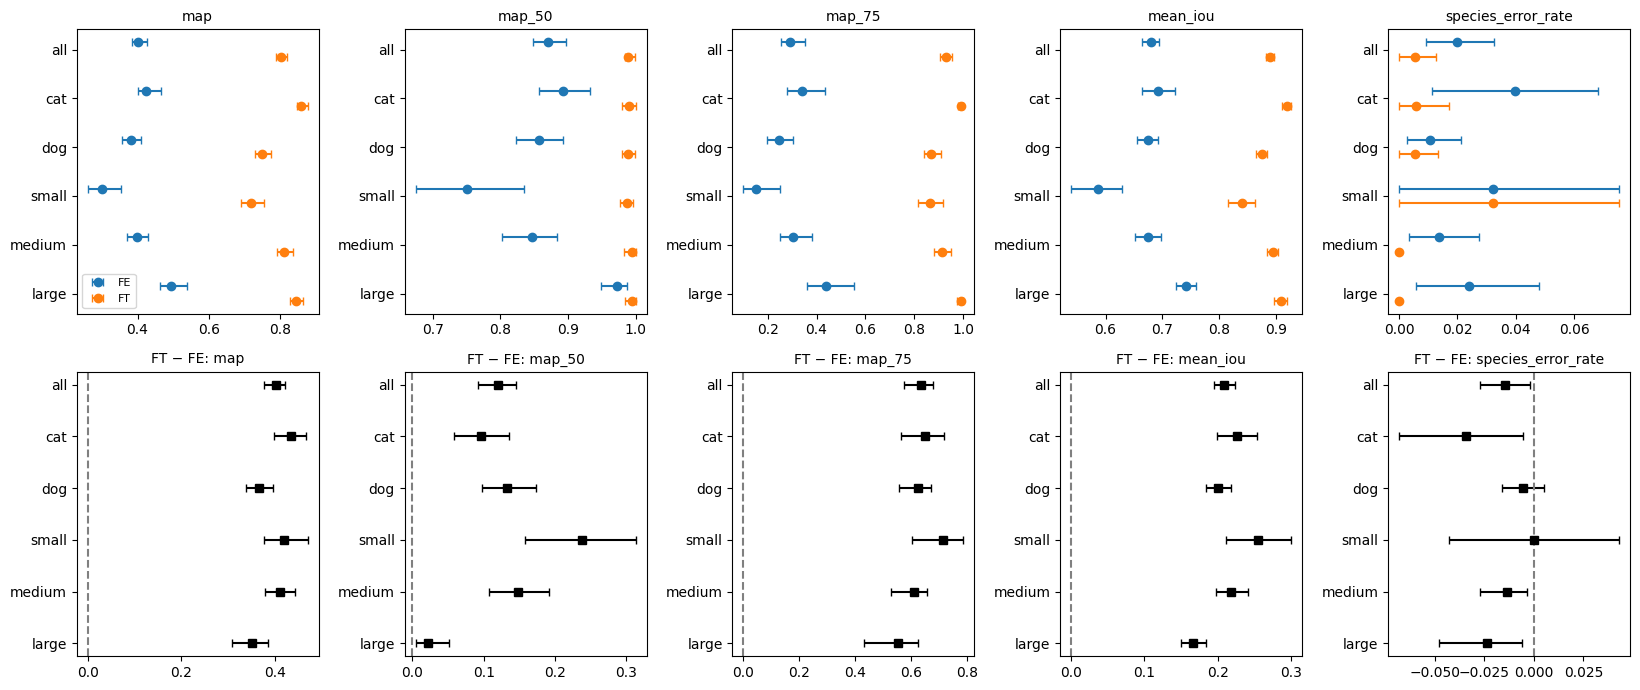

같은 run 안에서 그룹 간 CI 겹침 (False = 차이 있음)


,run,comparison,metric,value_a,value_b,ci_overlap
0,FE,cat vs dog,map,0.424,0.382,True
1,FE,cat vs dog,map_50,0.893,0.856,True
2,FE,cat vs dog,map_75,0.340,0.245,True
3,FE,cat vs dog,mean_iou,0.693,0.674,True
4,FE,cat vs dog,species_error_rate,0.040,0.011,True
5,FE,small vs large,map,0.300,0.494,False
6,FE,small vs large,map_50,0.750,0.973,False
7,FE,small vs large,map_75,0.151,0.437,False
8,FE,small vs large,mean_iou,0.586,0.742,False
9,FE,small vs large,species_error_rate,0.032,0.024,True


In [33]:
def hv_bootstrap_all_groups(results_by_label: dict[str, dict], map_resamples: int, image_resamples: int,
                            top_k: int, seed: int) -> pd.DataFrame:
    """test 전체, SPECIES별, head scale별 bootstrap 결과를 한 표로 모은다."""
    return pd.concat([hv_bootstrap_paired(results_by_label, column, map_resamples, image_resamples, top_k, seed)
                      for column in (None, "species", "scale_group")], ignore_index=True)


def hv_format_ci_table(frame: pd.DataFrame) -> pd.DataFrame:
    """'추정값 [CI 하한, 상한]' 표. 차이 행의 CI가 0을 포함하지 않으면 diff_ci_excludes_0 = True."""
    text = frame.apply(lambda row: f"{row['estimate']:.3f} [{row['ci_low']:.3f}, {row['ci_high']:.3f}]", axis=1)
    keys = ["group_column", "group", "metric"]
    table = frame.assign(value=text).pivot_table(index=keys, columns="run", values="value", aggfunc="first", sort=False)
    diff = frame[frame["run"].str.contains("−")].set_index(keys)
    table["diff_ci_excludes_0"] = ((diff["ci_low"] > 0) | (diff["ci_high"] < 0)).reindex(table.index)
    return table


def hv_group_ci_overlap(frame: pd.DataFrame, run_label: str, group_pairs: list[tuple[str, str]],
                        metrics: list[str]) -> pd.DataFrame:
    """같은 run 안에서 두 그룹(예: cat vs dog)의 CI가 겹치는지 본다. 겹치지 않으면 '차이 있음'."""
    indexed = frame[frame["run"] == run_label].set_index(["group", "metric"])
    rows = []
    for group_a, group_b in group_pairs:
        for metric in metrics:
            if (group_a, metric) not in indexed.index or (group_b, metric) not in indexed.index:
                continue
            a, b = indexed.loc[(group_a, metric)], indexed.loc[(group_b, metric)]
            rows.append({"run": run_label, "comparison": f"{group_a} vs {group_b}", "metric": metric,
                         "value_a": round(a["estimate"], 3), "value_b": round(b["estimate"], 3),
                         "ci_overlap": not (a["ci_low"] > b["ci_high"] or b["ci_low"] > a["ci_high"])})
    return pd.DataFrame(rows)


def hv_plot_forest(frame: pd.DataFrame, metrics: list[str]) -> None:
    """위: 그룹 × run의 추정값과 95% CI. 아래: 두 run의 paired 차이와 95% CI (점선 = 0)."""
    runs = [run for run in frame["run"].unique() if "−" not in run]
    diff_run = next(run for run in frame["run"].unique() if "−" in run)
    groups = list(dict.fromkeys(frame["group"]))
    y = np.arange(len(groups))
    fig, axes = plt.subplots(2, len(metrics), figsize=(3.3 * len(metrics), 7), squeeze=False)
    for col, metric in enumerate(metrics):
        for offset, run, color in zip((-0.15, 0.15), runs, ("tab:blue", "tab:orange")):
            rows = frame[(frame["metric"] == metric) & (frame["run"] == run)].set_index("group").loc[groups]
            axes[0, col].errorbar(rows["estimate"], y + offset, capsize=3, fmt="o", color=color, label=run,
                                  xerr=[rows["estimate"] - rows["ci_low"], rows["ci_high"] - rows["estimate"]])
        rows = frame[(frame["metric"] == metric) & (frame["run"] == diff_run)].set_index("group").loc[groups]
        axes[1, col].errorbar(rows["estimate"], y, capsize=3, fmt="s", color="black",
                              xerr=[rows["estimate"] - rows["ci_low"], rows["ci_high"] - rows["estimate"]])
        axes[1, col].axvline(0, color="gray", linestyle="--")
        for row, title in ((0, metric), (1, f"{diff_run}: {metric}")):
            axes[row, col].set_yticks(y, groups)
            axes[row, col].invert_yaxis()
            axes[row, col].set_title(title, fontsize=10)
    axes[0, 0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


# ---- 실행 ----
HV_A_LABELS = {"FE": HV_FE, "FT": HV_FT}  # 분석 실험(I-1 ~ I-7)에서 쓰는 짧은 이름 → 기존 run
display(pd.DataFrame([{"label": label, "run": run.name, "files": run.file_prefix} for label, run in HV_A_LABELS.items()]))
hv_a = {label: HV_RESULTS[run.name] for label, run in HV_A_LABELS.items()}

HV_A1 = hv_load_or_compute_frame(
    f"{HV_FILE_PREFIX}A1_bootstrap.csv",
    lambda: hv_bootstrap_all_groups(hv_a, map_resamples=100, image_resamples=2000, top_k=100, seed=CONFIG.seed),
    CONFIG.paths)
HV_A1_METRICS = ["map", "map_50", "map_75", "mean_iou", "species_error_rate"]
display(hv_format_ci_table(HV_A1))
hv_plot_forest(HV_A1, HV_A1_METRICS)
print("같은 run 안에서 그룹 간 CI 겹침 (False = 차이 있음)")
display(pd.concat([hv_group_ci_overlap(HV_A1, label, [("cat", "dog"), ("small", "large"), ("small", "medium")],
                                       HV_A1_METRICS) for label in hv_a], ignore_index=True))

**관찰** (95% CI, mAP 계열은 resample 100회, 이미지 단위 지표는 2,000회)

FE vs FT (paired 차이 FT − FE)

| 지표 (all) | FE | FT | FT − FE | 0 포함? |
|---|---|---|---|---|
| mAP | 0.401 [0.384, 0.427] | 0.803 [0.788, 0.819] | +0.402 [0.376, 0.423] | 아니오 |
| mAP@0.5 | 0.870 [0.848, 0.897] | 0.989 [0.984, 0.999] | +0.120 [0.092, 0.145] | 아니오 |
| mAP@0.75 | 0.292 [0.255, 0.352] | 0.930 [0.905, 0.952] | +0.638 [0.577, 0.678] | 아니오 |
| mean IoU | 0.680 [0.665, 0.695] | 0.889 [0.882, 0.897] | +0.209 [0.195, 0.223] | 아니오 |
| SPECIES 오류율 | 0.020 [0.009, 0.033] | 0.005 [0.000, 0.013] | −0.015 [−0.027, −0.002] | 아니오 |

- 그룹별 30개 조합(지표 5 × 그룹 6) 중 paired 차이의 CI가 0을 포함한 것은 2개뿐이다. dog와 small의 SPECIES 오류율이다.
- large의 mAP@0.5 차이는 +0.022 [0.004, 0.052]로, CI 하한이 0에 가깝다.

같은 run 안의 그룹 비교 (CI 겹침 여부)

| 비교 | FE | FT |
|---|---|---|
| cat vs dog: mAP / mAP@0.75 / mean IoU | 모두 겹침 | 모두 **안 겹침** |
| cat vs dog: mAP@0.5 | 겹침 | 겹침 (둘 다 0.990) |
| small vs large: mAP / mAP@0.75 / mean IoU | 모두 **안 겹침** | 모두 **안 겹침** |
| small vs large: mAP@0.5 | **안 겹침** (0.750 vs 0.973) | 겹침 |
| small vs medium: mAP / mean IoU | **안 겹침** | **안 겹침** |
| small vs medium: mAP@0.5 / mAP@0.75 | 겹침 / **안 겹침** | 겹침 / 겹침 |
| SPECIES 오류율 (모든 그룹 비교) | 모두 겹침 | 모두 겹침 |

- FE의 cat SPECIES 오류율은 0.040 [0.011, 0.068], dog는 0.011 [0.003, 0.021]이다. CI가 겹친다.

**판정**

| 비교 | 판정 (표본 noise 기준) |
|---|---|
| FE vs FT (전체·모든 그룹의 박스 지표) | 차이 있음 |
| FT의 cat > dog (mAP, mAP@0.75, mean IoU) | 차이 있음 |
| FE의 cat > dog | 판정 불가 |
| small < large (FE, FT 모두. mAP, mAP@0.75, mean IoU) | 차이 있음 |
| SPECIES 오류율의 그룹 간 차이 (FE의 cat 7장 vs dog 4장 포함) | 판정 불가 |

- H0의 표본 noise 부분은 위 "차이 있음" 항목에 한해 지지한다. seed noise 부분은 I-8에서 판정한다(FE vs FT 차이는 seed noise보다도 크다).
- 주의: CI 겹침은 보수적인 기준이다. 겹쳐도 실제 차이가 있을 수 있다. 그룹 간 비교는 이미지가 달라 paired 차이를 쓸 수 없다.

### I-2. BREED별 경계 정밀도와 GT 박스의 변동 (H5)
**가설**: dog의 경계 정밀도(mean IoU, mAP@0.75)가 cat보다 낮은 것은 dog BREED가 더 다양하기 때문이다. GT 박스가 dog에서 덜 일관된 것도 원인일 수 있다.

**방법**
- test의 CLASS-ID(BREED)별로 FE와 FT의 mean IoU와 IoU ≥ 0.75 비율을 구한다.
- GT 쪽 변동은 BREED별로 측정한다. 대상은 train / val / test 전체 이미지다.
  - 머리 박스 모양: log(가로 / 세로)의 표준편차
  - 크기: head scale의 변동계수(CV)
- BREED는 37개이고 test에는 BREED마다 약 15장이 있다. 그래서 BREED 하나의 값은 noise가 크다. 개별 BREED보다 **분포 전체의 경향**을 본다.

**판정 기준**
1. FT mean IoU 하위 25% BREED 중 dog 비율이 전체 BREED 중 dog 비율(25/37 = 0.68)보다 뚜렷하게 높아야 한다.
2. GT 변동(log aspect sd)과 FT mean IoU의 Spearman ρ < −0.3이고 95% CI가 0을 포함하지 않아야 한다.
   - 1만 성립하면 "BREED 다양성"을 약하게 지지한다.
   - 1과 2가 함께 성립하면 "GT/머리 모양의 변동"을 지지한다.

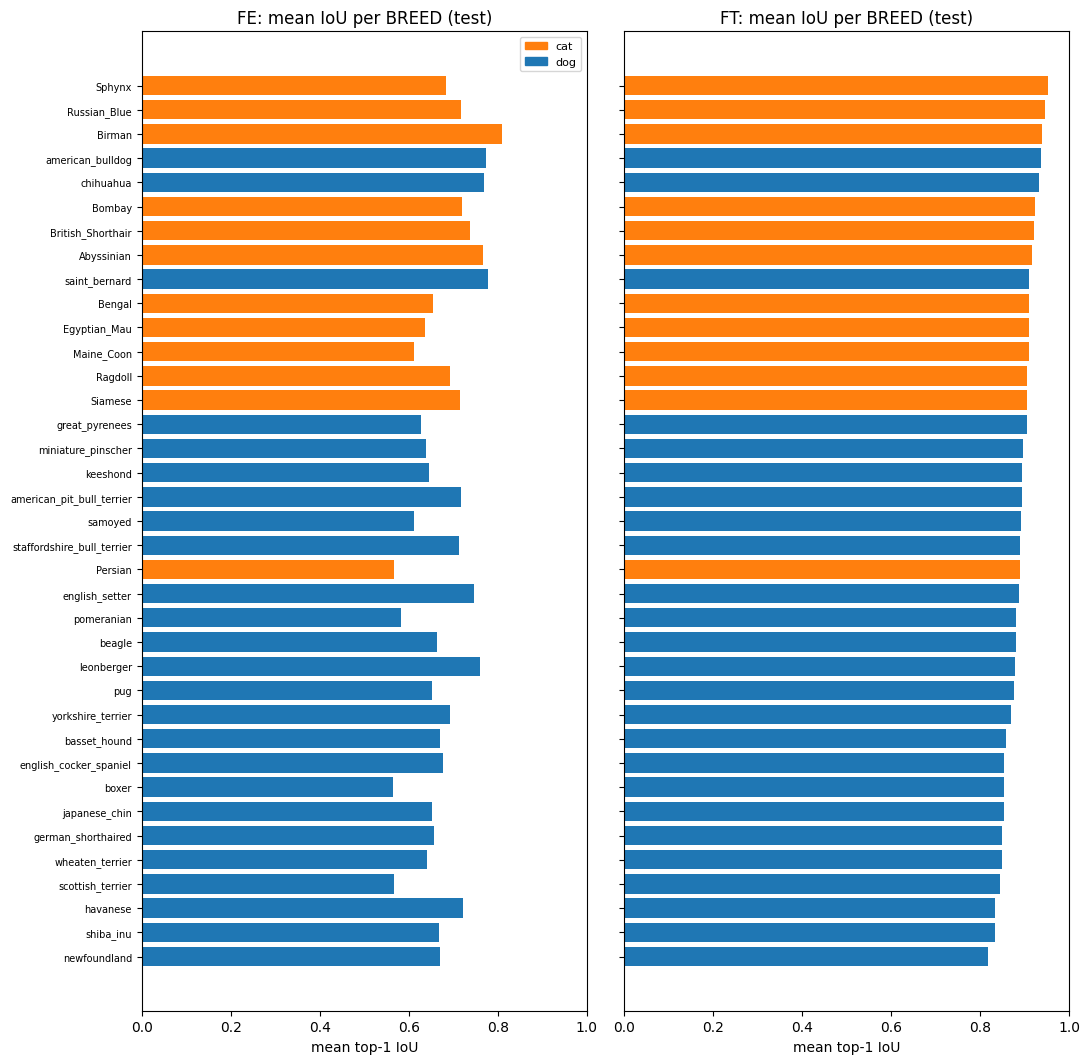

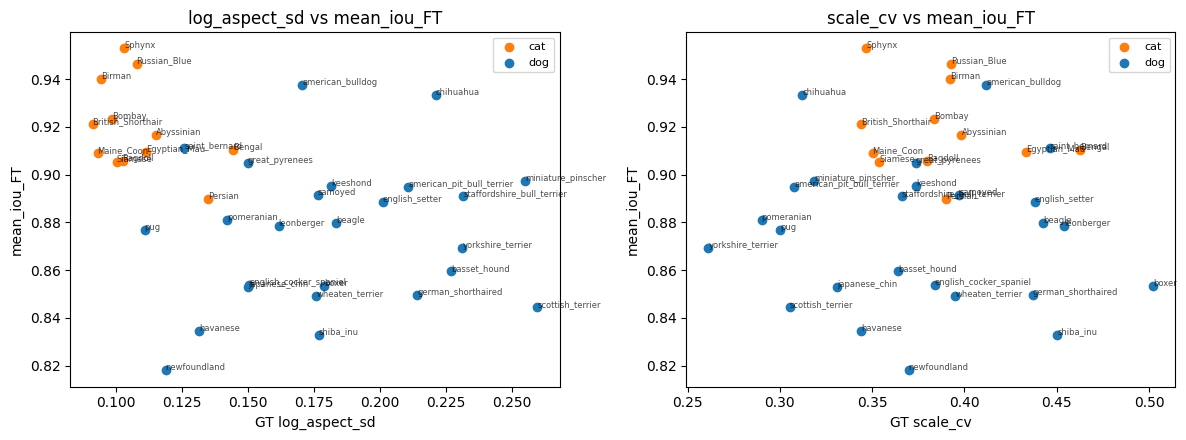

FT mean IoU 하위 25% BREED 10개 중 dog 비율: 1.00 (전체 BREED 중 dog 비율: 0.68)


,species,breed,images,mean_iou_FT,iou_ge_75_FT,mean_iou_FE,iou_ge_75_FE,gt_images,log_aspect_sd,scale_cv
27,dog,newfoundland,15,0.818,0.800,0.671,0.267,96,0.119,0.370
33,dog,shiba_inu,15,0.833,0.733,0.669,0.200,100,0.177,0.450
22,dog,havanese,15,0.835,0.733,0.722,0.600,100,0.131,0.344
32,dog,scottish_terrier,15,0.845,0.867,0.566,0.133,100,0.260,0.305
35,dog,wheaten_terrier,15,0.849,0.867,0.640,0.533,100,0.176,0.395
20,dog,german_shorthaired,15,0.850,0.933,0.657,0.400,100,0.214,0.437
23,dog,japanese_chin,15,0.853,0.933,0.653,0.333,100,0.150,0.331
16,dog,boxer,15,0.853,0.733,0.565,0.267,100,0.179,0.502
18,dog,english_cocker_spaniel,15,0.854,0.867,0.677,0.267,96,0.151,0.384
14,dog,basset_hound,15,0.859,0.867,0.669,0.400,100,0.227,0.364


,n,rho,ci_low,ci_high
log_aspect_sd,37.0,-0.474,-0.690,-0.145
scale_cv,37.0,0.047,-0.285,0.360


In [34]:
def hv_breed_table(per_image: pd.DataFrame) -> pd.DataFrame:
    """test BREED별 이미지 수, mean IoU, IoU ≥ 0.75 비율."""
    table = per_image.assign(breed=per_image["image"].map(breed_of), iou_ge_75=per_image["top1_iou"] >= 0.75)
    return (table.groupby(["species", "breed"])
            .agg(images=("image", "size"), mean_iou=("top1_iou", "mean"), iou_ge_75=("iou_ge_75", "mean"))
            .reset_index())


def hv_gt_variability_by_breed(records: pd.DataFrame, image_cache: dict[str, dict]) -> pd.DataFrame:
    """BREED별 GT 머리 박스의 모양(log aspect sd)과 크기(scale CV). 캐시의 축소 이미지 기준 (비율은 축소와 무관)."""
    rows = []
    for row in records.itertuples(index=False):
        if row.image not in image_cache:
            continue
        entry = image_cache[row.image]
        boxes = entry["boxes"]
        height, width = entry["image"].shape[-2:]
        log_aspect = torch.log((boxes[:, 2] - boxes[:, 0]) / (boxes[:, 3] - boxes[:, 1])).mean().item()
        rows.append({"species": row.species, "breed": row.breed, "log_aspect": log_aspect,
                     "scale": head_scale(boxes, height, width)})
    frame = pd.DataFrame(rows)
    return (frame.groupby(["species", "breed"])
            .agg(gt_images=("breed", "size"), log_aspect_sd=("log_aspect", "std"),
                 scale_cv=("scale", lambda s: s.std() / s.mean()))
            .reset_index())


def hv_spearman(x: np.ndarray, y: np.ndarray) -> float:
    """Spearman 순위 상관 (순위로 바꾼 뒤 Pearson)."""
    return float(pd.Series(x).rank().corr(pd.Series(y).rank()))


def hv_spearman_ci(x, y, resamples: int, seed: int) -> dict[str, float]:
    """Spearman ρ와 bootstrap 95% CI."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    rng = np.random.default_rng(seed)
    samples = [hv_spearman(x[idx], y[idx]) for idx in rng.integers(0, len(x), size=(resamples, len(x)))]
    low, high = hv_percentile_ci(np.array(samples))
    return {"n": len(x), "rho": hv_spearman(x, y), "ci_low": low, "ci_high": high}


def hv_plot_breed_iou(breeds_by_label: dict[str, pd.DataFrame], sort_label: str) -> None:
    """run마다 BREED별 mean IoU 막대 (색 = SPECIES). sort_label run의 값으로 정렬한다."""
    order = breeds_by_label[sort_label].sort_values("mean_iou")["breed"].tolist()
    colors = {"cat": "tab:orange", "dog": "tab:blue"}
    fig, axes = plt.subplots(1, len(breeds_by_label), figsize=(5.5 * len(breeds_by_label), 0.25 * len(order) + 1.5),
                             sharey=True, squeeze=False)
    for ax, (label, breeds) in zip(axes[0], breeds_by_label.items()):
        rows = breeds.set_index("breed").loc[order]
        ax.barh(order, rows["mean_iou"], color=[colors[s] for s in rows["species"]])
        ax.set(title=f"{label}: mean IoU per BREED (test)", xlabel="mean top-1 IoU", xlim=(0, 1))
        ax.tick_params(axis="y", labelsize=7)
    axes[0, 0].legend(handles=[patches.Patch(color=c, label=s) for s, c in colors.items()], fontsize=8)
    plt.tight_layout()
    plt.show()


def hv_plot_gt_variability(merged: pd.DataFrame, iou_column: str, variability_columns: list[str]) -> None:
    """BREED마다 GT 변동 vs mean IoU 산점도 (글자 = BREED)."""
    colors = {"cat": "tab:orange", "dog": "tab:blue"}
    fig, axes = plt.subplots(1, len(variability_columns), figsize=(6 * len(variability_columns), 4.5), squeeze=False)
    for ax, column in zip(axes[0], variability_columns):
        for species, rows in merged.groupby("species"):
            ax.scatter(rows[column], rows[iou_column], color=colors[species], label=species)
            for row in rows.itertuples(index=False):
                ax.annotate(row.breed, (getattr(row, column), getattr(row, iou_column)), fontsize=6, alpha=0.7)
        ax.set(xlabel=f"GT {column}", ylabel=iou_column, title=f"{column} vs {iou_column}")
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


# ---- 실행 ----
hv_breeds = {label: hv_breed_table(results["per_image"]) for label, results in hv_a.items()}
hv_gt_var = hv_gt_variability_by_breed(RECORDS, IMAGE_CACHE)
HV_A2 = (hv_breeds["FT"].merge(hv_breeds["FE"][["breed", "mean_iou", "iou_ge_75"]], on="breed", suffixes=("_FT", "_FE"))
         .merge(hv_gt_var, on=["species", "breed"]))
hv_plot_breed_iou(hv_breeds, sort_label="FT")
hv_plot_gt_variability(HV_A2, "mean_iou_FT", ["log_aspect_sd", "scale_cv"])

hv_bottom = HV_A2[HV_A2["mean_iou_FT"] <= HV_A2["mean_iou_FT"].quantile(0.25)]
print(f"FT mean IoU 하위 25% BREED {len(hv_bottom)}개 중 dog 비율: {(hv_bottom['species'] == 'dog').mean():.2f} "
      f"(전체 BREED 중 dog 비율: {(HV_A2['species'] == 'dog').mean():.2f})")
display(hv_bottom.sort_values("mean_iou_FT").round(3))
display(pd.DataFrame({column: hv_spearman_ci(HV_A2[column], HV_A2["mean_iou_FT"], resamples=2000, seed=CONFIG.seed)
                      for column in ("log_aspect_sd", "scale_cv")}).T.round(3))

**관찰**
- 판정 기준 1: FT mean IoU 하위 25% BREED 10개는 **모두 dog**다(1.00). 전체 BREED 중 dog 비율은 0.68이다.
  - 참고 계산: 37개 중 10개를 무작위로 뽑을 때 10개가 모두 dog일 확률(초기하분포)은 약 0.009다.
- FE에서는 하위권에 cat도 섞인다. 예를 들어 Persian의 FE mean IoU는 0.57로 하위권이다. FT에서는 Persian도 0.89로 중간이다(그림).
- FT 하위 3개: newfoundland 0.818, shiba_inu 0.833, havanese 0.835

| GT 변동 지표 vs FT mean IoU (BREED 37개) | Spearman ρ | 95% CI |
|---|---|---|
| log aspect sd (머리 박스 모양의 변동) | **−0.474** | [−0.690, −0.145] |
| scale CV (크기의 변동) | 0.047 | [−0.285, 0.360] |

- 산점도에서 cat BREED는 대부분 log aspect sd 0.09 ~ 0.14, FT mean IoU 0.89 ~ 0.95에 몰려 있다. dog BREED는 sd 0.11 ~ 0.26으로 넓게 퍼져 있다.
- 예를 들어 newfoundland는 sd 0.119로 작은데 IoU가 가장 낮다. chihuahua는 sd 0.221로 큰데 IoU 0.933이다.

**보완 관찰**: SPECIES 안의 상관 (bootstrap 2,000회)
> 보완 분석: 로컬의 `hv_FE/FT_test_predictions.pt`와 XML annotation으로 계산했다. 먼저 이 셀의 출력(mean IoU, BREED 37개 ρ = −0.474 [−0.690, −0.145])을 같은 값으로 재현한 뒤 계산했다. 노트북 코드셀로는 아직 넣지 않았다.

| 범위 | BREED 수 | ρ(log aspect sd, FT mean IoU) | 95% CI |
|---|---|---|---|
| 전체 (재현) | 37 | −0.474 | [−0.690, −0.145] |
| dog만 | 25 | **0.118** | [−0.304, 0.528] |
| cat만 | 12 | −0.189 | [−0.695, 0.410] |
| SPECIES 평균을 뺀 값 (37개) | 37 | 0.036 | [−0.310, 0.404] |

- SPECIES 평균: log aspect sd는 cat 0.108, dog 0.181이다. FT mean IoU는 cat 0.919, dog 0.875다.
- 전체의 음의 상관은 SPECIES 평균의 차이를 빼면 사라진다(0.036). dog 안에서는 부호가 오히려 양수다. 하지만 CI가 넓어 −0.3도 배제하지 못한다.

**판정** (보완 분석 반영으로 수정)
- 사전 기준 1과 2는 형식상 모두 성립한다. 하지만 기준 2의 상관은 SPECIES 차이로 설명된다. SPECIES 안에서는 상관이 없다(dog ρ = 0.118, SPECIES 평균을 뺀 값 ρ = 0.036).
- 그래서 "GT/머리 모양의 변동" 설명은 **판정 불가**로 낮춘다. 근거가 SPECIES 수준의 차이 하나뿐이고, BREED 단위로는 보이지 않는다. dog 25개로는 검정력이 낮아 기각도 하지 않는다.
- 기준 1(하위 BREED가 모두 dog)은 남는다. 사전 기준대로 "BREED 다양성"을 **약하게 지지**한다. 이 기준도 "dog 전체가 어렵다"는 것과 구분되지 않는다.
- 크기 변동(scale CV)은 IoU와 관계가 없다.

**가설** (검증 안 됨)
- log aspect sd가 큰 이유가 "BREED 안에서 실제 머리 모양이 다양함"인지 "annotation 기준이 일정하지 않음"인지는 이 지표로 구분할 수 없다. 둘 다 같은 값을 만든다.
- dog가 cat보다 IoU가 낮은 원인은 BREED별 박스 모양의 변동이 아닌 다른 SPECIES 차이일 수 있다. 예를 들면 털 길이 때문에 경계가 흐릿하거나, 귀와 주둥이가 박스 경계에 걸친다. 이 실험으로는 구분할 수 없다.
- 다음 확인: FT 하위 BREED(newfoundland, shiba_inu, havanese)의 GT 박스와 예측을 겹쳐 그려 annotation 기준(귀 포함 여부 등)을 본다.

### I-3. head scale과 IoU의 관계 (H6)
**가설**: small head의 성능이 낮은 원인은 입력 해상도(300×300)다. FE에서는 동결된 feature 문제가 겹친다.

**방법**
- scale을 그룹 3개로 나누지 않고 **연속값**으로 쓴다. scale과 top-1 IoU의 Spearman ρ를 FE와 FT 각각에서 구한다.
- scale 5분위별 mean IoU 곡선을 그린다.

**판정 기준**

| 결과 | 해석 |
|---|---|
| FT에서도 ρ > 0이고 CI가 0을 포함하지 않는다 | 해상도(입력 크기) 요인을 지지한다. backbone을 다 학습해도 남는 경향이기 때문이다 |
| ρ가 FE에서만 크고 FT에서는 0 근처다 | feature 요인 쪽에 무게가 실린다 |

주의: small head 이미지는 배경이 넓거나 동물이 멀리 있는 사진이 많다. 그래서 scale 효과와 촬영 조건 효과가 섞여 있다. 이 분석은 상관이며 인과가 아니다. 해상도 자체를 바꾸는 실험은 범위에서 뺐다(I 머리말).

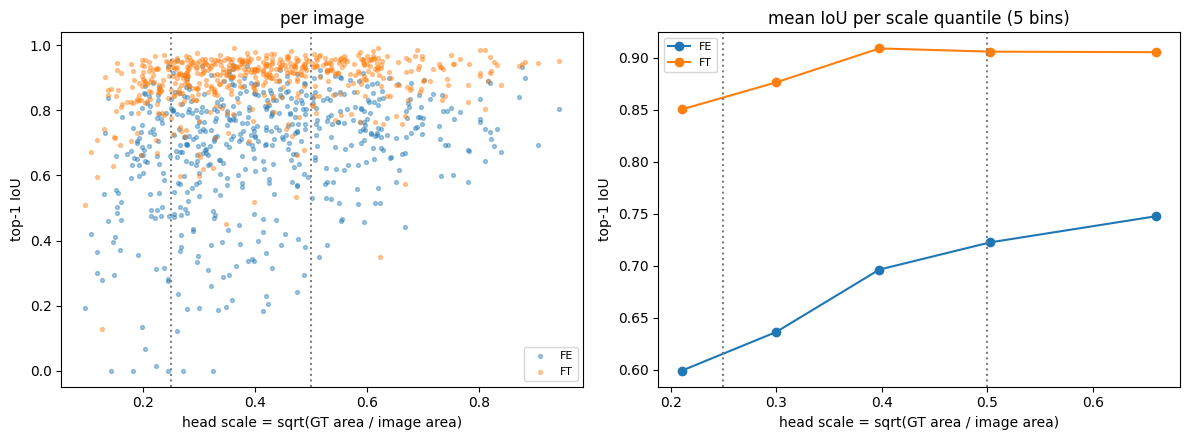

Spearman ρ(scale, top-1 IoU)


,n,rho,ci_low,ci_high
FE,551.0,0.273,0.197,0.346
FT,551.0,0.290,0.207,0.366


In [35]:
def hv_quantile_curve(per_image: pd.DataFrame, x_column: str, y_column: str, num_bins: int) -> pd.DataFrame:
    """x를 분위로 나눈 bin마다 x 중앙값, y 평균, 이미지 수."""
    bins = pd.qcut(per_image[x_column], q=num_bins, duplicates="drop")
    return (per_image.groupby(bins, observed=True)
            .agg(x_median=(x_column, "median"), y_mean=(y_column, "mean"), images=(y_column, "size"))
            .reset_index(drop=True))


def hv_plot_scale_vs_iou(per_image_by_label: dict[str, pd.DataFrame], num_bins: int, scale_bins: tuple[float, float]) -> None:
    """왼쪽: scale vs top-1 IoU 산점도. 오른쪽: scale 분위별 mean IoU (점선 = F-3의 그룹 경계)."""
    fig, (ax_scatter, ax_curve) = plt.subplots(1, 2, figsize=(12, 4.5))
    for (label, per_image), color in zip(per_image_by_label.items(), ("tab:blue", "tab:orange")):
        ax_scatter.scatter(per_image["scale"], per_image["top1_iou"], s=8, alpha=0.4, color=color, label=label)
        curve = hv_quantile_curve(per_image, "scale", "top1_iou", num_bins)
        ax_curve.plot(curve["x_median"], curve["y_mean"], marker="o", color=color, label=label)
    for ax in (ax_scatter, ax_curve):
        for boundary in scale_bins:
            ax.axvline(boundary, color="gray", linestyle=":")
        ax.set(xlabel="head scale = sqrt(GT area / image area)", ylabel="top-1 IoU")
        ax.legend(fontsize=8)
    ax_scatter.set_title("per image")
    ax_curve.set_title(f"mean IoU per scale quantile ({num_bins} bins)")
    plt.tight_layout()
    plt.show()


# ---- 실행 ----
hv_plot_scale_vs_iou({label: results["per_image"] for label, results in hv_a.items()}, num_bins=5,
                     scale_bins=HV_SCALE_BINS)
HV_A3 = pd.DataFrame({label: hv_spearman_ci(results["per_image"]["scale"], results["per_image"]["top1_iou"],
                                            resamples=2000, seed=CONFIG.seed)
                      for label, results in hv_a.items()}).T
print("Spearman ρ(scale, top-1 IoU)")
display(HV_A3.round(3))

**관찰**

| run | Spearman ρ(scale, top-1 IoU) | 95% CI |
|---|---|---|
| FE | 0.273 | [0.197, 0.346] |
| FT | 0.290 | [0.207, 0.366] |

- 두 run의 ρ는 거의 같고, CI가 크게 겹친다.
- 분위 곡선의 **모양**은 다르다. 아래 값은 그림에서 읽은 근사값이다.

| scale 5분위 (중앙값 약) | 0.21 | 0.30 | 0.40 | 0.50 | 0.66 |
|---|---|---|---|---|---|
| FE mean IoU | 0.60 | 0.64 | 0.70 | 0.72 | 0.75 |
| FT mean IoU | 0.85 | 0.88 | 0.91 | 0.91 | 0.91 |

- FT는 scale 0.4 이상에서 평평하다. 상승은 아래 두 분위에만 있다. FE는 마지막 분위까지 계속 오른다.
- FE와 FT의 차이는 가장 작은 분위에서 약 0.25, 가장 큰 분위에서 약 0.16이다.

**판정**
- "해상도 요인": FT에서도 ρ > 0이고 CI가 0을 포함하지 않는다. 사전 기준에 따라 **지지**한다(상관 수준).
- "FE에만 feature 요인이 겹친다": ρ 기준으로는 FE에서만 크다는 패턴이 없다. 이 분석으로는 **지지 근거가 없다**. 학습 실험(I-9)에서도 conv4를 풀 때 small mAP가 전체 mAP만큼만 올라, small 고유의 feature 요인은 보이지 않았다.

**가설** (검증 안 됨)
- FT 곡선이 작은 scale에서만 떨어지는 것은 "일정 크기 아래에서만 해상도가 병목"이라는 설명과 맞는다.
- 다른 설명도 가능하다. 같은 픽셀 오차라도 박스가 작으면 IoU가 더 크게 떨어진다(IoU 지표 자체의 성질). 그리고 small head 사진은 촬영 조건(먼 거리, 넓은 배경)이 다르다. 이 분석은 세 요인을 분리하지 못한다.

### I-4. top-1 score로 실패를 가려낼 수 있는가 (H7)
**가설**: 실패 사례(F-4)는 top-1 score가 모두 0.55 이하였다. 그렇다면 score가 낮을수록 실패할 가능성이 높고, score threshold로 실패를 걸러낼 수 있다.

**방법**
- 실패를 "top-1 IoU < 0.5"로 정한다.
- top-1 score와 IoU의 Spearman ρ를 구한다.
- "score가 낮을수록 실패"라는 규칙의 AUROC를 구하고, 95% CI는 bootstrap 2,000회로 구한다.
- threshold별로 남는 이미지 비율과 남은 이미지의 mean IoU를 본다.

**판정 기준**
- AUROC ≥ 0.8이고 CI 하한 > 0.5이면 지지한다.
- 실패가 10장 미만인 run은 CI가 넓다. 그런 run은 판정 불가로 둔다.

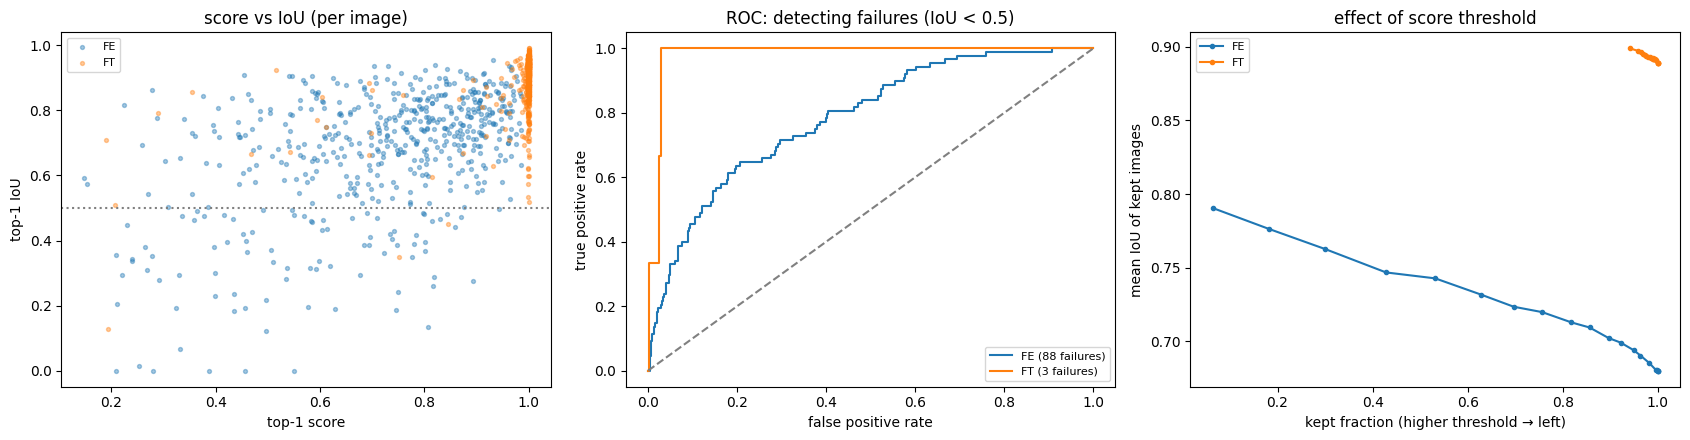

,failures,auroc,ci_low,ci_high,spearman_rho,spearman_ci_low,spearman_ci_high
FE,88.0,0.785,0.734,0.833,0.399,0.322,0.472
FT,3.0,0.981,0.962,1.000,0.386,0.314,0.454


FE                                            FT  \
          kept_fraction kept_mean_iou kept_failure_rate kept_fraction   
threshold                                                               
0.3               0.964         0.690             0.141         0.993   
0.5               0.857         0.709             0.106         0.989   
0.7               0.628         0.732             0.072         0.975   

                                           
          kept_mean_iou kept_failure_rate  
threshold                                  
0.3               0.892             0.004  
0.5               0.892             0.004  
0.7               0.894             0.004

In [36]:
def hv_auroc_ci(is_failure: np.ndarray, risk: np.ndarray, resamples: int, seed: int) -> dict[str, float]:
    """risk(클수록 실패 가능성이 높다고 보는 값)로 실패를 판별하는 AUROC와 bootstrap 95% CI."""
    if is_failure.all() or not is_failure.any():
        return {"failures": int(is_failure.sum()), "auroc": np.nan, "ci_low": np.nan, "ci_high": np.nan}
    rng = np.random.default_rng(seed)
    samples = []
    for idx in rng.integers(0, len(risk), size=(resamples, len(risk))):
        if is_failure[idx].any() and not is_failure[idx].all():
            samples.append(roc_auc_score(is_failure[idx], risk[idx]))
    low, high = hv_percentile_ci(np.array(samples))
    return {"failures": int(is_failure.sum()), "auroc": roc_auc_score(is_failure, risk), "ci_low": low, "ci_high": high}


def hv_threshold_curve(per_image: pd.DataFrame, thresholds: np.ndarray) -> pd.DataFrame:
    """score threshold마다 남는 이미지 비율, 남은 이미지의 mean IoU와 실패율."""
    rows = []
    for threshold in thresholds:
        kept = per_image[per_image["top1_score"] >= threshold]
        rows.append({"threshold": threshold, "kept_fraction": len(kept) / len(per_image),
                     "kept_mean_iou": kept["top1_iou"].mean() if len(kept) else np.nan,
                     "kept_failure_rate": (kept["top1_iou"] < 0.5).mean() if len(kept) else np.nan})
    return pd.DataFrame(rows)


def hv_plot_score_failure(per_image_by_label: dict[str, pd.DataFrame], iou_threshold: float,
                          thresholds: np.ndarray) -> None:
    """score vs IoU 산점도, ROC, threshold 곡선."""
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for (label, per_image), color in zip(per_image_by_label.items(), ("tab:blue", "tab:orange")):
        axes[0].scatter(per_image["top1_score"], per_image["top1_iou"], s=8, alpha=0.4, color=color, label=label)
        is_failure = (per_image["top1_iou"] < iou_threshold).to_numpy()
        if is_failure.any() and not is_failure.all():
            fpr, tpr, _ = roc_curve(is_failure, -per_image["top1_score"].to_numpy())
            axes[1].plot(fpr, tpr, color=color, label=f"{label} ({is_failure.sum()} failures)")
        curve = hv_threshold_curve(per_image, thresholds)
        axes[2].plot(curve["kept_fraction"], curve["kept_mean_iou"], marker=".", color=color, label=label)
    axes[0].axhline(iou_threshold, color="gray", linestyle=":")
    axes[0].set(xlabel="top-1 score", ylabel="top-1 IoU", title="score vs IoU (per image)")
    axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--")
    axes[1].set(xlabel="false positive rate", ylabel="true positive rate", title=f"ROC: detecting failures (IoU < {iou_threshold})")
    axes[2].set(xlabel="kept fraction (higher threshold → left)", ylabel="mean IoU of kept images",
                title="effect of score threshold")
    for ax in axes:
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


# ---- 실행 ----
hv_thresholds = np.round(np.arange(0.0, 1.0, 0.05), 2)
hv_plot_score_failure({label: results["per_image"] for label, results in hv_a.items()}, iou_threshold=0.5,
                      thresholds=hv_thresholds)
HV_A4 = pd.DataFrame({
    label: {**hv_auroc_ci((r["per_image"]["top1_iou"] < 0.5).to_numpy(), -r["per_image"]["top1_score"].to_numpy(),
                          resamples=2000, seed=CONFIG.seed),
            **{f"spearman_{key}": value for key, value in
               hv_spearman_ci(r["per_image"]["top1_score"], r["per_image"]["top1_iou"], 2000, CONFIG.seed).items()
               if key != "n"}}
    for label, r in hv_a.items()}).T
display(HV_A4.round(3))
display(pd.concat({label: hv_threshold_curve(r["per_image"], np.array([0.3, 0.5, 0.7])).set_index("threshold")
                   for label, r in hv_a.items()}, axis=1).round(3))

**관찰** (실패 = top-1 IoU < 0.5)

| run | 실패 수 | AUROC [95% CI] | Spearman ρ(score, IoU) [95% CI] |
|---|---|---|---|
| FE | 88 / 551 (16.0%) | **0.785** [0.734, 0.833] | 0.399 [0.322, 0.472] |
| FT | 3 / 551 (0.5%) | 0.981 [0.962, 1.000] | 0.386 [0.314, 0.454] |

FE에서 threshold별로 남는 이미지 (표의 비율에서 장 수를 역산)

| threshold | 남는 비율 | 남은 mean IoU | 남은 실패율 | 남은 실패 수 (88장 중) |
|---|---|---|---|---|
| 없음 | 1.000 | 0.680 | 0.160 | 88 |
| 0.3 | 0.964 | 0.690 | 0.141 | 약 75 |
| 0.5 | 0.857 | 0.709 | 0.106 | 약 50 |
| 0.7 | 0.628 | 0.732 | 0.072 | 약 25 |

- FE 실패 88장 중 약 50장(57%)은 score가 0.5 이상이다. 산점도에서도 score 0.6 ~ 0.95에 실패가 흩어져 있다. F-4에서 본 "실패는 모두 score ≤ 0.55"는 F-4에 고른 사례에만 해당한다.
- FT는 score가 거의 모두 0.95 이상에 몰려 있다. 실패 3장 중 2장은 score 0.7 이상이다.

**판정**
- FE: AUROC 점추정 0.785가 사전 기준 0.8에 못 미친다. 다만 CI [0.734, 0.833]이 0.8을 포함한다. 따라서 **판정 불가(경계)**로 둔다. score에 판별력이 있다는 것(CI 하한 > 0.5)은 확실하다. 하지만 threshold만으로 실패를 걸러내기는 어렵다. 0.7에서 이미지 37%를 버려도 실패의 약 28%가 남는다.
- FT: 실패가 3장(< 10장)이라 사전 기준에 따라 **판정 불가**다.

### I-5. 박스 크기의 치우침과 머리 밝기 (H8)
**가설**: FT에 남은 오류는 "머리를 놓침"이 아니라 "박스가 느슨함"이다. 즉 예측 박스가 GT보다 크다. 이런 경향은 털이 검은 머리에서 더 강하다.

**방법**
- 이미지마다 top-1 예측 박스 면적 ÷ GT 박스 면적의 log2 값을 구한다. GT는 IoU가 가장 큰 박스를 쓴다. 0이면 크기가 같고, 1이면 2배다.
- GT 박스 안 grayscale 평균 밝기(0 ~ 1)를 구한다.
- FT 전체와 FT top-1 IoU 하위 10%의 분포를 비교한다.

**판정 기준**
- "느슨한 박스": FT 하위 10%에서 log2 면적 비의 중앙값이 0보다 크고, 면적 비가 1보다 큰 이미지가 60% 이상이면 지지한다.
- "검은 털": FT 전체에서 밝기와 log2 면적 비의 Spearman ρ < −0.2이고 CI가 0을 포함하지 않으면 지지한다. 어두울수록 박스가 크다는 뜻이다.

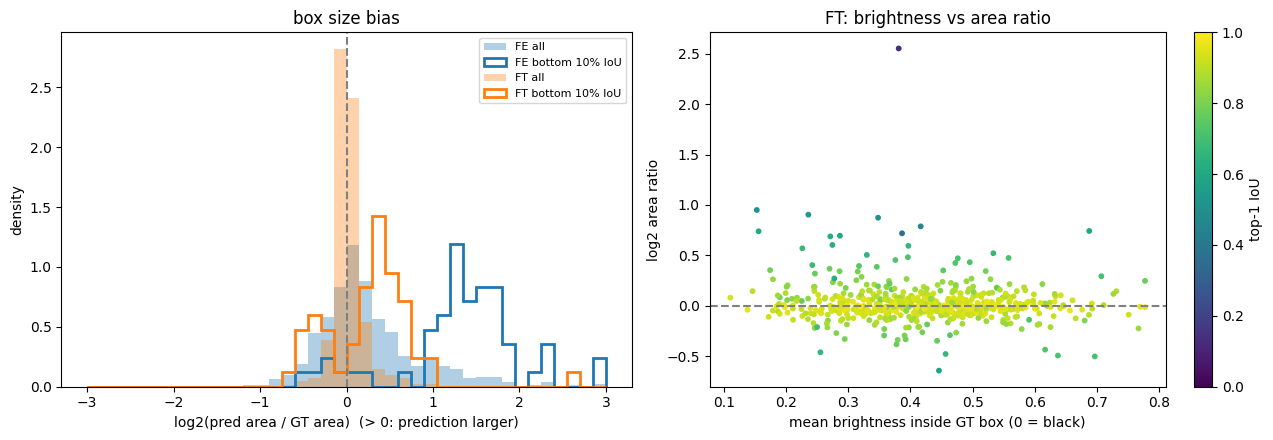

,median_log2_ratio_all,median_log2_ratio_bottom,bigger_share_bottom,bottom_images,rho_brightness_ratio_rho,rho_brightness_ratio_ci_low,rho_brightness_ratio_ci_high,rho_brightness_iou_rho,rho_brightness_iou_ci_low,rho_brightness_iou_ci_high
FE,0.141,1.352,0.911,56.0,0.008,-0.075,0.093,0.009,-0.074,0.095
FT,-0.000,0.343,0.732,56.0,-0.052,-0.137,0.034,0.088,0.007,0.168


FT: 가장 어두운 머리 8장


,image,species,top1_iou,log2_area_ratio,gt_brightness
447,scottish_terrier_129,dog,0.937,0.080,0.110
75,saint_bernard_131,dog,0.958,-0.040,0.138
516,Bombay_188,cat,0.892,0.145,0.146
196,scottish_terrier_108,dog,0.518,0.950,0.153
23,keeshond_155,dog,0.599,0.739,0.156
20,scottish_terrier_122,dog,0.927,-0.110,0.172
541,japanese_chin_129,dog,0.783,0.354,0.174
191,staffordshire_bull_terrier_131,dog,0.918,-0.049,0.179


In [37]:
def hv_box_geometry(per_image: pd.DataFrame, predictions: list[dict], ground_truths: list[dict],
                    image_cache: dict[str, dict]) -> pd.DataFrame:
    """이미지별 log2(예측 면적 / GT 면적)과 GT 박스 안 평균 밝기. 예측이 없으면 면적 비는 NaN."""
    luminance = torch.tensor([0.299, 0.587, 0.114]).view(3, 1, 1)
    rows = []
    for index, (prediction, ground_truth) in enumerate(zip(predictions, ground_truths)):
        name = per_image.loc[index, "image"]
        gt_boxes = ground_truth["boxes"]
        log2_ratio, gt_index = np.nan, 0
        if len(prediction["scores"]) > 0:
            top_box = prediction["boxes"][prediction["scores"].argmax()].unsqueeze(0)
            gt_index = int(box_iou(top_box, gt_boxes).argmax())
            areas = torchvision.ops.box_area(torch.cat([top_box, gt_boxes[gt_index:gt_index + 1]]))
            log2_ratio = math.log2(max(areas[0].item(), 1e-6) / areas[1].item())
        image = image_cache[name]["image"].float() / 255
        x0, y0, x1, y1 = gt_boxes[gt_index].round().int().tolist()
        region = (image * luminance).sum(dim=0)[max(0, y0):max(y0 + 1, y1), max(0, x0):max(x0 + 1, x1)]
        rows.append({"image": name, "species": per_image.loc[index, "species"],
                     "top1_iou": per_image.loc[index, "top1_iou"], "log2_area_ratio": log2_ratio,
                     "gt_brightness": region.mean().item()})
    return pd.DataFrame(rows)


def hv_geometry_summary(geometry: pd.DataFrame, bottom_fraction: float, resamples: int, seed: int) -> dict:
    """전체·하위 bottom_fraction에서 면적 비 분포, 밝기와의 상관."""
    valid = geometry.dropna(subset=["log2_area_ratio"])
    bottom = valid[valid["top1_iou"] <= valid["top1_iou"].quantile(bottom_fraction)]
    ratio_vs_brightness = hv_spearman_ci(valid["gt_brightness"], valid["log2_area_ratio"], resamples, seed)
    iou_vs_brightness = hv_spearman_ci(valid["gt_brightness"], valid["top1_iou"], resamples, seed)
    return {"median_log2_ratio_all": valid["log2_area_ratio"].median(),
            "median_log2_ratio_bottom": bottom["log2_area_ratio"].median(),
            "bigger_share_bottom": (bottom["log2_area_ratio"] > 0).mean(), "bottom_images": len(bottom),
            **{f"rho_brightness_ratio_{k}": v for k, v in ratio_vs_brightness.items() if k != "n"},
            **{f"rho_brightness_iou_{k}": v for k, v in iou_vs_brightness.items() if k != "n"}}


def hv_plot_geometry(geometry_by_label: dict[str, pd.DataFrame], bottom_fraction: float, focus_label: str) -> None:
    """왼쪽: 면적 비 분포 (전체 / 하위). 오른쪽: focus run의 밝기 vs 면적 비 (색 = IoU)."""
    fig, (ax_hist, ax_scatter) = plt.subplots(1, 2, figsize=(13, 4.5))
    bins = np.linspace(-3, 3, 41)
    for (label, geometry), color in zip(geometry_by_label.items(), ("tab:blue", "tab:orange")):
        valid = geometry.dropna(subset=["log2_area_ratio"])
        bottom = valid[valid["top1_iou"] <= valid["top1_iou"].quantile(bottom_fraction)]
        ax_hist.hist(valid["log2_area_ratio"].clip(-3, 3), bins=bins, alpha=0.35, color=color, density=True,
                     label=f"{label} all")
        ax_hist.hist(bottom["log2_area_ratio"].clip(-3, 3), bins=bins, histtype="step", linewidth=2, color=color,
                     density=True, label=f"{label} bottom {bottom_fraction:.0%} IoU")
    ax_hist.axvline(0, color="gray", linestyle="--")
    ax_hist.set(xlabel="log2(pred area / GT area)  (> 0: prediction larger)", ylabel="density", title="box size bias")
    ax_hist.legend(fontsize=8)
    focus = geometry_by_label[focus_label].dropna(subset=["log2_area_ratio"])
    points = ax_scatter.scatter(focus["gt_brightness"], focus["log2_area_ratio"].clip(-3, 3), c=focus["top1_iou"],
                                cmap="viridis", s=10, vmin=0, vmax=1)
    fig.colorbar(points, ax=ax_scatter, label="top-1 IoU")
    ax_scatter.axhline(0, color="gray", linestyle="--")
    ax_scatter.set(xlabel="mean brightness inside GT box (0 = black)", ylabel="log2 area ratio", title=f"{focus_label}: brightness vs area ratio")
    plt.tight_layout()
    plt.show()


# ---- 실행 ----
hv_geometry = {label: hv_box_geometry(r["per_image"], r["predictions"], r["ground_truths"], IMAGE_CACHE)
               for label, r in hv_a.items()}
hv_plot_geometry(hv_geometry, bottom_fraction=0.1, focus_label="FT")
HV_A5 = pd.DataFrame({label: hv_geometry_summary(geometry, 0.1, 2000, CONFIG.seed)
                      for label, geometry in hv_geometry.items()}).T
display(HV_A5.round(3))
print("FT: 가장 어두운 머리 8장")
display(hv_geometry["FT"].nsmallest(8, "gt_brightness").round(3))

**관찰** (log2 면적 비 = log2(예측 면적 / GT 면적), 0이면 크기가 같음)

| run | 전체 중앙값 | 하위 10% (56장) 중앙값 | 하위 10% 중 예측이 더 큰 비율 |
|---|---|---|---|
| FE | 0.141 (1.10배) | **1.352** (2.55배) | 91.1% |
| FT | −0.000 (1.00배) | **0.343** (1.27배) | 73.2% |

| FT, Spearman ρ | 값 | 95% CI |
|---|---|---|
| GT 밝기 vs log2 면적 비 | −0.052 | [−0.137, 0.034] |
| GT 밝기 vs top-1 IoU | 0.088 | [0.007, 0.168] |

- FT 전체는 0 근처에 뾰족하게 몰려 있다. 하위 10%는 0.25 ~ 0.75 쪽에 몰리지만, 일부(약 27%)는 0보다 작다. 즉 예측이 더 작다.
- FT에서 가장 어두운 머리 8장 중 6장은 top-1 IoU가 0.78 이상이다. 나머지 두 장(scottish_terrier_108: 0.518, keeshond_155: 0.599)은 log2 면적 비가 0.95, 0.74로 박스가 크다.

**보완 관찰**: 하위 10%의 top-1 박스와 GT의 관계
> 보완 분석: 로컬의 `hv_FE/FT_test_predictions.pt`와 XML annotation으로 계산했다. 먼저 이 셀의 출력(mean IoU, BREED 37개 ρ = −0.474 [−0.690, −0.145])을 같은 값으로 재현한 뒤 계산했다. 노트북 코드셀로는 아직 넣지 않았다.

| 유형 (기준 0.9) | 정의 | FE (56장) | FT (56장) |
|---|---|---|---|
| GT를 감쌈 (느슨함) | intersection / GT ≥ 0.9이고 예측이 더 큼 | 25 (45%) | **35 (62.5%)** |
| GT 안쪽 (작음) | intersection / 예측 ≥ 0.9이고 예측이 더 작음 | 0 | 13 (23%) |
| 어긋남 | 그 밖 | **31 (55%)** | 8 (14%) |

| 중앙값 | FE | FT |
|---|---|---|
| intersection / GT (하위 10%) | 0.886 | 0.946 |
| intersection / 예측 (하위 10%) | 0.321 | 0.776 |
| intersection / GT ≥ 0.9인 비율 (전체 → 하위 10%) | 52.6% → 44.6% | 87.8% → 62.5% |

- FT 하위 10%의 대부분은 GT 머리를 거의 다 포함하면서 더 넓은 박스다. FE 하위 10%는 절반 이상이 GT와 어긋나 있다. FE의 예측 박스는 GT보다 훨씬 크다(예측 면적 중 GT와 겹치는 부분의 중앙값 32%).

**판정**
- "느슨한 박스": FT 하위 10%의 중앙값 0.343 > 0이고, 더 큰 비율 73.2% ≥ 60%다. **지지**한다. 보완 분석에서도 62.5%가 GT를 감싸는 박스였다. 위치가 어긋난 것이 아니라 넓은 것이다. 단, 23%는 반대로 GT보다 작다.
- "검은 털에서 커진다": ρ = −0.052이고 CI가 0을 포함한다. 사전 기준(ρ < −0.2)에 못 미쳐 **기각**한다. 밝기와 IoU의 ρ(0.088)는 CI가 0을 겨우 넘지만 크기가 매우 작다.

**가설** (검증 안 됨)
- FE 하위 10%가 "크고 어긋난" 박스인 것은 F-6의 가설(COCO feature가 몸 전체 박스를 내는 쪽으로 기운다)과 맞는다. 하지만 이 분석은 박스가 몸 쪽으로 넓어졌는지는 보지 않았다.
- 밝기는 GT 박스 안 전체 평균이라 배경이 섞인다. "털 색" 지표로는 거칠다. 그래서 기각은 "이 지표로는 관계가 보이지 않는다"는 뜻이다.

### I-6. 추론 시 prior 보정으로 SPECIES 오류 보기 (H4, 재학습 없이)
**가설**: cat을 dog로 잘못 말하는 오류는 train의 SPECIES 불균형(Cat : Dog = 1 : 2.1) 때문이다. 모델이 dog 쪽으로 기울어 있다는 해석이다.

**방법**
- 학습은 다시 하지 않는다. 예측의 dog score만 r로 나누고 top-1 label을 다시 고른다. 이렇게 하면 학습 prior의 영향을 근사적으로 되돌릴 수 있다.
- r 값: 1(원래), 1.5, train의 dog/cat 비율, 3, 5
- 방향별 오류 수(cat → dog, dog → cat)를 센다.
- 주의
  - score는 (background, cat, dog) softmax에서 나온 값이다. 그래서 이 보정은 prior shift의 **근사**일 뿐이다.
  - top-1이 다른 박스로 바뀔 수 있다. 여기서는 label만 센다.

**판정 기준**
- r = train 비율에서 cat → dog 오류가 줄고, dog → cat 오류가 그만큼 늘지 않으면 불균형 가설을 **약하게** 지지한다.
- 이 결과만으로는 원인이 확정되지 않는다. 학습으로 확인하는 실험은 I-12다.

train SPECIES: {'dog': 1742, 'cat': 829}, dog / cat = 2.1


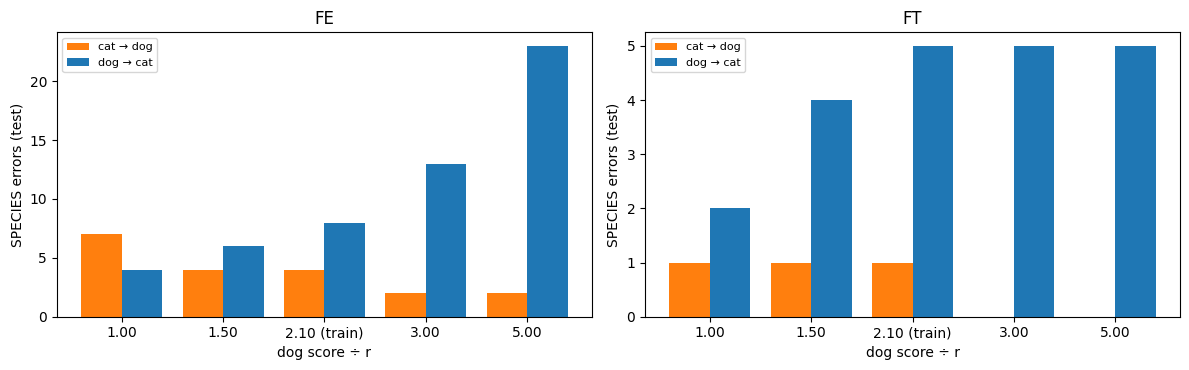

FE                                FT                      
  dog_divisor cat_as_dog dog_as_cat dog_divisor cat_as_dog dog_as_cat
0         1.0          7          4         1.0          1          2
1         1.5          4          6         1.5          1          4
2         2.1          4          8         2.1          1          5
3         3.0          2         13         3.0          0          5
4         5.0          2         23         5.0          0          5

In [38]:
def hv_prior_corrected_errors(predictions: list[dict], per_image: pd.DataFrame, class_names: tuple[str, ...],
                              dog_divisors: list[float]) -> pd.DataFrame:
    """dog 예측의 score를 r로 나눈 뒤 top-1 label을 다시 골라 방향별 SPECIES 오류 수를 센다."""
    dog = class_names.index("dog")
    rows = []
    for divisor in dog_divisors:
        top_labels = []
        for prediction in predictions:
            if len(prediction["scores"]) == 0:
                top_labels.append(None)
                continue
            adjusted = prediction["scores"] / (1.0 + (divisor - 1.0) * (prediction["labels"] == dog).float())
            top_labels.append(class_names[int(prediction["labels"][adjusted.argmax()])])
        rows.append({"dog_divisor": divisor, **hv_species_errors(per_image.assign(top1_label=top_labels))})
    return pd.DataFrame(rows)


def hv_plot_prior_correction(errors_by_label: dict[str, pd.DataFrame], train_ratio: float) -> None:
    """run마다 r별 방향별 오류 수 막대."""
    fig, axes = plt.subplots(1, len(errors_by_label), figsize=(6 * len(errors_by_label), 3.8), squeeze=False)
    for ax, (label, errors) in zip(axes[0], errors_by_label.items()):
        x = np.arange(len(errors))
        ax.bar(x - 0.2, errors["cat_as_dog"], width=0.4, label="cat → dog", color="tab:orange")
        ax.bar(x + 0.2, errors["dog_as_cat"], width=0.4, label="dog → cat", color="tab:blue")
        ax.set_xticks(x, [f"{r:.2f}" + (" (train)" if math.isclose(r, train_ratio) else "") for r in errors["dog_divisor"]])
        ax.set(xlabel="dog score ÷ r", ylabel="SPECIES errors (test)", title=label)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


# ---- 실행 ----
hv_train_species = RECORDS.set_index("image").loc[SPLIT_NAMES["train"], "species"].value_counts()
hv_train_ratio = round(hv_train_species["dog"] / hv_train_species["cat"], 2)
print(f"train SPECIES: {hv_train_species.to_dict()}, dog / cat = {hv_train_ratio}")
hv_divisors = sorted({1.0, 1.5, hv_train_ratio, 3.0, 5.0})
HV_A6 = {label: hv_prior_corrected_errors(r["predictions"], r["per_image"], CONFIG.data.class_names, hv_divisors)
         for label, r in hv_a.items()}
hv_plot_prior_correction(HV_A6, hv_train_ratio)
display(pd.concat(HV_A6, axis=1))

**관찰** (train dog / cat = 1742 / 829 = 2.1)

| dog score ÷ r | FE cat → dog | FE dog → cat | FE 합계 | FT cat → dog | FT dog → cat | FT 합계 |
|---|---|---|---|---|---|---|
| 1.0 (원래) | 7 | 4 | **11** | 1 | 2 | **3** |
| 1.5 | 4 | 6 | 10 | 1 | 4 | 5 |
| 2.1 (train 비율) | 4 | 8 | 12 | 1 | 5 | 6 |
| 3.0 | 2 | 13 | 15 | 0 | 5 | 5 |
| 5.0 | 2 | 23 | 25 | 0 | 5 | 5 |

- FE: r = 2.1에서 cat → dog는 3장 줄고, dog → cat은 4장 늘었다. 합계는 r = 1.5에서 10장으로 가장 작지만, r = 1과 1장 차이다.
- FT: cat → dog는 r = 3까지 1장 그대로다. dog → cat만 늘었다.

**보완 관찰**: 오류 이미지의 cat / dog score 차이
> 보완 분석: 로컬의 `hv_FE/FT_test_predictions.pt`와 XML annotation으로 계산했다. 먼저 이 셀의 출력(mean IoU, BREED 37개 ρ = −0.474 [−0.690, −0.145])을 같은 값으로 재현한 뒤 계산했다. 노트북 코드셀로는 아직 넣지 않았다.
- 지표: dog 박스 최고 score ÷ cat 박스 최고 score. r이 이 값보다 크면 cat → dog 오류가 바로잡힌다.

| FE 오류 | 이미지 | dog / cat score 비 | top-1 IoU |
|---|---|---|---|
| cat → dog (7) | Sphynx_15, Sphynx_114, Sphynx_192 | 1.29, 1.32, 1.34 | 0.91, 0.86, 0.07 |
| | Persian_112, Sphynx_148 | 2.21, 2.61 | 0.89, 0.85 |
| | Persian_194, Sphynx_190 | 8.69, 10.21 | 0.40, 0.34 |
| dog → cat (4) | yorkshire_terrier_170, samoyed_138, japanese_chin_119, keeshond_16 | 0.33, 0.28, 0.25, 0.10 (cat이 3 ~ 10배 높음) | 0.83, 0.32, 0.69, 0.46 |

- FE cat → dog 7장은 모두 **Sphynx(5)와 Persian(2)**이다. 나머지 cat BREED 10개에서는 0장이다.
- 7장 중 5장은 score 비가 2.6 이하다. FE의 정답 이미지에서 (정답 class score ÷ 오답 class score)는 하위 5%가 3.6, 중앙값이 28.8이다. 즉 이 5장은 경계 근처다. 나머지 2장(비 8.7, 10.2)은 IoU도 0.4 이하라 위치도 틀렸다.
- FE 정답 이미지 중 score 비가 2 미만인 것은 8장이다. r을 키우면 이 중 dog 이미지가 dog → cat 오류로 넘어간다.
- FT 오류 3장: keeshond_16(FE에서도 오류), shiba_inu_120(dog → cat), Egyptian_Mau_140(cat → dog, 비 2.33)

**판정**: 사전 기준("cat → dog가 줄고, dog → cat이 그만큼 늘지 않는다")에 못 미친다. 불균형 가설을 **지지하지 않는다**. 오류는 한 방향에서 다른 방향으로 옮겨 갈 뿐이다.
- 이 실험은 prior shift의 근사다. 그리고 오류 수가 한 자릿수라 noise가 크다(I-1: FE cat 오류율 CI [0.011, 0.068]). 그래서 이 결과만으로 H4를 기각하지는 않는다. 학습 실험 결과는 I-12에 있다.

- 보완 분석의 관찰: cat → dog 오류의 대부분(5/7)은 실제로 경계 근처다. 하지만 r을 키우면 정답 이미지 중 경계 근처의 dog도 함께 넘어간다. 이것이 "옮겨 갈 뿐"인 결과와 맞는다.

**가설** (검증 안 됨): FE cat → dog 오류가 Sphynx와 Persian에만 몰린 것은 SPECIES 전체의 prior가 아니라 BREED의 외형(털 없는 피부, 납작한 얼굴) 때문일 수 있다. prior 불균형만이 원인이라면 다른 cat BREED에도 오류가 흩어져야 한다고 예상할 수 있다. 하지만 오류가 7장뿐이라 이 예상을 검정할 수는 없다. I-12(균형 sampling)에서 확인했다. balanced run에서 score 비가 1.4 이하인 Sphynx 3장은 바로잡혔지만, score 비가 큰 Sphynx_190·Persian_194·Persian_112는 seed 2개 모두에서 남았다.

### I-7. epoch 시간 구성 (H9)
**가설**: FT는 학습 파라미터가 25배인데 epoch 시간은 1.3배다. FE와 FT가 공통으로 쓰는 단계(forward, 데이터 로딩, val 예측)가 시간 대부분을 차지하기 때문이다.

**방법**
- FE(`head`)와 FT(`all`) 설정으로 **새 모델**을 만든다. 학습한 가중치는 저장하지 않는다.
- train batch 30개(앞의 3개는 warmup으로 제외)를 돌리며 단계별 시간을 잰다. 단계는 데이터 대기, forward(loss 포함), backward, optimizer step이다. GPU 비동기 실행 때문에 단계마다 `synchronize` 후 잰다.
- val 예측 1회와 val 지표 계산 1회도 잰다.
- batch당 시간 × epoch당 step 수 + val 시간으로 epoch 시간을 추정하고, 실제 기록(`epoch_time_sec`)과 비교한다.
- 측정 자체가 `synchronize` 때문에 약간 느려진다. 비율 비교에 쓴다.

**판정 기준**: 아래 두 조건이 모두 성립하면 지지한다.
- FT − FE 시간 차이의 대부분(> 50%)이 backward·optimizer 단계에서 나온다.
- FE epoch 시간에서 공통 단계(데이터, forward, val)의 비중이 50%를 넘는다.

predict:   0%|          | 0/18 [00:00<?, ?it/s]

predict:   0%|          | 0/18 [00:00<?, ?it/s]

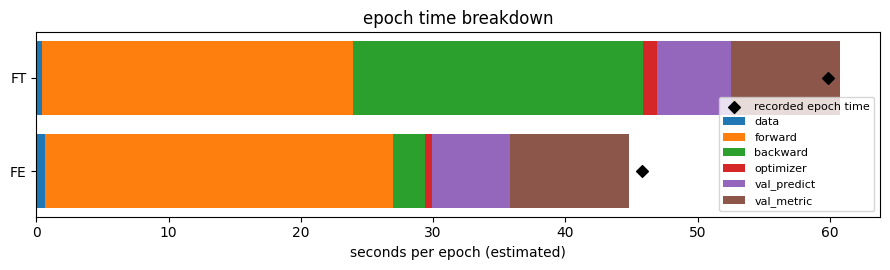

,FE,FT,FT − FE,share of FT − FE,share of FE epoch
data,0.645,0.409,-0.236,-0.015,0.014
forward,26.327,23.505,-2.822,-0.177,0.588
backward,2.448,21.949,19.501,1.220,0.055
optimizer,0.518,1.044,0.526,0.033,0.012
val_predict,5.883,5.591,-0.292,-0.018,0.131
val_metric,8.953,8.258,-0.696,-0.044,0.200


기록된 epoch 시간(초): {'FE': np.float64(45.8), 'FT': np.float64(59.9)}


In [39]:
def hv_synchronize(device: torch.device) -> None:
    """GPU 비동기 실행을 기다린다 (시간 측정용)."""
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    elif device.type == "mps":
        torch.mps.synchronize()


def hv_profile_epoch(config: ExperimentConfig, datasets: dict[str, Dataset], device: torch.device,
                     num_batches: int, warmup_batches: int) -> dict[str, float]:
    """새 모델로 train step을 단계별로 재고, epoch 하나의 단계별 시간(초)을 추정한다. 가중치는 저장하지 않는다."""
    seed_everything(config.seed)
    model = build_ssd300_for_head_detection(len(config.data.class_names), config.model.image_size)
    hv_apply_trainable_scope(model, config.model.trainable_scope)
    model.to(device).train()
    use_amp = config.train.use_amp and device.type == "cuda"
    optimizer = build_optimizer(model, config.train)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    pin_memory = device.type == "cuda"
    loader = build_dataloader(datasets["train"], config.data.batch_size, shuffle=True,
                              num_workers=config.data.num_workers, pin_memory=pin_memory, seed=config.seed)

    totals = defaultdict(float)
    iterator = iter(loader)
    for step in range(warmup_batches + num_batches):
        start = time.perf_counter()
        try:
            images, targets = next(iterator)
        except StopIteration:  # train이 짧으면(smoke) 처음부터 다시
            iterator = iter(loader)
            images, targets = next(iterator)
        images, targets = move_batch_to_device(images, targets, device)
        hv_synchronize(device)
        loaded = time.perf_counter()
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            loss_dict = model(images, targets)
            loss = loss_dict["classification"] + loss_dict["bbox_regression"]
        hv_synchronize(device)
        forwarded = time.perf_counter()
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        hv_synchronize(device)
        backwarded = time.perf_counter()
        scaler.step(optimizer)
        scaler.update()
        hv_synchronize(device)
        stepped = time.perf_counter()
        if step >= warmup_batches:
            totals["data"] += loaded - start
            totals["forward"] += forwarded - loaded
            totals["backward"] += backwarded - forwarded
            totals["optimizer"] += stepped - backwarded
    steps_per_epoch = len(loader)
    estimate = {stage: seconds / num_batches * steps_per_epoch for stage, seconds in totals.items()}

    val_loader = build_dataloader(datasets["val"], config.data.eval_batch_size, shuffle=False,
                                  num_workers=config.data.num_workers, pin_memory=pin_memory, seed=config.seed)
    start = time.perf_counter()
    predictions, ground_truths = predict(model, val_loader, device, use_amp)
    hv_synchronize(device)
    estimate["val_predict"] = time.perf_counter() - start
    start = time.perf_counter()
    compute_detection_metrics(predictions, ground_truths, config.data.class_names)
    estimate["val_metric"] = time.perf_counter() - start
    del model, optimizer, loader, val_loader
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return estimate


def hv_plot_epoch_breakdown(breakdown: pd.DataFrame, measured: dict[str, float]) -> None:
    """run별 단계 누적 막대(추정)와 실제 기록된 epoch 시간(◆)."""
    fig, ax = plt.subplots(figsize=(9, 2.8))
    left = np.zeros(len(breakdown))
    for stage in breakdown.columns:
        ax.barh(breakdown.index, breakdown[stage], left=left, label=stage)
        left += breakdown[stage].to_numpy()
    for y, label in enumerate(breakdown.index):
        if not math.isnan(measured.get(label, np.nan)):
            ax.scatter([measured[label]], [y], marker="D", color="black", zorder=5,
                       label="recorded epoch time" if y == 0 else None)
    ax.set(xlabel="seconds per epoch (estimated)", title="epoch time breakdown")
    ax.legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.show()


# ---- 실행 ----
hv_profile_batches = 3 if HV_SMOKE else 30
HV_A7 = pd.DataFrame({label: hv_profile_epoch(run.config, DATASETS, DEVICE, num_batches=hv_profile_batches,
                                              warmup_batches=3)
                      for label, run in HV_A_LABELS.items()}).T
hv_measured = {label: (pd.DataFrame(r["history"])["epoch_time_sec"].mean() if r["history"] else np.nan)
               for label, r in hv_a.items()}
hv_plot_epoch_breakdown(HV_A7, hv_measured)
hv_breakdown = HV_A7.T.assign(**{"FT − FE": lambda t: t["FT"] - t["FE"]})
hv_breakdown["share of FT − FE"] = hv_breakdown["FT − FE"] / hv_breakdown["FT − FE"].sum()
hv_breakdown["share of FE epoch"] = hv_breakdown["FE"] / hv_breakdown["FE"].sum()
display(hv_breakdown.round(3))
print("기록된 epoch 시간(초):", {label: round(value, 1) for label, value in hv_measured.items()})

**관찰** (epoch당 초. 추정치 = batch 시간 × step 수 + val 시간)

| 단계 | FE | FT | FT − FE | FT − FE 중 비중 | FE epoch 중 비중 |
|---|---|---|---|---|---|
| data | 0.65 | 0.41 | −0.24 | −1% | 1% |
| forward (loss 포함) | 26.33 | 23.51 | −2.82 | −18% | **59%** |
| backward | 2.45 | 21.95 | +19.50 | **122%** | 5% |
| optimizer | 0.52 | 1.04 | +0.53 | 3% | 1% |
| val predict | 5.88 | 5.59 | −0.29 | −2% | 13% |
| val metric | 8.95 | 8.26 | −0.70 | −4% | **20%** |
| 합계 (추정) | 44.8 | 60.8 | +16.0 | | |
| 기록된 epoch 시간 | 45.8 | 59.9 | +14.1 | | |

- FT − FE 차이의 125%가 backward·optimizer에서 나온다. 다른 단계에서는 FT가 조금씩 빨라서 합이 100%를 넘는다.
- FE epoch에서 공통 단계(data + forward + val)가 차지하는 비중은 93%다.
- FT의 backward는 FE의 9.0배다. 학습 파라미터는 25배다.
- 추정치를 기록과 비교하면 FE 0.98배, FT 1.01배다.
- val 지표 계산(COCO 평가, 약 9초)이 val 예측(약 6초)보다 오래 걸린다.
- 이 셀은 캐시를 쓰지 않고 실행할 때마다 다시 잰다. 이전 세션에서 잰 값(차이의 108%, 공통 단계 94%, FT 추정 68.0초)과 수치는 몇 초씩 다르다. 판정은 같다.

**판정**: 사전 기준 두 가지가 모두 성립한다. 차이의 50% 넘게 backward·optimizer에서 나오고, FE에서 공통 단계의 비중이 50%를 넘는다. 따라서 H9를 **지지**한다.

**가설** (검증 안 됨): forward 시간이 가장 긴 이유로 두 가지를 생각할 수 있다. backbone 전체를 매번 통과해야 하고, loss 계산(anchor matching, hard negative mining)도 forward에 들어 있다. 이 측정은 두 부분을 나누지 않았다.

### I-8. seed 반복 (H0, 학습 실험 `B1`)
**목적**: seed만 바꿔 FE와 FT를 2번씩 더 학습한다. 기존 seed 42와 합쳐 3개다. 이것으로 **seed noise**(같은 설정에서 test 지표가 흔들리는 폭)를 잰다. I-9 ~ I-12의 모든 비교는 이 noise를 기준으로 판정한다.
- split, 증강 설정, 하이퍼파라미터는 모두 같다.
- seed가 바꾸는 것은 head 초기화, batch 순서, 증강 난수다.

**판정 기준**
- FE와 FT의 차이가 각 설정 sd의 2배를 넘으면 seed noise보다 크다고 본다(H0의 seed 부분).
- run이 1개뿐이면 sd를 계산할 수 없다. 이 경우 이후 셀의 판정은 모두 "판정 불가"다.

=== [1/4] scope-head_lr-2e-3_ep-30_pat-7_sampler-random_seed-1
체크포인트에서 재개: epoch 30 (/content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/outputs)
이미 끝난 run이다. 저장된 기록을 돌려준다.
=== [2/4] scope-head_lr-2e-3_ep-30_pat-7_sampler-random_seed-2
체크포인트에서 재개: epoch 30 (/content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/outputs)
이미 끝난 run이다. 저장된 기록을 돌려준다.
=== [3/4] scope-all_lr-2e-3_ep-30_pat-7_sampler-random_seed-1
체크포인트에서 재개: epoch 30 (/content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/outputs)
이미 끝난 run이다. 저장된 기록을 돌려준다.
=== [4/4] scope-all_lr-2e-3_ep-30_pat-7_sampler-random_seed-2
체크포인트에서 재개: epoch 30 (/content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/outputs)
이미 끝난 run이다. 저장된 기록을 돌려준다.


,seed,scope,map,map_50,map_75,mean_iou,map_small,ap_cat,ap_dog,cat_as_dog,dog_as_cat,best_epoch
run,,,,,,,,,,,,
scope-head_lr-2e-3_ep-30_pat-7_sampler-random_seed-42,42,head,0.401,0.870,0.292,0.680,0.300,0.421,0.381,7,4,24
scope-all_lr-2e-3_ep-30_pat-7_sampler-random_seed-42,42,all,0.803,0.989,0.930,0.889,0.720,0.858,0.749,1,2,29
scope-head_lr-2e-3_ep-30_pat-7_sampler-random_seed-1,1,head,0.414,0.870,0.340,0.690,0.301,0.435,0.392,8,4,28
scope-head_lr-2e-3_ep-30_pat-7_sampler-random_seed-2,2,head,0.419,0.868,0.355,0.691,0.303,0.445,0.393,4,4,29
scope-all_lr-2e-3_ep-30_pat-7_sampler-random_seed-1,1,all,0.806,0.998,0.939,0.890,0.724,0.854,0.759,2,3,26
scope-all_lr-2e-3_ep-30_pat-7_sampler-random_seed-2,2,all,0.802,0.994,0.920,0.884,0.714,0.857,0.747,0,1,27


map          map_50          map_75         mean_iou          \
         mean     std    mean     std    mean     std     mean     std   
scope                                                                    
head   0.4114  0.0092  0.8695  0.0009  0.3287  0.0329   0.6870  0.0059   
all    0.8039  0.0023  0.9939  0.0044  0.9297  0.0094   0.8879  0.0031   

      map_small          ap_cat          ap_dog         cat_as_dog          \
           mean     std    mean     std    mean     std       mean     std   
scope                                                                        
head     0.3013  0.0015  0.4340  0.0119  0.3887  0.0068     6.3333  2.0817   
all      0.7191  0.0052  0.8564  0.0022  0.7515  0.0066     1.0000  1.0000   

      dog_as_cat       n  
            mean  std     
scope                     
head         4.0  0.0  3  
all          2.0  1.0  3

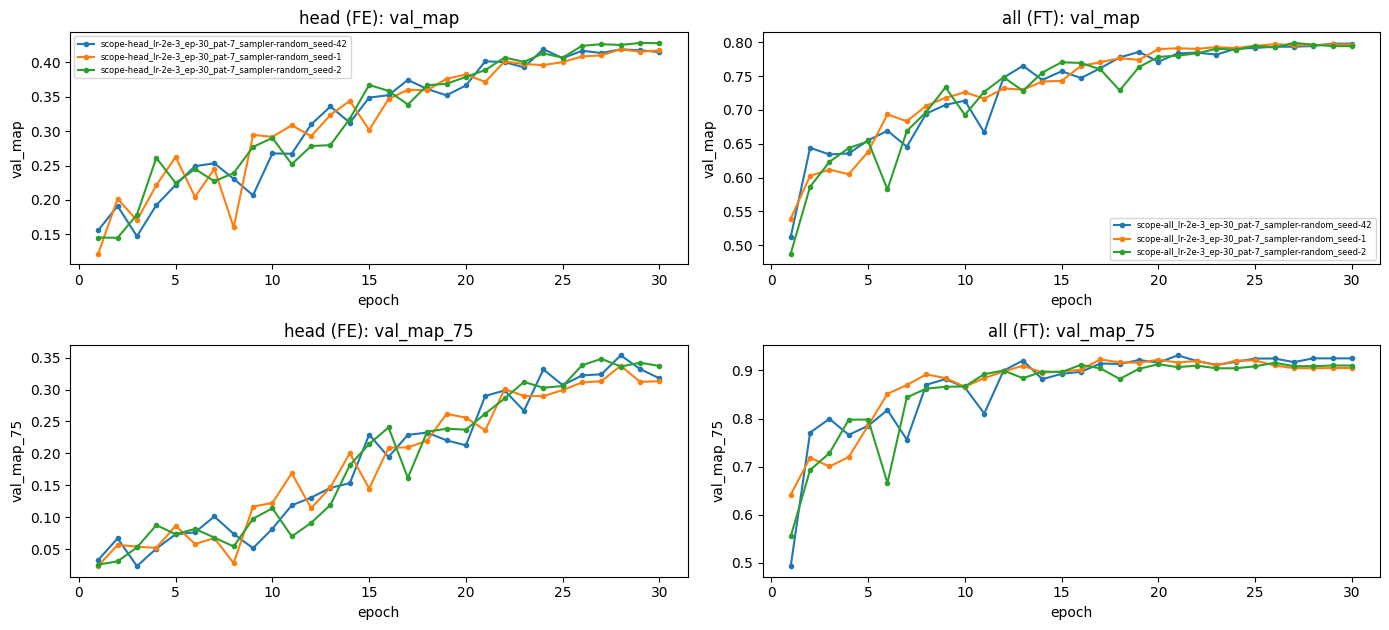

In [40]:
def hv_plot_val_curves(panels: dict[str, list[HVRun]], results_by_name: dict[str, dict],
                       history_columns: list[str]) -> None:
    """패널(열)마다 run들의 epoch별 기록을 겹쳐 그린다. 행 = history_columns."""
    fig, axes = plt.subplots(len(history_columns), len(panels),
                             figsize=(7 * len(panels), 3.2 * len(history_columns)), squeeze=False)
    for col, (title, runs) in enumerate(panels.items()):
        for row, column in enumerate(history_columns):
            ax = axes[row, col]
            for run in runs:
                history = results_by_name.get(run.name, {}).get("history")
                if history is None:
                    continue
                frame = pd.DataFrame(history)
                ax.plot(frame["epoch"], frame[column], marker=".", label=run.name)
            ax.set(title=f"{title}: {column}", xlabel="epoch", ylabel=column)
            if row == 0:
                ax.legend(fontsize=6)
    plt.tight_layout()
    plt.show()


# ---- 실행 ----
if HV_RUN["B1"]:
    hv_train_runs(HV_PLANNED["B1"], DATASETS, RECORDS, DEVICE)

HV_METRICS = ["map", "map_50", "map_75", "mean_iou", "map_small", "ap_cat", "ap_dog", "cat_as_dog", "dog_as_cat"]
hv_b1_runs = [HV_FE, HV_FT] + HV_PLANNED["B1"]
hv_b1 = hv_collect(hv_b1_runs, HV_RESULTS, DATASETS["test"], DEVICE, HV_SCALE_BINS)
hv_b1_summary = hv_summary_table(hv_b1_runs, hv_b1, HV_TRAINABLE)
display(hv_b1_summary.set_index("run").reindex(columns=["seed", "scope", *HV_METRICS, "best_epoch"]).round(3))
HV_SEED_STATS = hv_seed_stats(hv_b1_summary, ["scope"], HV_METRICS)  # I-9 ~ I-12에서 noise 기준으로 쓴다
display(HV_SEED_STATS.round(4))
hv_plot_val_curves({"head (FE)": [run for run in hv_b1_runs if run.config.model.trainable_scope == "head"],
                    "all (FT)": [run for run in hv_b1_runs if run.config.model.trainable_scope == "all"]},
                   hv_b1, ["val_map", "val_map_75"])

**관찰** (test 551장, seed 42 · 1 · 2의 3 run. 평균 ± sd)

| 지표 | FE (`head`) | FT (`all`) | FT − FE | 2 × sd (둘 중 큰 sd) |
|---|---|---|---|---|
| mAP | 0.411 ± 0.009 | 0.804 ± 0.002 | **+0.393** | 0.018 |
| mAP@0.5 | 0.870 ± 0.001 | 0.994 ± 0.004 | **+0.124** | 0.009 |
| mAP@0.75 | 0.329 ± 0.033 | 0.930 ± 0.009 | **+0.601** | 0.066 |
| mean IoU | 0.687 ± 0.006 | 0.888 ± 0.003 | **+0.201** | 0.012 |
| small mAP | 0.301 ± 0.002 | 0.719 ± 0.005 | **+0.418** | 0.010 |
| AP cat / AP dog | 0.434 ± 0.012 / 0.389 ± 0.007 | 0.856 ± 0.002 / 0.752 ± 0.007 | | |
| cat → dog (장, seed별) | 7, 8, 4 | 1, 2, 0 | | |
| dog → cat (장, seed별) | 4, 4, 4 | 2, 3, 1 | | |
| best epoch (seed별) | 24, 28, 29 | 29, 26, 27 | | |

- 모든 박스 지표에서 FT − FE가 2 × sd의 9배 이상이다. 가장 작은 경우가 mAP@0.75로, 0.601 ÷ 0.066 = 9.1배다.
- FE에서는 seed 42가 3 seed 중 mAP(0.401)와 mAP@0.75(0.292) 모두 가장 낮다. FE mAP@0.75는 seed에 따라 0.29 ~ 0.35로 흔들린다. sd 0.033으로, 다른 지표보다 sd가 크다.
- FE의 AP cat − AP dog는 seed별로 +0.041, +0.043, +0.052이며 3 seed 모두 양수다.
- FE의 SPECIES 오류 이미지는 seed가 달라도 대부분 같다. seed 2가 틀린 8장은 seed 42와 seed 1에서도 모두 틀렸다. 8장은 Sphynx_190, Sphynx_148, Persian_194, Persian_112, keeshond_16, japanese_chin_119, samoyed_138, yorkshire_terrier_170이다.
- FT에서는 keeshond_16이 3 seed 모두에서 틀렸다.

**판정**
- FE와 FT의 차이는 모든 박스 지표에서 seed sd의 2배를 크게 넘는다. 따라서 H0의 seed noise 부분을 **지지**한다. I-1(표본 noise)과 합치면, FE vs FT 차이는 두 noise보다 모두 크다.
- FE의 cat > dog(AP)는 3 seed에서 부호가 같다. 하지만 seed 반복도 같은 test 551장으로 평가하므로 표본 noise는 줄지 않는다. 그래서 I-1의 "판정 불가"를 그대로 둔다.
- 이후 셀은 이 표의 sd를 noise 기준으로 쓴다. 이 sd는 run 3개로 계산한 값이라 그 자체도 불확실하다. 특히 FT mAP의 sd 0.002는 실제보다 작게 잡혔을 수 있다.
- 주의: I-10 ~ I-12에서 비교하는 기준 run은 대부분 seed 42다. seed 42는 FE에서 가장 낮은 seed다. 그래서 seed 42와 비교한 FE 개선폭은 seed 평균과 비교한 것보다 크게 나온다. 이후 셀에서는 두 기준을 함께 적는다.

### I-9. trainable scope 단계별 비교 (H1, H6, 학습 실험 `B2`)
**가설 H1**: FE의 mAP@0.75가 낮은 것은 동결된 COCO feature에 머리 경계 정보가 부족하기 때문이다. 이 가설이 맞다면, backbone을 위쪽부터 하나씩 풀 때 mAP@0.75가 **어느 단계에서** 크게 올라야 한다.

**방법**
- `head` → `extras` → `conv4up` → `all` 순서로 학습 범위를 넓힌다. 범위 정의는 I 머리말의 표를 따른다.
- 단계마다 seed 3개로 학습한다. `head`와 `all`은 기존 FE/FT와 I-8 결과를 재사용한다.
- 그 밖의 설정(LR 2e-3, 30 epoch, patience 7)은 모두 같다.

**판정 기준**
- 연속한 두 단계 사이의 평균 차이가 두 단계 sd 중 큰 값의 2배를 넘으면 "의미 있는 상승"으로 본다.
- mAP@0.75 상승이 특정 단계에 몰리면, 그 단계 feature가 경계 정밀도를 결정한다는 해석을 지지한다.
- `extras` → `conv4up`에서 small mAP가 크게 오르면, small head 문제의 **feature 요인**(38×38 map을 만드는 conv4)을 지지한다(H6).
- 주의: 학습 파라미터 수도 단계마다 함께 늘어난다. 그래서 "feature의 내용"과 "용량"을 완전히 분리하지는 못한다.

=== [1/6] scope-extras_lr-2e-3_ep-30_pat-7_sampler-random_seed-42
체크포인트에서 재개: epoch 30 (/content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/outputs)
이미 끝난 run이다. 저장된 기록을 돌려준다.
=== [2/6] scope-extras_lr-2e-3_ep-30_pat-7_sampler-random_seed-1
체크포인트에서 재개: epoch 30 (/content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/outputs)
이미 끝난 run이다. 저장된 기록을 돌려준다.
=== [3/6] scope-extras_lr-2e-3_ep-30_pat-7_sampler-random_seed-2
체크포인트에서 재개: epoch 30 (/content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/outputs)
이미 끝난 run이다. 저장된 기록을 돌려준다.
=== [4/6] scope-conv4up_lr-2e-3_ep-30_pat-7_sampler-random_seed-42
체크포인트에서 재개: epoch 30 (/content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/outputs)
이미 끝난 run이다. 저장된 기록을 돌려준다.
=== [5/6] scope-conv4up_lr-2e-3_ep-30_pat-7_sampler-random_seed-1
체크포인트에서 재개: epoch 30 (/content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/outputs)
이미 끝난 run이다. 저장된 기록을 돌려준다.
=== [6/6] scope-conv4up_lr-2e-3_ep-30_pat-7_sampler-rand

,scope,seed,trainable_params,map,map_50,map_75,mean_iou,map_small,ap_cat,ap_dog,cat_as_dog,dog_as_cat
run,,,,,,,,,,,,
scope-head_lr-2e-3_ep-30_pat-7_sampler-random_seed-42,head,42,935634,0.401,0.870,0.292,0.680,0.300,0.421,0.381,7,4
scope-all_lr-2e-3_ep-30_pat-7_sampler-random_seed-42,all,42,23879570,0.803,0.989,0.930,0.889,0.720,0.858,0.749,1,2
scope-head_lr-2e-3_ep-30_pat-7_sampler-random_seed-1,head,1,935634,0.414,0.870,0.340,0.690,0.301,0.435,0.392,8,4
scope-head_lr-2e-3_ep-30_pat-7_sampler-random_seed-2,head,2,935634,0.419,0.868,0.355,0.691,0.303,0.445,0.393,4,4
scope-all_lr-2e-3_ep-30_pat-7_sampler-random_seed-1,all,1,23879570,0.806,0.998,0.939,0.890,0.724,0.854,0.759,2,3
scope-all_lr-2e-3_ep-30_pat-7_sampler-random_seed-2,all,2,23879570,0.802,0.994,0.920,0.884,0.714,0.857,0.747,0,1
scope-extras_lr-2e-3_ep-30_pat-7_sampler-random_seed-42,extras,42,16243794,0.789,0.993,0.914,0.881,0.693,0.846,0.732,3,3
scope-extras_lr-2e-3_ep-30_pat-7_sampler-random_seed-1,extras,1,16243794,0.785,0.992,0.913,0.880,0.691,0.842,0.727,2,5
scope-extras_lr-2e-3_ep-30_pat-7_sampler-random_seed-2,extras,2,16243794,0.787,0.988,0.911,0.880,0.689,0.841,0.733,2,5


map          map_50          map_75         mean_iou          \
           mean     std    mean     std    mean     std     mean     std   
scope                                                                      
head     0.4114  0.0092  0.8695  0.0009  0.3287  0.0329   0.6870  0.0059   
extras   0.7868  0.0023  0.9910  0.0025  0.9126  0.0016   0.8802  0.0004   
conv4up  0.8061  0.0046  0.9970  0.0030  0.9184  0.0072   0.8898  0.0005   
all      0.8039  0.0023  0.9939  0.0044  0.9297  0.0094   0.8879  0.0031   

        map_small          ap_cat          ap_dog         cat_as_dog          \
             mean     std    mean     std    mean     std       mean     std   
scope                                                                          
head       0.3013  0.0015  0.4340  0.0119  0.3887  0.0068     6.3333  2.0817   
extras     0.6912  0.0017  0.8431  0.0028  0.7305  0.0032     2.3333  0.5774   
conv4up    0.7082  0.0048  0.8595  0.0038  0.7526  0.0065     0.3333  0.5774   
all        0.7191  0.0052  0.8564  0.0022  0.7515  0.0066     1.0000  1.0000   

        dog_as_cat          n  
              mean     std     
scope                          
head        4.0000  0.0000  3  
extras      4.3333  1.1547  3  
conv4up     4.0000  1.0000  3  
all         2.0000  1.0000  3

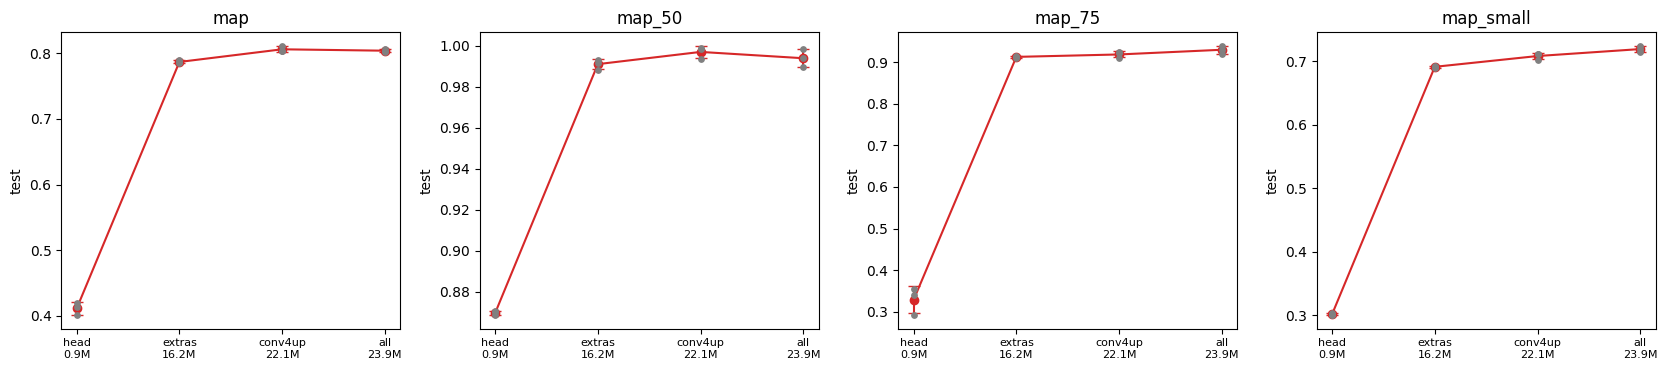

,step,metric,delta_mean,2 x sd,exceeds_noise
0,head → extras,map_75,0.5839,0.0658,True
1,head → extras,map_small,0.3899,0.0034,True
2,head → extras,map,0.3755,0.0184,True
3,extras → conv4up,map_75,0.0058,0.0144,False
4,extras → conv4up,map_small,0.0170,0.0095,True
5,extras → conv4up,map,0.0193,0.0092,True
6,conv4up → all,map_75,0.0113,0.0189,False
7,conv4up → all,map_small,0.0110,0.0103,True
8,conv4up → all,map,-0.0021,0.0092,False


In [41]:
def hv_scope_jumps(stats: pd.DataFrame, scopes: list[str], metrics: list[str]) -> pd.DataFrame:
    """연속한 scope 사이의 평균 차이와 noise 기준(2 × 두 scope의 sd 중 큰 값)."""
    rows = []
    for lower, upper in zip(scopes, scopes[1:]):
        for metric in metrics:
            delta = stats.loc[upper, (metric, "mean")] - stats.loc[lower, (metric, "mean")]
            noise = 2 * np.nanmax([stats.loc[lower, (metric, "std")], stats.loc[upper, (metric, "std")], np.nan])
            rows.append({"step": f"{lower} → {upper}", "metric": metric, "delta_mean": delta,
                         "2 x sd": noise, "exceeds_noise": bool(delta > noise) if not math.isnan(noise) else None})
    return pd.DataFrame(rows)


def hv_plot_scope_ladder(summary: pd.DataFrame, stats: pd.DataFrame, scopes: list[str],
                         trainable_by_scope: dict[str, int], metrics: list[str]) -> None:
    """scope별 지표: 점 = seed별 run, 선과 오차막대 = 평균 ± sd."""
    x = np.arange(len(scopes))
    fig, axes = plt.subplots(1, len(metrics), figsize=(4.2 * len(metrics), 3.8), squeeze=False)
    for ax, metric in zip(axes[0], metrics):
        for position, scope in enumerate(scopes):
            values = summary.loc[summary["scope"] == scope, metric]
            ax.scatter(np.full(len(values), position), values, color="gray", s=15, zorder=3)
        ax.errorbar(x, stats.loc[scopes, (metric, "mean")], yerr=stats.loc[scopes, (metric, "std")].fillna(0),
                    marker="o", capsize=4, color="tab:red")
        ax.set_xticks(x, [f"{scope}\n{trainable_by_scope[scope] / 1e6:.1f}M" for scope in scopes], fontsize=8)
        ax.set(title=metric, ylabel="test")
    plt.tight_layout()
    plt.show()


# ---- 실행 ----
if HV_RUN["B2"]:
    hv_train_runs(HV_PLANNED["B2"], DATASETS, RECORDS, DEVICE)

hv_b2_runs = hv_b1_runs + HV_PLANNED["B2"]  # head·all(I-8) + extras·conv4up
hv_b2 = hv_collect(hv_b2_runs, HV_RESULTS, DATASETS["test"], DEVICE, HV_SCALE_BINS)
hv_b2_summary = hv_summary_table(hv_b2_runs, hv_b2, HV_TRAINABLE)
hv_b2_scopes = [scope for scope in HV_SCOPES if scope in set(hv_b2_summary["scope"])]
hv_b2_stats = hv_seed_stats(hv_b2_summary, ["scope"], HV_METRICS).reindex(hv_b2_scopes)
display(hv_b2_summary.set_index("run").reindex(columns=["scope", "seed", "trainable_params", *HV_METRICS]).round(3))
display(hv_b2_stats.round(4))
if len(hv_b2_scopes) >= 2:
    hv_plot_scope_ladder(hv_b2_summary, hv_b2_stats, hv_b2_scopes, HV_TRAINABLE, ["map", "map_50", "map_75", "map_small"])
    display(hv_scope_jumps(hv_b2_stats, hv_b2_scopes, ["map_75", "map_small", "map"]).round(4))

**관찰** (scope마다 seed 3개, 평균 ± sd. `head`와 `all`은 I-8의 run을 그대로 쓴다)

| scope | 학습 파라미터 | mAP | mAP@0.5 | mAP@0.75 | mean IoU | small mAP | cat → dog | dog → cat |
|---|---|---|---|---|---|---|---|---|
| `head` | 0.94 M | 0.411 ± 0.009 | 0.870 | 0.329 ± 0.033 | 0.687 | 0.301 ± 0.002 | 6.3 | 4.0 |
| `extras` | 16.2 M | 0.787 ± 0.002 | 0.991 | 0.913 ± 0.002 | 0.880 | 0.691 ± 0.002 | 2.3 | 4.3 |
| `conv4up` | 22.1 M | 0.806 ± 0.005 | 0.997 | 0.918 ± 0.007 | 0.890 | 0.708 ± 0.005 | 0.3 | 4.0 |
| `all` | 23.9 M | 0.804 ± 0.002 | 0.994 | 0.930 ± 0.009 | 0.888 | 0.719 ± 0.005 | 1.0 | 2.0 |

단계별 평균 차이. 괄호 안은 판정 기준(두 단계 sd 중 큰 값 × 2)이고, 굵은 글씨는 기준을 넘은 값이다.

| 단계 | mAP | mAP@0.75 | small mAP |
|---|---|---|---|
| `head` → `extras` | **+0.376** (0.018) | **+0.584** (0.066) | **+0.390** (0.003) |
| `extras` → `conv4up` | **+0.019** (0.009) | +0.006 (0.014) | **+0.017** (0.010) |
| `conv4up` → `all` | −0.002 (0.009) | +0.011 (0.019) | **+0.011** (0.010) |

- `head` → `all`의 mAP@0.75 상승(+0.601) 중 97%가 `head` → `extras` 단계에서 나온다.
- `conv4up`과 `all`의 mAP는 같다. conv1 ~ conv3까지 더 풀어도 mAP는 오르지 않는다.
- `extras` → `conv4up`에서 small mAP는 +0.017 올라 기준을 넘는다. 하지만 같은 단계에서 전체 mAP도 +0.019 올랐다. `head` → `extras`에서도 small(+0.390)과 전체(+0.376)가 비슷하게 오른다.
- cat → dog 오류는 scope가 넓어질수록 줄어든다(6.3 → 2.3 → 0.3 → 1.0).
  - FE 3 seed에서 모두 틀린 Sphynx·Persian 4장 가운데 `extras` 이상에서도 남은 것은 Persian_194 하나다(`extras` seed 2/3).
  - `extras`에서는 다른 cat 오류가 새로 생겼다. British_Shorthair_187은 3/3 seed, Bombay_135는 2/3 seed에서 틀렸다.
- dog → cat 오류는 `all`을 빼면 약 4장으로 비슷하다.

**판정**
- **H1**: mAP@0.75 상승이 `head` → `extras` 한 단계에 몰려 있다. 사전 기준에 따라 **지지**한다. FE의 경계 정밀도가 낮은 것은 backbone 상위 층(conv5, fc6·fc7, extra layers)을 동결한 것과 관련이 있다.
  - 사전에 적어 둔 한계: 이 단계에서 학습 파라미터도 0.94 M에서 16.2 M로 17배 늘어난다. 그래서 원인이 "feature 내용"인지 "학습 용량"인지 이 실험으로는 나눌 수 없다.
- **H6의 FE feature 요인**(38×38 map을 만드는 conv4): `extras` → `conv4up`에서 small mAP가 오른 폭이 전체 mAP가 오른 폭과 같다. small에만 나타나는 효과가 없다.
  - 사전 기준은 "small이 크게 오르면 지지"만 정해 두었다.
  - 상승폭이 전체와 같아 이 기준을 충족하지 못한다. seed sd가 작으므로 효과를 놓쳤을 가능성도 낮다.
  - 그래서 "small 고유의 feature 요인"은 **기각**한다.

**가설** (검증 안 됨)
- conv5 ~ extra layers는 COCO의 몸 전체 박스로 학습되어 머리보다 넓은 영역의 정보를 담고 있을 수 있다. 그렇다면 이 층을 풀어야 머리 경계가 맞춰진다. 위 결과는 이 설명과 맞는다. 하지만 위의 용량 문제가 있어 이 설명은 검증되지 않았다. head를 `extras`와 같은 파라미터 수로 키운 run이 있으면 둘을 구분할 수 있다.
- scope가 넓어질수록 cat → dog 오류가 크게 줄어드는 것은 SPECIES 오류도 feature 쪽에 원인이 있다는 설명과 맞는다. I-12와 함께 본다.

### I-10. 학습량과 plateau (H1', H3, 학습 실험 `B3B5`)
I-9와 반대 방향의 설명을 확인한다.

| 가설 | 내용 | run |
|---|---|---|
| H1' | FE가 낮은 것은 feature 탓이 아니라 학습량 부족 탓이다 | FE를 LR 5배(1e-2)로 학습 |
| H3 | 막판 plateau는 cosine LR이 0에 가까워졌기 때문이다 | FE·FT를 60 epoch cosine으로, early stopping 없이 학습 |

60 epoch run의 30 epoch 지점에서는 LR이 아직 최대치의 약 절반이다. 그래서 같은 epoch에서 30 epoch run(이때 LR ≈ 0)과 비교할 수 있다.

**판정 기준**
- **H1'**: FE lr 1e-2 또는 FE 60 epoch의 test mAP@0.75가 FE 기준(0.29)에서 FT 쪽(≥ 0.6)으로 크게 오르면 H1'을 지지하고 H1은 약해진다. +2 sd 안쪽에 머물면 H1'을 기각한다. sd는 I-8의 seed sd다.
- **H3**: 60 epoch run의 최종 test mAP가 30 epoch run보다 2 sd 넘게 높으면 "30 epoch이 부족했다"(LR → 0 때문에 멈춤)고 본다. 차이가 sd 안쪽이면 "수렴했다"고 본다.

=== [1/3] scope-head_lr-1e-2_ep-30_pat-7_sampler-random_seed-42
체크포인트에서 재개: epoch 30 (/content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/outputs)
이미 끝난 run이다. 저장된 기록을 돌려준다.
=== [2/3] scope-head_lr-2e-3_ep-60_pat-off_sampler-random_seed-42
체크포인트에서 재개: epoch 60 (/content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/outputs)
이미 끝난 run이다. 저장된 기록을 돌려준다.
=== [3/3] scope-all_lr-2e-3_ep-60_pat-off_sampler-random_seed-42
체크포인트에서 재개: epoch 21 (/content/drive/MyDrive/CodeIT/Colab/mission7_FaceObjectDetection/outputs)


train:   0%|          | 0/161 [00:00<?, ?it/s]

predict:   0%|          | 0/18 [00:00<?, ?it/s]

[epoch 22] loss 0.588 (cls 0.496, reg 0.092) | val mAP 0.7604, mAP@0.5 0.9809, IoU 0.872 | 61s


train:   0%|          | 0/161 [00:00<?, ?it/s]

...

[epoch 60] loss 0.335 (cls 0.301, reg 0.033) | val mAP 0.8093, mAP@0.5 0.9830, IoU 0.895 | 55s


predict:   0%|          | 0/18 [00:00<?, ?it/s]

predict:   0%|          | 0/18 [00:00<?, ?it/s]

predict:   0%|          | 0/18 [00:00<?, ?it/s]

,scope,lr,max_epochs,patience,map,map_75,map_small,val_map_at_ep30,epochs_run,best_epoch
run,,,,,,,,,,
scope-head_lr-2e-3_ep-30_pat-7_sampler-random_seed-42,head,0.002,30,7,0.4011,0.2917,0.3002,0.4151,30,24
scope-all_lr-2e-3_ep-30_pat-7_sampler-random_seed-42,all,0.002,30,7,0.8034,0.9296,0.7196,0.7979,30,29
scope-head_lr-1e-2_ep-30_pat-7_sampler-random_seed-42,head,0.010,30,7,0.4439,0.3893,0.2976,0.4371,30,28
scope-head_lr-2e-3_ep-60_pat-off_sampler-random_seed-42,head,0.002,60,60,0.4454,0.3742,0.3273,0.3295,60,54
scope-all_lr-2e-3_ep-60_pat-off_sampler-random_seed-42,all,0.002,60,60,0.8160,0.9261,0.7334,0.7497,60,54


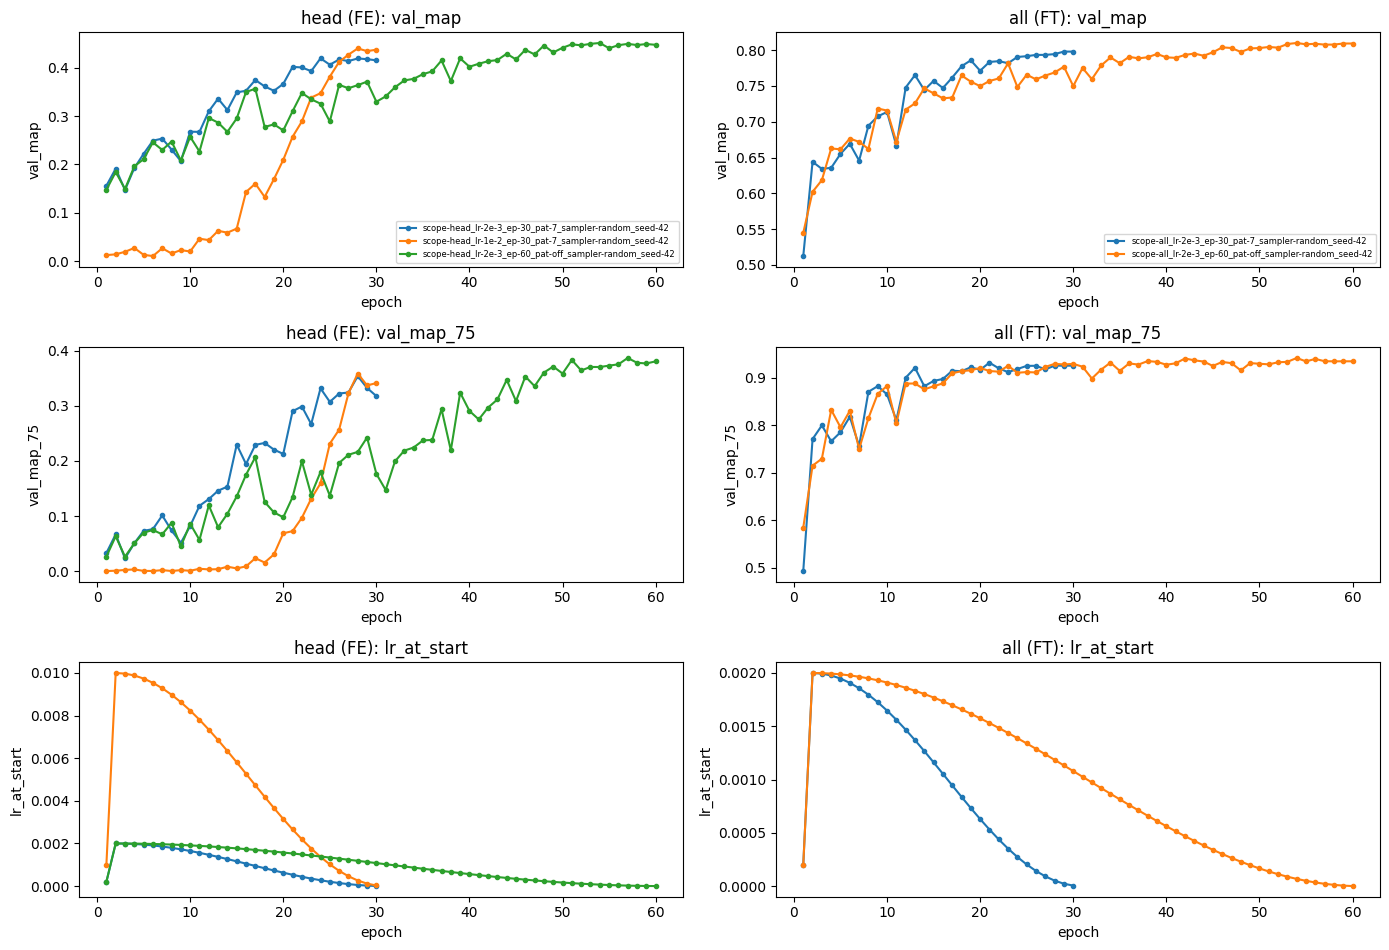

,run,vs,metric,delta,seed_sd,delta / sd
0,scope-head_lr-1e-2_ep-30_pat-7_sampler-random_...,scope-head_lr-2e-3_ep-30_pat-7_sampler-random_...,map,0.0427,0.0092,4.6399
1,scope-head_lr-1e-2_ep-30_pat-7_sampler-random_...,scope-head_lr-2e-3_ep-30_pat-7_sampler-random_...,map_75,0.0976,0.0329,2.9671
2,scope-head_lr-2e-3_ep-60_pat-off_sampler-rando...,scope-head_lr-2e-3_ep-30_pat-7_sampler-random_...,map,0.0442,0.0092,4.8040
3,scope-head_lr-2e-3_ep-60_pat-off_sampler-rando...,scope-head_lr-2e-3_ep-30_pat-7_sampler-random_...,map_75,0.0825,0.0329,2.5085
4,scope-all_lr-2e-3_ep-60_pat-off_sampler-random...,scope-all_lr-2e-3_ep-30_pat-7_sampler-random_s...,map,0.0126,0.0023,5.5748
5,scope-all_lr-2e-3_ep-60_pat-off_sampler-random...,scope-all_lr-2e-3_ep-30_pat-7_sampler-random_s...,map_75,-0.0035,0.0094,-0.3689


In [42]:
def hv_value_at_epoch(history: Optional[list[dict]], column: str, epoch: int) -> float:
    """history에서 특정 epoch의 값. 없으면 NaN."""
    if history is None:
        return np.nan
    frame = pd.DataFrame(history).set_index("epoch")
    return float(frame.loc[epoch, column]) if epoch in frame.index else np.nan


def hv_compare_to_reference(summary: pd.DataFrame, reference_run: str, seed_stats: pd.DataFrame,
                            metrics: list[str]) -> pd.DataFrame:
    """reference run 대비 차이와, 그 차이가 seed sd의 몇 배인지 (scope별 sd 사용)."""
    reference = summary.set_index("run").loc[reference_run]
    rows = []
    for row in summary.itertuples(index=False):
        if row.run == reference_run or row.scope != reference["scope"]:
            continue
        for metric in metrics:
            delta = getattr(row, metric) - reference[metric]
            sd = seed_stats.loc[row.scope, (metric, "std")] if row.scope in seed_stats.index else np.nan
            rows.append({"run": row.run, "vs": reference_run, "metric": metric, "delta": delta,
                         "seed_sd": sd, "delta / sd": delta / sd if sd and not math.isnan(sd) else np.nan})
    return pd.DataFrame(rows)


# ---- 실행 ----
if HV_RUN["B3B5"]:
    hv_train_runs(HV_PLANNED["B3B5"], DATASETS, RECORDS, DEVICE)

hv_b3_runs = [HV_FE, HV_FT] + HV_PLANNED["B3B5"]
hv_b3 = hv_collect(hv_b3_runs, HV_RESULTS, DATASETS["test"], DEVICE, HV_SCALE_BINS)
hv_b3_summary = hv_summary_table(hv_b3_runs, hv_b3, HV_TRAINABLE)
hv_b3_summary["val_map_at_ep30"] = [hv_value_at_epoch(hv_b3[name]["history"], "val_map", 30)
                                    for name in hv_b3_summary["run"]]
display(hv_b3_summary.set_index("run").reindex(columns=["scope", "lr", "max_epochs", "patience", "map", "map_75",
                                                        "map_small", "val_map_at_ep30", "epochs_run",
                                                        "best_epoch"]).round(4))
hv_plot_val_curves({"head (FE)": [run for run in hv_b3_runs if run.config.model.trainable_scope == "head"],
                    "all (FT)": [run for run in hv_b3_runs if run.config.model.trainable_scope == "all"]},
                   hv_b3, ["val_map", "val_map_75", "lr_at_start"])
display(pd.concat([hv_compare_to_reference(hv_b3_summary, reference.name, HV_SEED_STATS, ["map", "map_75"])
                   for reference in (HV_FE, HV_FT) if reference.name in hv_b3], ignore_index=True).round(4))

**관찰**

| run | test mAP | test mAP@0.75 | small mAP | 30 epoch 시점 val mAP | best epoch |
|---|---|---|---|---|---|
| FE (lr 2e-3, 30 ep, seed 42) | 0.401 | 0.292 | 0.300 | 0.415 | 24 |
| FE lr 1e-2 (30 ep) | 0.444 | 0.389 | 0.298 | 0.437 | 28 |
| FE 60 ep (patience off) | 0.445 | 0.374 | 0.327 | 0.330 | 54 |
| FT (lr 2e-3, 30 ep, seed 42) | 0.803 | 0.930 | 0.720 | 0.798 | 29 |
| FT 60 ep (patience off) | 0.816 | 0.926 | 0.733 | 0.750 | 54 |

기준 run과의 차이 (sd = I-8의 seed sd)

| 비교 | 지표 | vs seed 42 | ÷ sd | vs seed 평균 | ÷ sd |
|---|---|---|---|---|---|
| FE lr 1e-2 | mAP | +0.043 | 4.6 | +0.033 | 3.5 |
| FE lr 1e-2 | mAP@0.75 | +0.098 | 3.0 | +0.061 | 1.8 |
| FE 60 ep | mAP | +0.044 | 4.8 | +0.034 | 3.7 |
| FE 60 ep | mAP@0.75 | +0.083 | 2.5 | +0.046 | 1.4 |
| FT 60 ep | mAP | +0.013 | 5.6 | +0.012 | 5.3 |
| FT 60 ep | mAP@0.75 | −0.004 | −0.4 | −0.004 | −0.4 |

- **FE lr 1e-2 run은 학습 초반에 발산했다.**
  - 1 ~ 15 epoch 동안 train loss는 7.7 ~ 20.0이었다. 같은 구간에서 기존 FE는 3.1 ~ 6.2였다.
  - val mAP는 이 구간 내내 0.07 이하였다.
  - LR이 5e-3 근처까지 내려간 16 epoch부터 val mAP가 오르기 시작했고, 28 epoch에 best(0.440)가 됐다.
  - 마지막 loss는 2.64로 기존 FE(2.62)와 같다.
- FE의 mAP@0.75 개선폭을 seed 평균 기준으로 보면 FE–FT 차이(+0.601)의 8 ~ 10%다. 0.6에는 크게 못 미친다.
- 60 epoch run의 30 epoch 시점 val mAP는 30 epoch run보다 낮다(FE 0.330 vs 0.415, FT 0.750 vs 0.798). 이 시점의 LR은 1.1e-3으로 최대치의 54%다.
- 60 epoch run의 val mAP는 LR이 줄어드는 31 ~ 54 epoch에 오른다. LR이 7e-5 아래로 내려간 54 ~ 60 epoch에는 평평하다(FE 0.451 → 0.447, FT 0.810 → 0.809).
- FT 60 epoch run의 train loss가 43 epoch에 0.327에서 0.385로 뛰었다. val mAP는 떨어지지 않았다. 이 구간은 한 세션에서 끊김 없이 학습했으므로 재개 때문은 아니다. 원인은 확인하지 않았다.

**판정**
- **H1'**: 사전 기준은 "0.6 이상이면 지지, +2 sd 안이면 기각"이었다. 결과는 그 중간이다.
  - seed 42와 비교하면 +2 sd를 넘는다(2.5 ~ 3.0 sd).
  - seed 평균과 비교하면 +2 sd 안이다(1.4 ~ 1.8 sd).
  - 어느 기준으로 봐도 FT 쪽으로는 거의 다가가지 않았다.
  - 따라서 "FE가 낮은 **주된** 원인은 학습량 부족"이라는 H1'은 **기각**한다. 학습량(LR·epoch)의 기여는 작다. mAP는 +0.03 ~ +0.04 올랐고, 이 값은 두 기준 모두에서 2 sd를 넘는다.
- 이 결과는 H1(I-9)을 강화한다. head만 학습할 때는 LR이나 epoch을 바꿔도 mAP@0.75가 0.39를 넘지 못했다. `extras`를 풀면 0.91이 된다.
- **H3**: 60 epoch run의 test mAP가 30 epoch run보다 높다. FE는 +3.7 ~ 4.8 sd, FT는 +5.3 ~ 5.6 sd다. 사전 기준에 따라 "30 epoch이 부족했다"를 **지지**한다. val 곡선도 LR이 0에 가까워지는 시점에 다시 평평해진다.
- 주의할 점
  - FT의 개선은 mAP +0.012(1.5%)로 작고, mAP@0.75는 변하지 않았다. FT의 sd(0.002)는 run 3개로 잰 값이다. 실제보다 작게 잡혔다면 sd 배수가 부풀려졌을 수 있다.
  - 60 epoch run은 step 수가 2배이고, LR이 줄어드는 속도도 더 느리다. 그래서 "총 학습량" 효과와 "LR → 0" 효과를 나눌 수 없다. H3는 "더 긴 schedule이 도움이 된다"까지만 지지된다.
  - 60 epoch run은 seed가 1개뿐이다.
  - lr 1e-2 run은 발산했다가 회복했다. 따라서 이 run은 계획한 "LR 5배로 더 많이 학습"하는 실험이 되지 못했다. 이 run이 실제로 보여 준 것은 "LR이 줄어든 뒤 약 13 epoch 학습만으로 기존 FE보다 높은 mAP에 도달했다"는 것이다.

**가설** (검증 안 됨): lr 1e-2 run이 짧은 회복 구간만으로 기존 FE를 넘어섰다. head만 학습할 때는 학습 후반의 LR이 높게 유지된 것이 도움이 됐을 수 있다. 16 ~ 28 epoch의 LR은 lr 1e-2 run에서 5e-3 → 3e-4, 기존 run에서 1e-3 → 5e-5였다. 이 실험은 이 효과를 따로 떼어 보지 않았다.

### I-11. LR과 초반 출렁임 (H2, 학습 실험 `B4`)
**가설**: FE 초반에 val mAP가 출렁인 것(3, 8~9, 14 epoch의 하락)은 LR 2e-3이 head만 학습하기에 크기 때문이다. 다른 설명은 val 551장의 측정 noise다.

**방법**
- FE를 LR {5e-4, 1e-3}로 학습해 기존 2e-3과 비교한다.
- **출렁임 지표**: 1 ~ 20 epoch에서 val mAP가 직전 epoch보다 떨어진 폭의 합. 오르기만 하면 0이다.
- 같은 LR(2e-3)에서 seed만 다른 run(I-8)의 출렁임 지표와도 비교한다. 이것이 측정 noise와 seed noise의 기준이 된다.

**판정 기준**
- 출렁임 지표가 LR이 클수록 커지고, LR 2e-3의 seed 3개 범위보다 5e-4 쪽이 확실히 작으면 지지한다.
- seed 간 차이가 LR 간 차이만큼 크면 "측정 noise와 구분 불가"로 둔다.

=== [1/2] scope-head_lr-5e-4_ep-30_pat-7_sampler-random_seed-42


train:   0%|          | 0/161 [00:00<?, ?it/s]

/tmp/ipykernel_1269/4054233545.py:23: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


predict:   0%|          | 0/18 [00:00<?, ?it/s]

[epoch 01] loss 7.092 (cls 5.626, reg 1.466) | val mAP 0.1168, mAP@0.5 0.3736, IoU 0.486 | 53s *best


...

predict:   0%|          | 0/18 [00:00<?, ?it/s]

[epoch 28] loss 2.751 (cls 1.873, reg 0.878) | val mAP 0.3755, mAP@0.5 0.8364, IoU 0.679 | 44s
early stopping: 7 epoch 동안 val mAP 개선 없음


predict:   0%|          | 0/18 [00:00<?, ?it/s]

predict:   0%|          | 0/18 [00:00<?, ?it/s]

,lr,seed,oscillation_1_20,map,map_75,best_epoch
run,,,,,,
scope-head_lr-2e-3_ep-30_pat-7_sampler-random_seed-42,0.0020,42,0.1368,0.4011,0.2917,24
scope-head_lr-2e-3_ep-30_pat-7_sampler-random_seed-1,0.0020,1,0.2364,0.4139,0.3398,28
scope-head_lr-2e-3_ep-30_pat-7_sampler-random_seed-2,0.0020,2,0.1218,0.4190,0.3546,29
scope-head_lr-5e-4_ep-30_pat-7_sampler-random_seed-42,0.0005,42,0.0867,0.3341,0.2242,13
scope-head_lr-1e-3_ep-30_pat-7_sampler-random_seed-42,0.0010,42,0.0426,0.3809,0.2555,21


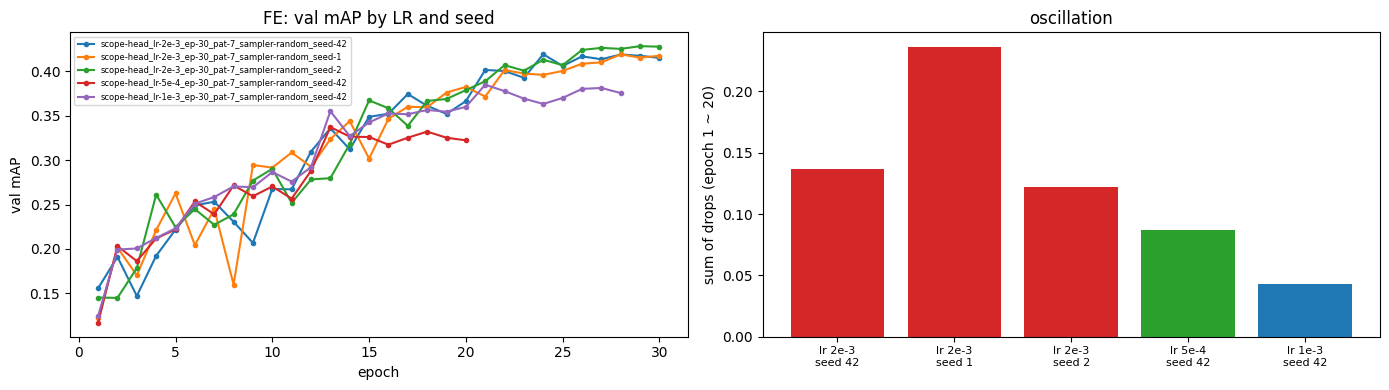

In [43]:
def hv_oscillation(history: Optional[list[dict]], column: str, last_epoch: int) -> float:
    """1 ~ last_epoch에서 epoch 간 하락 폭의 합 (오르기만 하면 0)."""
    if history is None:
        return np.nan
    values = pd.DataFrame(history).set_index("epoch")[column].loc[:last_epoch]
    return float((-values.diff()).clip(lower=0).sum())


def hv_plot_lr_oscillation(runs: list[HVRun], results_by_name: dict[str, dict], summary: pd.DataFrame) -> None:
    """왼쪽: run별 val mAP 곡선. 오른쪽: run별 출렁임 지표 (색 = LR)."""
    fig, (ax_curve, ax_bar) = plt.subplots(1, 2, figsize=(14, 4))
    for run in runs:
        history = results_by_name.get(run.name, {}).get("history")
        if history is not None:
            frame = pd.DataFrame(history)
            ax_curve.plot(frame["epoch"], frame["val_map"], marker=".", label=run.name)
    ax_curve.set(xlabel="epoch", ylabel="val mAP", title="FE: val mAP by LR and seed")
    ax_curve.legend(fontsize=6)
    palette = ("tab:green", "tab:blue", "tab:red", "tab:purple")
    lr_colors = {lr: color for lr, color in zip(sorted(summary["lr"].unique()), palette)}
    ax_bar.bar(range(len(summary)), summary["oscillation_1_20"], color=[lr_colors[lr] for lr in summary["lr"]])
    ax_bar.set_xticks(range(len(summary)), [f"lr {hv_format_lr(lr)}\nseed {seed}"
                                            for lr, seed in zip(summary["lr"], summary["seed"])], fontsize=8)
    ax_bar.set(ylabel="sum of drops (epoch 1 ~ 20)", title="oscillation")
    plt.tight_layout()
    plt.show()


# ---- 실행 ----
if HV_RUN["B4"]:
    hv_train_runs(HV_PLANNED["B4"], DATASETS, RECORDS, DEVICE)

hv_b4_runs = [run for run in hv_b1_runs if run.config.model.trainable_scope == "head"] + HV_PLANNED["B4"]
hv_b4 = hv_collect(hv_b4_runs, HV_RESULTS, DATASETS["test"], DEVICE, HV_SCALE_BINS)
hv_b4_summary = hv_summary_table(hv_b4_runs, hv_b4, HV_TRAINABLE)
hv_b4_summary["oscillation_1_20"] = [hv_oscillation(hv_b4[name]["history"], "val_map", 20) for name in hv_b4_summary["run"]]
display(hv_b4_summary.set_index("run").reindex(columns=["lr", "seed", "oscillation_1_20", "map", "map_75",
                                                        "best_epoch"]).round(4))

hv_plot_lr_oscillation(hv_b4_runs, hv_b4, hv_b4_summary)

**관찰** (출렁임 지표 = 1 ~ 20 epoch에서 val mAP 하락폭의 합)

| run | LR | 출렁임 지표 | test mAP | test mAP@0.75 | 멈춘 epoch (best) |
|---|---|---|---|---|---|
| FE seed 42 | 2e-3 | 0.137 | 0.401 | 0.292 | 30 (24) |
| FE seed 1 | 2e-3 | 0.236 | 0.414 | 0.340 | 30 (28) |
| FE seed 2 | 2e-3 | 0.122 | 0.419 | 0.355 | 30 (29) |
| FE lr 1e-3 | 1e-3 | 0.043 | 0.381 | 0.256 | 28 (21), early stopping |
| FE lr 5e-4 | 5e-4 | 0.087 | 0.334 | 0.224 | 20 (13), early stopping |
| (참고) FE lr 1e-2 | 1e-2 | 0.065 | 0.444 | 0.389 | 30 (28) |

- LR 2e-3에서 seed 3개의 출렁임 지표는 0.122 ~ 0.236이다. 범위의 폭은 0.114다.
- LR 1e-3과 5e-4는 둘 다 이 범위보다 아래다. 하지만 5e-4(0.087)가 1e-3(0.043)보다 크다. LR 순서와 맞지 않는다.
- LR 2e-3 seed 평균(0.165)과의 차이는 1e-3이 0.122, 5e-4가 0.078이다. 둘 다 seed 범위의 폭(0.114)과 비슷한 크기다.
- lr 1e-2 run은 1 ~ 20 epoch 대부분에서 val mAP가 0.2 아래였다(I-10). 값 자체가 작아서 다른 run과 출렁임 지표를 비교할 수 없다.
- 다른 설정에서도 출렁임 지표가 비슷한 범위에 있다.

| 설정 | 출렁임 지표 범위 |
|---|---|
| FT seed 3개 | 0.030 ~ 0.173 |
| `extras` | 0.092 ~ 0.143 |
| `conv4up` | 0.058 ~ 0.094 |
| balanced | 0.084 ~ 0.107 |

- LR을 낮춘 두 run은 모두 early stopping으로 멈췄다. test mAP도 seed 평균(0.411)보다 낮다. 5e-4는 −0.077, 1e-3은 −0.030이다.

**판정**
- 사전 기준의 첫 조건("LR이 클수록 출렁임이 커진다")이 성립하지 않는다. 5e-4의 값이 1e-3보다 크다.
- seed 간 차이도 LR 간 차이만큼 크다.
- 사전 기준에 따라 H2는 **판정 불가(측정 noise와 구분 불가)**로 둔다.
- LR을 낮추면 출렁임이 seed 범위 아래로 내려가는 경향은 있다. 하지만 LR마다 run이 1개뿐이라 이 경향이 실제인지 확인할 수 없다.

**가설** (검증 안 됨)
- 출렁임은 FT, `extras`, `conv4up`처럼 다른 설정에서도 비슷한 크기로 나타난다. 이는 출렁임의 상당 부분이 LR 때문이 아니라 val 551장의 측정 noise 때문이라는 설명과 맞는다.
- LR을 낮춘 run이 일찍 멈춘 이유는 patience 7 epoch 안의 개선폭이 val noise보다 작았기 때문일 수 있다. 그렇다면 이 run들의 test mAP가 낮은 것은 LR 자체보다 early stopping 때문일 수 있다.

### I-12. SPECIES 균형 sampling (H4, 학습 실험 `B6`)
**가설**: cat → dog 오류는 학습 데이터 불균형(Cat : Dog = 1 : 2.1) 때문이다. 그렇다면 학습할 때 cat과 dog를 같은 빈도로 보여 주면 cat → dog 오류가 줄어야 한다.

**방법**
- FE 설정에서 train DataLoader의 shuffle만 `WeightedRandomSampler`로 바꾼다.
  - weight = SPECIES 빈도의 역수
  - 복원 추출
  - epoch당 뽑는 수 = train 이미지 수
- seed는 {42, 1} 2개로 학습한다.
- 비교 대상은 같은 FE 설정의 random sampling run이다(기존 FE + I-8 seed).

**판정 기준**
- seed 2개 모두에서 cat → dog 오류가 random run들의 범위(최소 ~ 최대)보다 작아야 한다.
- 그 차이가 I-1의 cat 오류율 CI를 벗어나야 한다.
- 두 조건이 모두 성립하면 지지한다.
- 박스 지표(mAP)도 함께 본다. 오류가 줄어도 박스가 나빠졌다면 trade-off로 기록한다.

=== [1/2] scope-head_lr-2e-3_ep-30_pat-7_sampler-balanced_seed-42


train:   0%|          | 0/161 [00:00<?, ?it/s]

/tmp/ipykernel_1269/4054233545.py:23: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


predict:   0%|          | 0/18 [00:00<?, ?it/s]

[epoch 01] loss 6.140 (cls 4.628, reg 1.512) | val mAP 0.1266, mAP@0.5 0.4015, IoU 0.475 | 43s *best


...

predict:   0%|          | 0/18 [00:00<?, ?it/s]

[epoch 30] loss 2.582 (cls 1.780, reg 0.802) | val mAP 0.4196, mAP@0.5 0.8838, IoU 0.698 | 44s


predict:   0%|          | 0/18 [00:00<?, ?it/s]

predict:   0%|          | 0/18 [00:00<?, ?it/s]

,sampler,seed,cat_as_dog,dog_as_cat,ap_cat,ap_dog,map,map_75
run,,,,,,,,
scope-head_lr-2e-3_ep-30_pat-7_sampler-random_seed-42,random,42,7,4,0.4215,0.3808,0.4011,0.2917
scope-head_lr-2e-3_ep-30_pat-7_sampler-random_seed-1,random,1,8,4,0.4354,0.3925,0.4139,0.3398
scope-head_lr-2e-3_ep-30_pat-7_sampler-random_seed-2,random,2,4,4,0.4452,0.3928,0.4190,0.3546
scope-head_lr-2e-3_ep-30_pat-7_sampler-balanced_seed-42,balanced,42,4,6,0.4571,0.3803,0.4187,0.3379
scope-head_lr-2e-3_ep-30_pat-7_sampler-balanced_seed-1,balanced,1,3,5,0.4612,0.3799,0.4206,0.3444


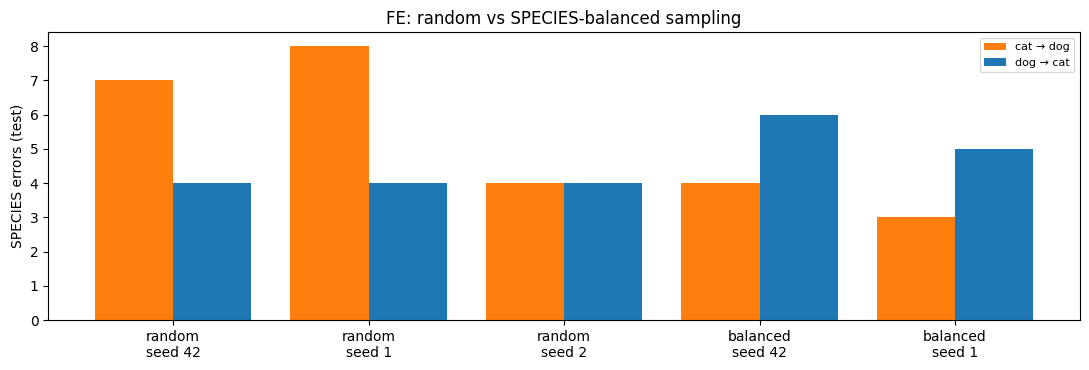

참고 (I-1): FE cat 오류율 95% CI = [0.011, 0.068] → cat 176장 기준 오류 수 [2.0, 12.0]


In [44]:
def hv_plot_species_errors(summary: pd.DataFrame) -> None:
    """run별 방향별 SPECIES 오류 수 막대."""
    fig, ax = plt.subplots(figsize=(1.6 * max(1, len(summary)) + 3, 3.8))
    x = np.arange(len(summary))
    ax.bar(x - 0.2, summary["cat_as_dog"], width=0.4, color="tab:orange", label="cat → dog")
    ax.bar(x + 0.2, summary["dog_as_cat"], width=0.4, color="tab:blue", label="dog → cat")
    ax.set_xticks(x, [f"{sampler}\nseed {seed}" for sampler, seed in zip(summary["sampler"], summary["seed"])])
    ax.set(ylabel="SPECIES errors (test)", title="FE: random vs SPECIES-balanced sampling")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


# ---- 실행 ----
if HV_RUN["B6"]:
    hv_train_runs(HV_PLANNED["B6"], DATASETS, RECORDS, DEVICE)

hv_b6_runs = [run for run in hv_b1_runs if run.config.model.trainable_scope == "head"] + HV_PLANNED["B6"]
hv_b6 = hv_collect(hv_b6_runs, HV_RESULTS, DATASETS["test"], DEVICE, HV_SCALE_BINS)
hv_b6_summary = hv_summary_table(hv_b6_runs, hv_b6, HV_TRAINABLE)
display(hv_b6_summary.set_index("run").reindex(columns=["sampler", "seed", "cat_as_dog", "dog_as_cat", "ap_cat",
                                                        "ap_dog", "map", "map_75"]).round(4))

hv_plot_species_errors(hv_b6_summary)

hv_cat_ci = HV_A1[(HV_A1["run"] == "FE") & (HV_A1["group"] == "cat") & (HV_A1["metric"] == "species_error_rate")]
if len(hv_cat_ci):
    hv_num_cat = int((HV_RESULTS[HV_FE.name]["per_image"]["species"] == "cat").sum())
    print(f"참고 (I-1): FE cat 오류율 95% CI = [{hv_cat_ci['ci_low'].iloc[0]:.3f}, {hv_cat_ci['ci_high'].iloc[0]:.3f}]"
          f" → cat {hv_num_cat}장 기준 오류 수 [{hv_cat_ci['ci_low'].iloc[0] * hv_num_cat:.1f}, "
          f"{hv_cat_ci['ci_high'].iloc[0] * hv_num_cat:.1f}]")

**관찰**

| run | sampler | seed | cat → dog | dog → cat | 합계 | AP cat | AP dog | mAP | mAP@0.75 |
|---|---|---|---|---|---|---|---|---|---|
| FE | random | 42 | 7 | 4 | 11 | 0.422 | 0.381 | 0.401 | 0.292 |
| FE | random | 1 | 8 | 4 | 12 | 0.435 | 0.393 | 0.414 | 0.340 |
| FE | random | 2 | 4 | 4 | 8 | 0.445 | 0.393 | 0.419 | 0.355 |
| FE | balanced | 42 | 4 | 6 | 10 | 0.457 | 0.380 | 0.419 | 0.338 |
| FE | balanced | 1 | 3 | 5 | 8 | 0.461 | 0.380 | 0.421 | 0.344 |

- 오류 수(평균)를 비교하면 다음과 같다.

| 오류 | random (3 seed) | balanced (2 seed) |
|---|---|---|
| cat → dog | 4 ~ 8장 (6.3) | 3 ~ 4장 (3.5) |
| dog → cat | 4장 (3 seed 모두) | 5 ~ 6장 |
| 합계 | 10.3 | 9.0 |

- balanced에서 AP cat은 +0.025(+2.1 sd) 올랐고, AP dog는 −0.009(−1.3 sd) 내렸다. mAP와 mAP@0.75는 seed 범위 안이다.

이미지 단위 비교 (보완 분석: 로컬 `*_test_predictions.pt`로 계산. score 비는 I-6의 FE seed 42 값)

| 이미지 | dog / cat score 비 (FE seed 42) | random에서 틀린 seed 수 | balanced에서 틀린 seed 수 |
|---|---|---|---|
| Sphynx_15, Sphynx_114, Sphynx_192 | 1.29, 1.32, 1.34 | 각 2 / 3 | 각 0 / 2 |
| Persian_112 | 2.21 | 3 / 3 | 2 / 2 |
| Sphynx_148 | 2.61 | 3 / 3 | 1 / 2 |
| Persian_194 | 8.69 | 3 / 3 | 2 / 2 |
| Sphynx_190 | 10.21 | 3 / 3 | 2 / 2 |
| dog → cat: keeshond_16, japanese_chin_119, samoyed_138, yorkshire_terrier_170 | 0.10 ~ 0.33 | 각 3 / 3 | 각 2 / 2 |
| 새로 생긴 dog → cat: pomeranian_171, japanese_chin_129, shiba_inu_120 | – | 각 0 / 3 | 각 1 / 2 |

- balanced에서 사라진 cat → dog 오류는 Sphynx 3장이다. 이 3장은 FE seed 42에서 score 비가 1.4 이하였다(경계 근처). random에서도 seed에 따라 맞힌 적이 있다(각 2 / 3).
- score 비가 2 이상이었던 4장(Persian_112, Sphynx_148, Persian_194, Sphynx_190)은 balanced에서도 대부분 남았다(8번 중 7번).
- 이 4장 중 Persian_194를 뺀 3장은 `extras` 이상 scope의 run 9개(I-9)에서 모두 맞았다.

**판정**
- 첫 조건: balanced seed 42의 cat → dog는 4장으로, random 범위의 최솟값(4장)과 같다. "범위보다 작다"가 성립하지 않는다.
- 둘째 조건: 3 ~ 4장은 I-1의 CI(2 ~ 12장) 안에 있다.
- 사전 기준을 충족하지 않으므로 H4는 **판정 불가**다.
- I-6(prior 보정)과 같은 패턴이 나타난다. cat → dog가 줄어든 만큼 dog → cat이 늘었고, 바로잡힌 것은 경계 근처의 이미지뿐이다.

**가설** (검증 안 됨): FE의 SPECIES 오류는 SPECIES prior보다 다음 두 가지로 더 잘 설명된다.
- 이미지 외형: 털 없는 피부나 납작한 얼굴의 cat, 털이 긴 spitz·toy 계열의 dog
- 동결된 feature

I-6, I-9, I-12를 함께 보면 같은 이미지가 seed, LR, sampler를 바꿔도 반복해서 틀리고, scope를 넓힐 때만 사라진다. 다만 오류가 한 자릿수라 어느 설명도 검정하지 못했다.

### I-13. 종합 판정
판정은 세 가지 중 하나로 적는다.
- **지지**
- **기각**
- **판정 불가**: 차이가 CI나 seed sd 안쪽이거나, 사전 기준이 정하지 않은 결과가 나온 경우

모든 판정은 "이 실험 범위에서" 내린 결론이며, 원인을 확정하지 않는다. 학습 실험(I-8 ~ I-12)은 run 17개를 모두 실행했다.

| ID | 가설 | 근거 셀 | 판정 | 한 줄 근거 |
|---|---|---|---|---|
| H0 | 차이가 표본·seed noise보다 크다 | I-1, I-8 | **지지**: FE vs FT, FT의 cat > dog, small < large / 판정 불가: FE의 cat > dog, SPECIES 오류율 차이 | FE vs FT 차이는 표본 CI 밖에 있고, seed sd의 2배보다도 9배 이상 크다(mAP@0.75 +0.601 vs 2 sd 0.066). FE cat vs dog와 SPECIES 오류율 차이는 표본 CI 안이다 |
| H1 | 동결 COCO feature에 머리 경계 정보가 부족하다 | I-9, I-10 | **지지** (feature 내용과 학습 용량은 분리하지 못함) | `head` → `all` mAP@0.75 상승의 97%가 `head` → `extras` 단계에서 나온다. head만 학습하면 LR·epoch을 바꿔도 0.39를 넘지 못한다 |
| H1' | FE는 학습량이 부족했다 | I-10 | 주된 원인으로는 **기각** | LR 5배나 60 epoch의 mAP@0.75 개선은 FE–FT 차이의 8 ~ 10%다(seed 평균 대비 +1.4 ~ 1.8 sd). mAP는 +0.03 ~ +0.04로 2 sd를 넘는다(작은 기여) |
| H2 | 초반 출렁임은 LR이 커서다 | I-11 | 판정 불가 | 출렁임이 LR 순서와 맞지 않는다(5e-4: 0.087 > 1e-3: 0.043). seed 범위(0.122 ~ 0.236)의 폭이 LR 간 차이만큼 크다 |
| H3 | plateau는 LR → 0 때문이다 | I-10 | **지지** ("더 긴 schedule이 낫다"까지만) | 60 epoch의 test mAP가 FE +0.044, FT +0.013으로 둘 다 2 sd를 넘는다. val 곡선은 LR이 0에 가까워질 때 다시 평평해진다. FT의 mAP@0.75는 변하지 않았다 |
| H4 | cat → dog 오류는 데이터 불균형 때문이다 | I-6, I-12 | 판정 불가 (I-6, I-12 모두 기준 미달) | balanced의 cat → dog 3 ~ 4장은 random 범위(4 ~ 8장) 안이고 CI 안이다. 두 실험 모두 오류를 dog → cat 쪽으로 옮길 뿐이다. score 비가 큰 Sphynx·Persian 오류는 남는다 |
| H5 | dog 경계가 부정확한 것은 BREED 다양성 / GT 변동 때문이다 | I-2 | BREED 다양성: 약한 지지 / GT 변동: 판정 불가 | FT 하위 BREED 10개가 모두 dog다. 전체 ρ = −0.47은 SPECIES 차이로 설명된다. dog 안 ρ = 0.12 [−0.30, 0.53], SPECIES 평균을 뺀 ρ = 0.04 |
| H6 | small head 문제는 해상도 때문이다 (FE는 feature도) | I-3, I-9 | 해상도: **지지** (상관) / FE의 small 고유 feature 요인: **기각** | FT에서도 ρ = 0.29 [0.21, 0.37]이다. conv4를 풀 때 small mAP 상승(+0.017)이 전체 mAP 상승(+0.019)과 같아, small에만 나타나는 효과가 없다 |
| H7 | score로 실패를 가려낼 수 있다 | I-4 | 판정 불가 (경계) | FE AUROC는 0.785 [0.734, 0.833]이고 기준 0.8이 CI 안에 있다. 실패의 57%는 score ≥ 0.5다. FT는 실패가 3장뿐이다 |
| H8 | FT 오류는 느슨한 박스이고 검은 털에서 커진다 | I-5 | 느슨한 박스: **지지** / 검은 털: **기각** | 하위 10%의 면적 비 중앙값은 1.27배이고, 62.5%가 GT를 감싸는 넓은 박스다(어긋남은 14%). ρ(밝기, 면적 비) = −0.05이고 CI가 0을 포함한다 |
| H9 | 시간 대부분이 FE·FT 공통 단계다 | I-7 | **지지** | FT − FE 차이의 125%가 backward·optimizer에서 나온다. FE epoch의 93%가 공통 단계다 |

#### 종합

**1. 사전 기준을 통과한 결론**

| 질문 | 결론 | 근거 |
|---|---|---|
| FE와 FT의 차이는 실제인가 | 그렇다. test 표본 noise와 seed noise보다 모두 훨씬 크다 | H0 (I-1, I-8) |
| FE의 경계 정밀도(mAP@0.75)는 왜 낮은가 | backbone 상위 층(conv5, fc6·fc7, extra layers)을 동결했기 때문이다. 이 층만 풀어도(`extras`) 차이의 97%가 회복된다. head만 학습할 때 LR이나 epoch을 늘리면 차이의 8 ~ 10%만 줄어든다 | H1 지지, H1' 기각 (I-9, I-10) |
| 30 epoch이면 충분한가 | 아니다. 60 epoch에서 FE와 FT 모두 test mAP가 올랐다. 다만 FT의 개선은 +0.013으로 작고, mAP@0.75는 그대로다 | H3 (I-10) |
| FT에 남은 오차는 어떤 것인가 | 대부분 GT보다 넓은 박스다. small head일수록 IoU가 낮은 경향이 FT에도 있다(상관) | H8, H6 (I-5, I-3) |
| FT는 왜 1.3배만 느린가 | 늘어난 시간은 대부분 backward다. FE epoch의 대부분은 FE와 FT가 공통으로 쓰는 단계(forward, val)다 | H9 (I-7) |

- H1은 동결 범위를 직접 바꾼 개입 실험으로 확인했다. 따라서 "동결 범위가 원인"이라고 말할 수 있다. 다만 그 층의 **feature 내용** 때문인지 **학습 용량**(파라미터 17배) 때문인지는 분리하지 못했다.

**2. 실험 결과에서 읽을 수 있는 실무적 시사점** (사전 등록한 판정이 아니다)

| 질문 | 관찰 |
|---|---|
| 어떤 scope가 가장 좋은가 | `conv4up`(mAP 0.806 ± 0.005)과 `all`(0.804 ± 0.002)은 seed sd 안에서 같다. `extras`(0.787 ± 0.002)는 학습 파라미터가 `all`의 68%이고, mAP는 0.017 낮다 |
| 가장 높은 test mAP | FT 60 epoch(0.816)이다. 다만 seed가 1개이고 mAP@0.75는 30 epoch run과 같다 |
| SPECIES 오류를 줄이는 방법 | sampler보다 scope 쪽 효과가 크다. cat → dog 평균은 `head` 6.3 → `extras` 2.3 → `conv4up` 0.3이고, balanced sampling은 3.5다 |
| FE의 LR을 바꾸면 | 2e-3보다 낮은 LR(5e-4, 1e-3)은 early stopping으로 일찍 멈췄고 test mAP도 낮았다. 1e-2는 초반에 발산했다 |

**3. 판정하지 못한 것과 그 이유**

| 가설 | 이유 | 판정에 필요한 것 |
|---|---|---|
| H2 출렁임과 LR | seed noise와 구분되지 않는다. LR마다 run이 1개뿐이다 | LR마다 seed를 여러 개 |
| H4 데이터 불균형 | prior 보정과 balanced sampling 모두 오류를 반대 방향으로 옮길 뿐이다. 오류 수가 한 자릿수라 검정력이 낮다 | 더 큰 test set, 또는 class-weighted loss |
| H5 GT 변동 | SPECIES 안에서는 상관이 보이지 않는다. BREED가 25개(dog)로 적다 | – |
| H7 score로 실패 거르기 | AUROC가 기준 0.8 근처다(CI가 0.8을 포함) | – |

**4. 남은 가설** (검증 안 됨)
- `extras` 단계의 효과가 feature 내용 때문인지 학습 용량 때문인지 아직 모른다(I-9). head를 같은 파라미터 수로 키운 run으로 구분할 수 있다.
- FE의 SPECIES 오류는 prior보다 이미지 외형(털 없는 피부·납작한 얼굴의 cat, 털이 긴 spitz·toy 계열 dog)과 동결된 feature로 더 잘 설명될 수 있다(I-12). 근거는 같은 이미지가 seed·LR·sampler를 바꿔도 반복해서 틀리고, scope를 넓힐 때만 사라진다는 점이다.
- val mAP 출렁임의 상당 부분이 val 551장의 측정 noise일 수 있다(I-11). 출렁임이 모든 설정에서 비슷한 크기로 나타난다.
- 낮은 LR run의 test mAP가 낮은 것은 LR 자체보다 early stopping 때문일 수 있다(I-11).

모든 실험이 끝나면 아래 셀로 Drive 동기화를 마친다(H절과 같음).

In [45]:
# ---- 실행 ----
# flush_google_drive(RUNTIME)